# Apple SEC Financial Data Cleaning, Exploration & Analysis
**Goal**: Extract, clean, validate, and analyze Apple Inc.'s historical financial health from raw SEC EDGAR XBRL data. This pipeline constructs both a consolidated **Income Statement** (Revenue, Cost of Goods Sold, Gross Profit, Operating Income, Net Income, and Profit Margins) and a consolidated **Balance Sheet** (Total Assets, Current Assets, Current Liabilities, Working Capital, Current Ratio, and Cash Reserves).

Every step below is documented with the financial rationale, thought process, and plain-English logic to make the analysis clear for both technical and non-technical readers.

### Step 1: Load Environment & Modules
Load the SEC user-agent header from `.env` and import our custom cleaning functions.

In [663]:
%load_ext autoreload
%autoreload 2

# Step 1: Imports and setup
# Thought Process:
# We need helper libraries to make web requests, read JSON files, manipulate tables,
# and securely read our credentials from a hidden .env file.
import os
import json
import requests
import pandas as pd
from pathlib import Path
from dotenv import load_dotenv

# Allow importing our custom cleaning helper functions from the 'src' directory
import sys
sys.path.insert(0, "../src")

from cleaning.sec_cleaning import (
    add_period_days,
    filter_annual_periods,
    apply_filing_priority,
    select_one_record_per_period,
    select_one_record_per_date
)

# Load secret API settings (like our user-agent email) from the .env file
load_dotenv()

user_agent = os.getenv("SEC_EDGAR_USER_AGENT")

# Safety check: if user_agent isn't configured, stop immediately with an informative message
if not user_agent:
    raise ValueError("SEC_EDGAR_USER_AGENT is not configured in .env")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### Step 2: Fetch Apple Data from SEC API
Download all historical financial facts for Apple (CIK `0000320193`) from the SEC EDGAR API.

In [664]:
# Step 2: API request
# Thought Process:
# The SEC requires us to identify ourselves via the User-Agent header.
# Apple's unique SEC identifier (CIK) is 0000320193. We request all historical numbers in one go.
headers = {
    "User-Agent": user_agent,          # Who is asking for data (required by SEC)
    "Accept-Encoding": "gzip, deflate", # Download compressed file for speed
    "Host": "data.sec.gov"
}

cik = "0000320193"  # Apple's official SEC CIK code
url = f"https://data.sec.gov/api/xbrl/companyfacts/CIK{cik}.json"

# Make the network call to SEC EDGAR
response = requests.get(url, headers=headers, timeout=30)
print("Status code:", response.status_code)

# Check if the download was successful (raises error if 404 or 403)
response.raise_for_status()

# Parse the raw JSON response into Python objects
data = response.json()
print("Company:", data["entityName"])
print("Number of facts:", len(data["facts"]))

Status code: 200
Company: Apple Inc.
Number of facts: 2


### Step 3: Save Raw Data Locally
Save the downloaded JSON file to disk so we do not need to call the SEC API again.

In [665]:
# Step 3: Cache data
# Thought Process:
# SEC data can take time to download and has rate limits. 
# Saving it locally on disk ensures we can work offline and re-run experiments without delays.
raw_data_path = Path("../data/raw/apple_companyfacts.json")
raw_data_path.parent.mkdir(parents=True, exist_ok=True)  # Create folders if they don't exist yet

# Write data as formatted JSON
with open(raw_data_path, "w", encoding="utf-8") as file:
    json.dump(data, file, indent=2)

print(f"Raw data saved to: {raw_data_path}")

Raw data saved to: ../data/raw/apple_companyfacts.json


### Step 4: Check Revenue Concept Metadata
Look up the `SalesRevenueNet` concept under US-GAAP to verify label, description, and currency.

In [666]:
# Step 4: Concept details
# Thought Process:
# Public companies report accounting items under standardized US-GAAP tags.
# We inspect 'SalesRevenueNet' to make sure it represents Apple's net sales/revenue.
revenue_data = data["facts"]["us-gaap"]["SalesRevenueNet"]

print("Concept: SalesRevenueNet")
print("Label:", revenue_data["label"])
print("Description:", revenue_data["description"])
print("Available units:", list(revenue_data["units"].keys()))

Concept: SalesRevenueNet
Label: Revenue, Net (Deprecated 2018-01-31)
Description: Total revenue from sale of goods and services rendered during the reporting period, in the normal course of business, reduced by sales returns and allowances, and sales discounts.
Available units: ['USD']


### Step 5: Get USD Revenue Observations
Extract all USD revenue data points from the JSON.

In [667]:
# Step 5: Extract observations
# Thought Process:
# Financial facts can be reported in multiple currencies or units (like shares or USD).
# We pull out the list of entries measured specifically in US Dollars (USD).
revenue_observations = revenue_data["units"]["USD"]
print("Number of revenue observations:", len(revenue_observations))

Number of revenue observations: 210


### Step 6: Convert to DataFrame
Put the raw observations into a pandas DataFrame and see the first 5 rows.

In [668]:
# Step 6: Create DataFrame
# Thought Process:
# A list of dictionaries is clumsy to manipulate.
# Converting it into a DataFrame creates a spreadsheet-style table with columns and rows.
revenue_df = pd.DataFrame(revenue_observations)
revenue_df.head()

,start,end,val,accn,fy,fp,form,filed,frame
0,2006-10-01,2007-09-29,24006000000,0001193125-09-214859,2009.0,FY,10-K,2009-10-27,NaN
1,2006-10-01,2007-09-29,24578000000,0001193125-10-012091,2009.0,FY,10-K/A,2010-01-25,CY2007
2,2007-09-30,2008-06-28,24584000000,0001193125-09-153165,2009.0,Q3,10-Q,2009-07-22,NaN
3,2008-03-30,2008-06-28,7464000000,0001193125-09-153165,2009.0,Q3,10-Q,2009-07-22,CY2008Q2
4,2007-09-30,2008-09-27,32479000000,0001193125-09-214859,2009.0,FY,10-K,2009-10-27,NaN


### Step 7: Inspect Rows, Columns & Form Types
Check the shape, column names, and count how many of each form type (10-K, 10-Q, 8-K) exist.

In [669]:
# Step 7: Form & period breakdown
# Thought Process:
# Check the table dimensions and see which filing forms are present.
# 10-K is the annual report, 10-Q is quarterly, and 8-K is special announcements.
print("Shape:", revenue_df.shape)
print("Columns:", revenue_df.columns.tolist())

# Breakdown of filing form types
print("\nForm counts:")
print(revenue_df["form"].value_counts())

# Breakdown of fiscal period tags (e.g. FY = Full Year, Q1/Q2/Q3 = Quarters)
print("\nFiscal period counts:")
print(revenue_df["fp"].value_counts())

Shape: (210, 9)
Columns: ['start', 'end', 'val', 'accn', 'fy', 'fp', 'form', 'filed', 'frame']

Form counts:
form
10-Q      94
10-K      91
8-K       22
10-K/A     3
Name: count, dtype: int64

Fiscal period counts:
fp
FY    105
Q3     40
Q2     36
Q1     18
Name: count, dtype: int64


### Step 8: Find Duplicate Reporting Periods
Check if multiple rows share the exact same start and end dates.

In [670]:
# Step 8: Find duplicates
# Thought Process:
# Companies often re-report prior year numbers in future annual reports for comparison.
# This creates duplicate rows covering the exact same time window (start and end dates).
duplicate_periods = revenue_df[
    revenue_df.duplicated(subset=["start", "end"], keep=False)
]

# View the duplicate rows sorted by dates to see which numbers changed or repeated
duplicate_periods[
    ["start", "end", "val", "form", "filed"]
].sort_values(["start", "end", "filed"])

,start,end,val,form,filed
0,2006-10-01,2007-09-29,24006000000,10-K,2009-10-27
1,2006-10-01,2007-09-29,24578000000,10-K/A,2010-01-25
4,2007-09-30,2008-09-27,32479000000,10-K,2009-10-27
5,2007-09-30,2008-09-27,37491000000,10-K/A,2010-01-25
6,2007-09-30,2008-09-27,37491000000,10-K,2010-10-27
...,...,...,...,...,...
196,2017-01-01,2017-04-01,52896000000,10-K,2017-11-03
197,2017-01-01,2017-04-01,52896000000,10-Q,2018-05-02
200,2017-04-02,2017-07-01,45408000000,10-Q,2017-08-02
201,2017-04-02,2017-07-01,45408000000,10-K,2017-11-03


### Step 9: Cross-Tabulate Form vs. Fiscal Period
See which form types report full year (FY) versus quarterly periods (Q1, Q2, Q3).

In [671]:
# Step 9: Form vs FP cross-tab
# Thought Process:
# Let's cross-reference forms with fiscal periods to verify if 10-K only reports 'FY'
# and 10-Q only reports quarters.
pd.crosstab(revenue_df["form"], revenue_df["fp"])

fp,FY,Q1,Q2,Q3
form,,,,
10-K,91,0,0,0
10-K/A,3,0,0,0
10-Q,0,18,36,40
8-K,11,0,0,0


### Step 10: Preview Rows Marked as FY
Notice that some rows tagged with `fp == 'FY'` are only 90 days long, not full years.

In [672]:
# Step 10: Preview FY rows
# Thought Process:
# Discovery: Some rows labeled with fiscal period 'FY' only span 3 months!
# We cannot simply trust the 'fp' label to find full-year annual figures.
revenue_df[
    revenue_df["fp"] == "FY"
][["start", "end", "val", "form", "filed", "fy", "fp"]].head(10)

,start,end,val,form,filed,fy,fp
0,2006-10-01,2007-09-29,24006000000,10-K,2009-10-27,2009.0,FY
1,2006-10-01,2007-09-29,24578000000,10-K/A,2010-01-25,2009.0,FY
4,2007-09-30,2008-09-27,32479000000,10-K,2009-10-27,2009.0,FY
5,2007-09-30,2008-09-27,37491000000,10-K/A,2010-01-25,2009.0,FY
6,2007-09-30,2008-09-27,37491000000,10-K,2010-10-27,2010.0,FY
8,2008-09-28,2008-12-27,11880000000,10-K,2010-10-27,2010.0,FY
11,2008-12-28,2009-03-28,9084000000,10-K,2010-10-27,2010.0,FY
16,2009-03-29,2009-06-27,9734000000,10-K,2010-10-27,2010.0,FY
17,2008-09-28,2009-09-26,36537000000,10-K,2009-10-27,2009.0,FY
18,2008-09-28,2009-09-26,42905000000,10-K/A,2010-01-25,2009.0,FY


### Step 11: Calculate Period Length in Days
Use `add_period_days` to calculate the real number of days between start and end dates.

In [673]:
# Step 11: Add period_days column
# Thought Process:
# Instead of trusting labels, we compute the real elapsed duration: end date minus start date.
revenue_df = add_period_days(revenue_df)

# Preview to inspect the newly created period_days column alongside other fields
revenue_df[
    revenue_df["fp"] == "FY"
][["start", "end", "period_days", "val", "form", "filed", "fy", "fp"]].head(20)

,start,end,period_days,val,form,filed,fy,fp
0,2006-10-01,2007-09-29,363,24006000000,10-K,2009-10-27,2009.0,FY
1,2006-10-01,2007-09-29,363,24578000000,10-K/A,2010-01-25,2009.0,FY
4,2007-09-30,2008-09-27,363,32479000000,10-K,2009-10-27,2009.0,FY
5,2007-09-30,2008-09-27,363,37491000000,10-K/A,2010-01-25,2009.0,FY
6,2007-09-30,2008-09-27,363,37491000000,10-K,2010-10-27,2010.0,FY
8,2008-09-28,2008-12-27,90,11880000000,10-K,2010-10-27,2010.0,FY
11,2008-12-28,2009-03-28,90,9084000000,10-K,2010-10-27,2010.0,FY
16,2009-03-29,2009-06-27,90,9734000000,10-K,2010-10-27,2010.0,FY
17,2008-09-28,2009-09-26,363,36537000000,10-K,2009-10-27,2009.0,FY
18,2008-09-28,2009-09-26,363,42905000000,10-K/A,2010-01-25,2009.0,FY


### Step 12: Summary Statistics of Period Length
Check minimum, maximum, and average period duration.

In [674]:
# Step 12: Stats for period_days
# Thought Process:
# Inspect the distribution of durations to see the minimum, maximum, and typical period lengths.
revenue_df["period_days"].describe()

count    210.000000
mean     162.666667
std      107.716327
min       90.000000
25%       90.000000
50%       90.000000
75%      272.000000
max      370.000000
Name: period_days, dtype: float64

### Step 13: Plot Distribution of Period Lengths
Plot a bar chart showing the two main groups: quarterly reports (~90 days) and annual reports (~365 days).

<Axes: title={'center': 'Distribution of SEC Revenue Reporting Periods'}, xlabel='period_days'>

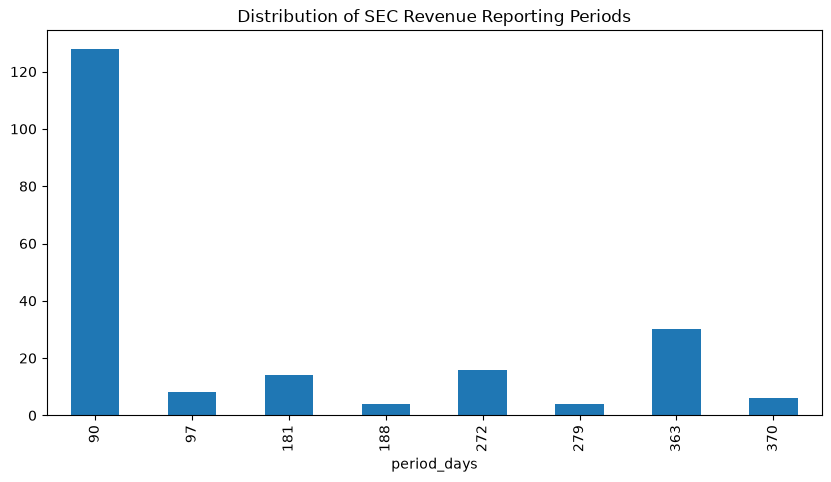

In [675]:
# Step 13: Plot period distribution
# Thought Process:
# A quick visual check shows the data naturally divides into two big clusters:
# 1) Quarterly reports around ~90 days
# 2) Full annual reports around ~365 days
revenue_df["period_days"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(10, 5),
    title="Distribution of SEC Revenue Reporting Periods"
)

### Step 14: Filter for Annual Periods (350 to 380 Days)
Use `filter_annual_periods` to keep only observations between 350 and 380 days.

In [676]:
# Step 14: Keep only ~1-year periods
# Thought Process:
# Apple's fiscal year is usually 52 or 53 weeks (roughly 364-371 days).
# Keeping rows between 350 and 380 days isolates all true annual reports and drops quarters.
annual_candidates = filter_annual_periods(revenue_df)

# Preview the filtered annual candidate rows
annual_candidates[
    ["start", "end", "period_days", "val", "form", "filed", "fy", "fp"]
].head(20)

,start,end,period_days,val,form,filed,fy,fp
0,2006-10-01,2007-09-29,363,24006000000,10-K,2009-10-27,2009.0,FY
1,2006-10-01,2007-09-29,363,24578000000,10-K/A,2010-01-25,2009.0,FY
4,2007-09-30,2008-09-27,363,32479000000,10-K,2009-10-27,2009.0,FY
5,2007-09-30,2008-09-27,363,37491000000,10-K/A,2010-01-25,2009.0,FY
6,2007-09-30,2008-09-27,363,37491000000,10-K,2010-10-27,2010.0,FY
17,2008-09-28,2009-09-26,363,36537000000,10-K,2009-10-27,2009.0,FY
18,2008-09-28,2009-09-26,363,42905000000,10-K/A,2010-01-25,2009.0,FY
19,2008-09-28,2009-09-26,363,42905000000,10-K,2010-10-27,2010.0,FY
20,2008-09-28,2009-09-26,363,42905000000,10-K,2011-10-26,2011.0,FY
38,2009-09-27,2010-09-25,363,65225000000,10-K,2010-10-27,2010.0,FY


### Step 15: Count Records Per Period
Count how many records exist for each unique year to see where duplicates remain.

In [677]:
# Step 15: Group by period
# Thought Process:
# For each 1-year period, count how many duplicate records exist.
# Some years will have 2 or 3 records because of subsequent comparative filings.
period_counts = (
    annual_candidates
    .groupby(["start", "end"])
    .size()
    .reset_index(name="record_count")
)
period_counts

,start,end,record_count
0,2006-10-01,2007-09-29,2
1,2007-09-30,2008-09-27,3
2,2008-09-28,2009-09-26,4
3,2009-09-27,2010-09-25,4
4,2010-09-26,2011-09-24,4
5,2011-09-25,2012-09-29,5
6,2012-09-30,2013-09-28,4
7,2013-09-29,2014-09-27,4
8,2014-09-28,2015-09-26,3
9,2015-09-27,2016-09-24,2


### Step 16: Check Comparative Filings (FY2009 Example)
See how Apple re-reported FY2009 in 2009, 2010, and 2011 filings.

In [678]:
# Step 16: FY2009 duplicates
# Thought Process:
# Why do duplicates exist? When companies file their 10-K, they usually include the 
# past 2-3 years for side-by-side comparison. For example, FY2009 was reported in 2009,
# 2010, and 2011. Let's see all entries for that single period to understand the differences.
annual_candidates[
    (annual_candidates["start"] == "2008-09-28") &
    (annual_candidates["end"] == "2009-09-26")
][["start", "end", "val", "form", "filed", "fy", "fp", "frame"]].sort_values("filed")

,start,end,val,form,filed,fy,fp,frame
17,2008-09-28,2009-09-26,36537000000,10-K,2009-10-27,2009.0,FY,NaN
18,2008-09-28,2009-09-26,42905000000,10-K/A,2010-01-25,2009.0,FY,NaN
19,2008-09-28,2009-09-26,42905000000,10-K,2010-10-27,2010.0,FY,NaN
20,2008-09-28,2009-09-26,42905000000,10-K,2011-10-26,2011.0,FY,CY2009


### Step 17: View All Annual Candidates Sorted by Date
Sort by start date and filing date to see all candidates chronologically.

In [679]:
# Step 17: Sort candidates
# Thought Process:
# Order the records by date so we can inspect how filings evolved over time.
annual_candidates[
    ["start", "end", "val", "form", "filed", "fy", "fp"]
].sort_values(["start", "filed"])

,start,end,val,form,filed,fy,fp
0,2006-10-01,2007-09-29,24006000000,10-K,2009-10-27,2009.0,FY
1,2006-10-01,2007-09-29,24578000000,10-K/A,2010-01-25,2009.0,FY
4,2007-09-30,2008-09-27,32479000000,10-K,2009-10-27,2009.0,FY
5,2007-09-30,2008-09-27,37491000000,10-K/A,2010-01-25,2009.0,FY
6,2007-09-30,2008-09-27,37491000000,10-K,2010-10-27,2010.0,FY
17,2008-09-28,2009-09-26,36537000000,10-K,2009-10-27,2009.0,FY
18,2008-09-28,2009-09-26,42905000000,10-K/A,2010-01-25,2009.0,FY
19,2008-09-28,2009-09-26,42905000000,10-K,2010-10-27,2010.0,FY
20,2008-09-28,2009-09-26,42905000000,10-K,2011-10-26,2011.0,FY
38,2009-09-27,2010-09-25,65225000000,10-K,2010-10-27,2010.0,FY


### Step 18: Deduplication (Keep Latest Filing Date)
Sort by start, end, and filed date, keeping only the most recent record for each period.

In [680]:
# Step 18: Deduplicate by latest filing
# Thought Process:
# First simple deduplication attempt: For any given financial year, if there are multiple filings,
# keep the most recently filed one (since newer filings often contain corrections or restatements).
annual_clean = (
    annual_candidates
    .sort_values(["start", "end", "filed"])
    .drop_duplicates(subset=["start", "end"], keep="last")
    .copy()
)

### Step 19: Inspect Cleaned Annual Data
Check the cleaned annual table and verify row reduction.

In [681]:
# Step 19: Verify cleaned data
# Thought Process:
# Validate our first deduplication: confirm row count dropped to exactly 1 record per year,
# and check which forms were preserved.
print("Rows before cleaning:", len(annual_candidates))
print("Rows after cleaning:", len(annual_clean))
print("\nForm distribution:")
print(annual_clean["form"].value_counts())

# Preview the clean table sorted from oldest to newest year
annual_clean[["start", "end", "val", "form", "filed"]].sort_values("start")

Rows before cleaning: 36
Rows after cleaning: 11

Form distribution:
form
10-K      8
8-K       2
10-K/A    1
Name: count, dtype: int64


,start,end,val,form,filed
1,2006-10-01,2007-09-29,24578000000,10-K/A,2010-01-25
6,2007-09-30,2008-09-27,37491000000,10-K,2010-10-27
20,2008-09-28,2009-09-26,42905000000,10-K,2011-10-26
41,2009-09-27,2010-09-25,65225000000,8-K,2013-04-24
66,2010-09-26,2011-09-24,108249000000,10-K,2013-10-30
93,2011-09-25,2012-09-29,156508000000,8-K,2015-01-28
119,2012-09-30,2013-09-28,170910000000,10-K,2015-10-28
145,2013-09-29,2014-09-27,182795000000,10-K,2016-10-26
167,2014-09-28,2015-09-26,233715000000,10-K,2017-11-03
187,2015-09-27,2016-09-24,215639000000,10-K,2017-11-03


### Step 20: Apply Form Priority Hierarchy
Use `apply_filing_priority` and `select_one_record_per_period` to give highest priority to 10-K/A, then 10-K, then 8-K.

In [682]:
# Step 20: Form priority selection
# Thought Process:
# A more robust deduplication rule:
# 1. 10-K/A (amended report) is most trusted (Rank 1).
# 2. 10-K (official audited annual report) is next (Rank 2).
# 3. 8-K is lowest priority (Rank 3).
# If tied, pick the latest filing date.
annual_candidates = apply_filing_priority(annual_candidates)
annual_clean = select_one_record_per_period(annual_candidates)

# Check the final deduplicated revenue records with their assigned form priority
annual_clean[["start", "end", "val", "form", "filed", "form_priority"]]

,start,end,val,form,filed,form_priority
1,2006-10-01,2007-09-29,24578000000,10-K/A,2010-01-25,1
5,2007-09-30,2008-09-27,37491000000,10-K/A,2010-01-25,1
18,2008-09-28,2009-09-26,42905000000,10-K/A,2010-01-25,1
40,2009-09-27,2010-09-25,65225000000,10-K,2012-10-31,2
66,2010-09-26,2011-09-24,108249000000,10-K,2013-10-30,2
92,2011-09-25,2012-09-29,156508000000,10-K,2014-10-27,2
119,2012-09-30,2013-09-28,170910000000,10-K,2015-10-28,2
145,2013-09-29,2014-09-27,182795000000,10-K,2016-10-26,2
167,2014-09-28,2015-09-26,233715000000,10-K,2017-11-03,2
187,2015-09-27,2016-09-24,215639000000,10-K,2017-11-03,2


### Step 21: Convert Revenue to Billions & Calculate YoY Growth
Convert nominal values to billions ($B) and compute year-over-year revenue growth percentage.

In [683]:
# Step 21: Revenue in billions & growth %
# Thought Process:
# Raw numbers like $394,328,000,000 are hard to read at a glance.
# Dividing by 1 billion converts them into clean, human-readable numbers (e.g. $394.33B).
# Then calculate Year-over-Year (YoY) percentage change to see how fast Apple grew each year.
annual_clean["revenue_billion"] = annual_clean["val"] / 1_000_000_000
annual_clean = annual_clean.sort_values("end").copy()

# YoY growth = (current year - previous year) / previous year * 100
annual_clean["revenue_growth_pct"] = annual_clean["revenue_billion"].pct_change() * 100

# Preview end dates, revenue in billions, and growth rate rounded to 2 decimal places
annual_clean[["end", "revenue_billion", "revenue_growth_pct"]].round({"revenue_billion": 2, "revenue_growth_pct": 2})

,end,revenue_billion,revenue_growth_pct
1,2007-09-29,24.58,NaN
5,2008-09-27,37.49,52.54
18,2009-09-26,42.90,14.44
40,2010-09-25,65.22,52.02
66,2011-09-24,108.25,65.96
92,2012-09-29,156.51,44.58
119,2013-09-28,170.91,9.20
145,2014-09-27,182.80,6.95
167,2015-09-26,233.72,27.86
187,2016-09-24,215.64,-7.73


### Step 22: Plot Annual Revenue Trend
Plot a line chart of Apple's historical annual revenue.

<Axes: title={'center': 'Apple Annual Revenue Trend ($ Billions)'}, xlabel='end'>

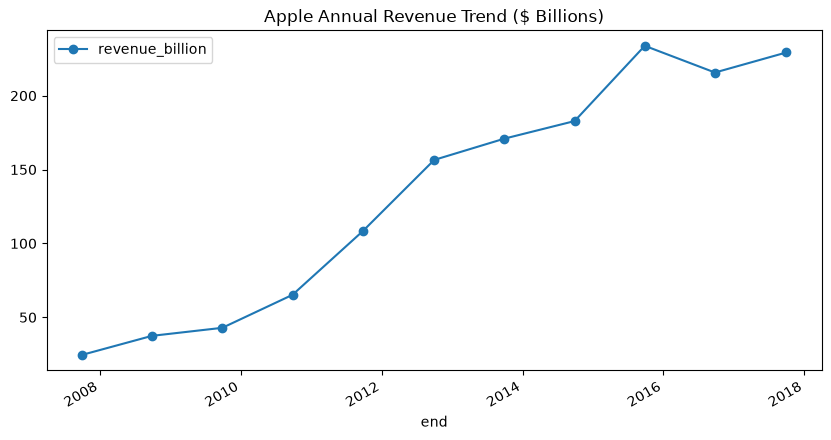

In [684]:
# Step 22: Plot revenue trend
# Thought Process:
# Visualize the growth trajectory over the past decade or two with a clean line chart.
annual_clean.plot(
    x="end",
    y="revenue_billion",
    kind="line",
    marker="o",
    figsize=(10, 5),
    title="Apple Annual Revenue Trend ($ Billions)"
)

### Step 23: Save Cleaned Data to CSV
Save the final cleaned DataFrame to `data/cleaned/apple_annual_revenue.csv`.

In [685]:
# Step 23: Export to CSV
# Thought Process:
# Save the polished, deduplicated revenue table to CSV for downstream reporting (e.g. Power BI, dashboards).
export_path = "../data/cleaned/apple_annual_revenue.csv"
annual_clean.to_csv(export_path, index=False)
print("Saved to CSV:", os.path.exists(export_path))

Saved to CSV: True


### Step 24: Search Other Financial Concepts in XBRL Data
Search all accounting concepts in the data for revenue, cost, gross profit, operating income, and net income.

In [686]:
# Step 24: Concept search
# Thought Process:
# To build a full Income Statement, we need more than just Revenue.
# We also want Operating Income and Net Income (bottom line profit).
# Let's search all tags in the SEC file to find the official accounting names.
for namespace, concepts in data["facts"].items():
    print(f"\n--- {namespace} ---")
    for concept_name, concept_data in concepts.items():
        label = concept_data.get("label") or ""
        search_text = (str(concept_name) + " " + str(label)).lower()
        # Look for key financial keywords
        if any(k in search_text for k in ["revenue", "cost", "gross profit", "operating income", "net income"]):
            print(f"{concept_name} -> {label}")


--- dei ---

--- us-gaap ---
AccruedMarketingCostsCurrent -> Accrued Marketing Costs, Current
AdjustmentsToAdditionalPaidInCapitalSharebasedCompensationRequisiteServicePeriodRecognitionValue -> APIC, Share-based Payment Arrangement, Increase for Cost Recognition
AvailableForSaleDebtSecuritiesAmortizedCostBasis -> Debt Securities, Available-for-sale, Amortized Cost
AvailableForSaleSecuritiesAmortizedCost -> Available-for-sale Securities, Amortized Cost Basis
BusinessAcquisitionCostOfAcquiredEntityPurchasePrice -> Business Acquisition, Cost of Acquired Entity, Purchase Price (Deprecated 2013-01-31)
ContractWithCustomerLiabilityRevenueRecognized -> Contract with Customer, Liability, Revenue Recognized
CostOfGoodsAndServicesSold -> Cost of Goods and Services Sold
CostOfGoodsAndServicesSoldDepreciation -> Cost, Depreciation
CostOfReimbursableExpense -> Cost of Reimbursable Expense (Deprecated 2018-01-31)
DebtInstrumentUnamortizedDiscountPremiumAndDebtIssuanceCostsNet -> Debt Instrument, Un

### Step 25: Extract Net Income & Operating Income DataFrames
Extract the raw USD observations for both Net Income (`NetIncomeLoss`) and Operating Income (`OperatingIncomeLoss`).

In [687]:
# Step 25: Net Income and Operating Income DataFrames
# Thought Process:
# From Step 24, we identified the two standard US-GAAP concepts:
# 1. 'NetIncomeLoss' for Apple's bottom-line net profit.
# 2. 'OperatingIncomeLoss' for Apple's core operational profit.
# We extract their USD observations and put each into its own DataFrame.
net_income_data = data["facts"]["us-gaap"]["NetIncomeLoss"]
net_income_df = pd.DataFrame(net_income_data["units"]["USD"])

operating_income_data = data["facts"]["us-gaap"]["OperatingIncomeLoss"]
operating_income_df = pd.DataFrame(operating_income_data["units"]["USD"])

print("Net income rows:", len(net_income_df))
print("Operating income rows:", len(operating_income_df))

Net income rows: 338
Operating income rows: 234


### Step 26: Add Period Days to Operating Income & Net Income
Calculate period duration in days for both datasets using `add_period_days`.

In [688]:
# Step 26: Add period_days to other concepts
# Thought Process:
# Just like we did with Revenue, calculate the real number of days between start and end
# to separate annual periods from quarterly periods.
operating_income_df = add_period_days(operating_income_df)
net_income_df = add_period_days(net_income_df)

### Step 27: Check Period Distribution for Operating Income & Net Income
Verify that reporting period lengths for operating income and net income also cluster around 90 days and 365 days.

In [689]:
# Step 27: Check period distribution
# Thought Process:
# Confirm that operating income and net income follow the exact same period patterns
# (clusters around ~90 days for quarters and ~365 days for full fiscal years).
print("Operating Income:")
print(
    operating_income_df["period_days"]
    .value_counts()
    .sort_index()
)

print("\nNet Income:")
print(
    net_income_df["period_days"]
    .value_counts()
    .sort_index()
)

Operating Income:
period_days
90     98
97      6
181    28
188     6
272    30
279     6
363    49
370    11
Name: count, dtype: int64

Net Income:
period_days
90     197
97      11
181     28
188      6
272     30
279      6
363     49
370     11
Name: count, dtype: int64


### Step 28: Filter Annual Periods for Operating Income & Net Income
Filter for ~1-year periods (350 to 380 days) on both datasets using `filter_annual_periods`.

In [690]:
# Step 28: Keep only annual periods (~365 days)
# Thought Process:
# Filter rows between 350 and 380 days so we only keep full-year annual financial numbers.
annual_operating_income = filter_annual_periods(
    operating_income_df
)

annual_net_income = filter_annual_periods(
    net_income_df
)

### Step 29: Count Annual Candidate Rows
Check how many annual candidate rows were extracted for Operating Income and Net Income.

In [691]:
# Step 29: Check candidate row counts
# Thought Process:
# Check the raw candidate counts before deduplicating.
print("Annual Operating Income records:",
      len(annual_operating_income))

print("Annual Net Income records:",
      len(annual_net_income))

Annual Operating Income records: 60
Annual Net Income records: 60


### Step 30: Count Unique Annual Reporting Periods
Count unique `(start, end)` periods to verify how many distinct years exist before deduplication.

In [692]:
# Step 30: Count unique periods
# Thought Process:
# Count how many unique financial years exist in the data.
# This tells us the expected row count once duplicates are removed.
print(
    "Unique Operating Income periods:",
    annual_operating_income[["start", "end"]]
    .drop_duplicates()
    .shape[0]
)

print(
    "Unique Net Income periods:",
    annual_net_income[["start", "end"]]
    .drop_duplicates()
    .shape[0]
)

Unique Operating Income periods: 19
Unique Net Income periods: 19


### Step 31: Assign Form Priority to Candidates
Map form priority (10-K/A = 1, 10-K = 2, 8-K = 3) using `apply_filing_priority`.

In [693]:
# Step 31: Apply form priority
# Thought Process:
# Use the exact same trust ranking rules as Revenue:
# Priority 1: 10-K/A (amendments/corrections)
# Priority 2: 10-K (official audited annual report)
# Priority 3: 8-K (interim filings)
annual_operating_income = apply_filing_priority(
    annual_operating_income
)

annual_net_income = apply_filing_priority(
    annual_net_income
)

### Step 32: Inspect Form Breakdown for Annual Candidates
Check how many 10-K, 10-K/A, and 8-K filings exist in the annual candidate datasets.

In [694]:
# Step 32: Check forms in candidates
# Thought Process:
# Review which filing types are present in both candidate pools.
print("Operating Income:")
print(
    annual_operating_income["form"]
    .value_counts()
)

print("\nNet Income:")
print(
    annual_net_income["form"]
    .value_counts()
)

Operating Income:
form
10-K      51
8-K        6
10-K/A     3
Name: count, dtype: int64

Net Income:
form
10-K      51
8-K        6
10-K/A     3
Name: count, dtype: int64


### Step 33: Preview Annual Operating Income Candidates
Inspect the first 20 records of annual Operating Income with form priorities.

In [695]:
# Step 33: Preview Operating Income candidates
# Thought Process:
# Visually check the first 20 rows of Operating Income before deduplication.
annual_operating_income[
    ["start", "end", "val", "form", "filed", "form_priority"]
].head(20)

,start,end,val,form,filed,form_priority
0,2006-10-01,2007-09-29,4409000000,10-K,2009-10-27,2
1,2006-10-01,2007-09-29,4407000000,10-K/A,2010-01-25,1
4,2007-09-30,2008-09-27,6275000000,10-K,2009-10-27,2
5,2007-09-30,2008-09-27,8327000000,10-K/A,2010-01-25,1
6,2007-09-30,2008-09-27,8327000000,10-K,2010-10-27,2
14,2008-09-28,2009-09-26,7658000000,10-K,2009-10-27,2
15,2008-09-28,2009-09-26,11740000000,10-K/A,2010-01-25,1
16,2008-09-28,2009-09-26,11740000000,10-K,2010-10-27,2
17,2008-09-28,2009-09-26,11740000000,10-K,2011-10-26,2
28,2009-09-27,2010-09-25,18385000000,10-K,2010-10-27,2


### Step 34: Preview Annual Net Income Candidates
Inspect the first 20 records of annual Net Income with form priorities.

In [696]:
# Step 34: Preview Net Income candidates
# Thought Process:
# Visually check the first 20 rows of Net Income before deduplication.
annual_net_income[
    ["start", "end", "val", "form", "filed", "form_priority"]
].head(20)

,start,end,val,form,filed,form_priority
0,2006-10-01,2007-09-29,3496000000,10-K,2009-10-27,2
1,2006-10-01,2007-09-29,3495000000,10-K/A,2010-01-25,1
4,2007-09-30,2008-09-27,4834000000,10-K,2009-10-27,2
5,2007-09-30,2008-09-27,6119000000,10-K/A,2010-01-25,1
6,2007-09-30,2008-09-27,6119000000,10-K,2010-10-27,2
17,2008-09-28,2009-09-26,5704000000,10-K,2009-10-27,2
18,2008-09-28,2009-09-26,8235000000,10-K/A,2010-01-25,1
19,2008-09-28,2009-09-26,8235000000,10-K,2010-10-27,2
20,2008-09-28,2009-09-26,8235000000,10-K,2011-10-26,2
38,2009-09-27,2010-09-25,14013000000,10-K,2010-10-27,2


### Step 35: Deduplicate Operating Income & Net Income
Use `select_one_record_per_period` to select exactly one authoritative record per financial period.

In [697]:
# Step 35: Deduplicate using priority rules
# Thought Process:
# For every annual period (start to end), keep only the single best record
# (highest filing priority, newest filing date).
annual_operating_income_clean = select_one_record_per_period(
    annual_operating_income
)

annual_net_income_clean = select_one_record_per_period(
    annual_net_income
)

### Step 36: Check Cleaned Record Counts
Verify the final cleaned row counts for Operating Income and Net Income.

In [698]:
# Step 36: Verify row counts
# Thought Process:
# Confirm that each dataset now has one row per year, matching our expected unique periods.
print(
    "Operating Income records:",
    len(annual_operating_income_clean)
)

print(
    "Net Income records:",
    len(annual_net_income_clean)
)

Operating Income records: 19
Net Income records: 19


### Step 37: Verify Zero Duplicate Periods
Check that there are 0 duplicate `(start, end)` pairs remaining in both cleaned datasets.

In [699]:
# Step 37: Sanity check for duplicates
# Thought Process:
# Verify that the duplicate count is strictly 0. 
# If duplicates remained, downstream merges would create incorrect duplicate rows.
print(
    "Duplicate Operating Income periods:",
    annual_operating_income_clean
    .duplicated(subset=["start", "end"])
    .sum()
)

print(
    "Duplicate Net Income periods:",
    annual_net_income_clean
    .duplicated(subset=["start", "end"])
    .sum()
)

Duplicate Operating Income periods: 0
Duplicate Net Income periods: 0


### Step 38: Compare Cleaned Period Counts Across All 3 Metrics
Check total periods available for Revenue, Operating Income, and Net Income.

In [700]:
# Step 38: Compare total periods
# Thought Process:
# Before combining tables, check how many years each metric spans.
# We want to know if all three metrics cover the exact same number of years.
print("Revenue periods:",
      len(annual_clean))

print("Operating Income periods:",
      len(annual_operating_income_clean))

print("Net Income periods:",
      len(annual_net_income_clean))

Revenue periods: 11
Operating Income periods: 19
Net Income periods: 19


### Step 39: Check Period Alignment (Intersection of Periods)
Use set intersections to verify that all three metrics share the exact same annual reporting periods.

In [701]:
# Step 39: Check set overlap
# Thought Process:
# Even if counts match, do they represent the *exact same* fiscal years?
# Using set intersection (comparing (start, end) pairs) proves that all three metrics align perfectly.
revenue_periods = set(
    zip(annual_clean["start"], annual_clean["end"])
)

operating_income_periods = set(
    zip(
        annual_operating_income_clean["start"],
        annual_operating_income_clean["end"]
    )
)

net_income_periods = set(
    zip(
        annual_net_income_clean["start"],
        annual_net_income_clean["end"]
    )
)

print(
    "Revenue & Operating Income overlap:",
    len(revenue_periods & operating_income_periods)
)

print(
    "Revenue & Net Income overlap:",
    len(revenue_periods & net_income_periods)
)

print(
    "Operating Income & Net Income overlap:",
    len(
        operating_income_periods
        & net_income_periods
    )
)

Revenue & Operating Income overlap: 11
Revenue & Net Income overlap: 11
Operating Income & Net Income overlap: 19


### Step 40: Prepare Final Revenue Table
Select only `start`, `end`, and rename `val` to `revenue`.

In [702]:
# Step 40: Clean Revenue subset
# Thought Process:
# Strip away metadata columns (like form, frame, filed) and keep only the essentials:
# start date, end date, and the dollar amount renamed cleanly to 'revenue'.
revenue_final = annual_clean[
    ["start", "end", "val"]
].copy()

revenue_final = revenue_final.rename(
    columns={"val": "revenue"}
)

### Step 41: Prepare Final Operating Income Table
Select only `start`, `end`, and rename `val` to `operating_income`.

In [703]:
# Step 41: Clean Operating Income subset
# Thought Process:
# Keep start date, end date, and rename the value to 'operating_income'.
operating_income_final = annual_operating_income_clean[
    ["start", "end", "val"]
].copy()

operating_income_final = operating_income_final.rename(
    columns={"val": "operating_income"}
)

### Step 42: Prepare Final Net Income Table
Select only `start`, `end`, and rename `val` to `net_income`.

In [704]:
# Step 42: Clean Net Income subset
# Thought Process:
# Keep start date, end date, and rename the value to 'net_income'.
net_income_final = annual_net_income_clean[
    ["start", "end", "val"]
].copy()

net_income_final = net_income_final.rename(
    columns={"val": "net_income"}
)

### Step 43: Merge Metrics into Consolidated Income Statement Table
Perform inner joins on `start` and `end` dates to combine Revenue, Operating Income, and Net Income into `income_statement_df`.

In [705]:
# Step 43: Merge all 3 tables
# Thought Process:
# Now combine all 3 clean tables together:
# 1. Match Revenue with Operating Income using start and end dates.
# 2. Match the result with Net Income using start and end dates.
# 3. Sort chronologically by the fiscal year end date.
# Result: A single row for each year with Revenue, Operating Income, and Net Income side-by-side.
income_statement_df = (
    revenue_final
    .merge(
        operating_income_final,
        on=["start", "end"],
        how="inner"
    )
    .merge(
        net_income_final,
        on=["start", "end"],
        how="inner"
    )
    .sort_values("end")
    .reset_index(drop=True)
)

### Step 44: View Consolidated Income Statement Table
Display the final combined income statement dataset.

In [706]:
# Step 44: Preview final table
# Thought Process:
# Inspect our final consolidated Income Statement dataset.
income_statement_df

,start,end,revenue,operating_income,net_income
0,2006-10-01,2007-09-29,24578000000,4407000000,3495000000
1,2007-09-30,2008-09-27,37491000000,8327000000,6119000000
2,2008-09-28,2009-09-26,42905000000,11740000000,8235000000
3,2009-09-27,2010-09-25,65225000000,18385000000,14013000000
4,2010-09-26,2011-09-24,108249000000,33790000000,25922000000
5,2011-09-25,2012-09-29,156508000000,55241000000,41733000000
6,2012-09-30,2013-09-28,170910000000,48999000000,37037000000
7,2013-09-29,2014-09-27,182795000000,52503000000,39510000000
8,2014-09-28,2015-09-26,233715000000,71230000000,53394000000
9,2015-09-27,2016-09-24,215639000000,60024000000,45687000000


### Step 45: Check Final Table Dimensions
Verify total row count and column names of the merged table.

In [707]:
# Step 45: Final validation
# Thought Process:
# Final check to verify total number of years covered and confirm all expected columns are present.
print("Rows:", len(income_statement_df))
print("Columns:", income_statement_df.columns.tolist())

Rows: 11
Columns: ['start', 'end', 'revenue', 'operating_income', 'net_income']


### Step 46: Inspect Merged Income Statement Table
Display the consolidated table to inspect rows, columns, and data continuity.

In [708]:
# Step 46: Display income statement table
# Thought Process:
# Take another look at the combined income statement to confirm the columns
# (start, end, revenue, operating_income, net_income) are populated correctly.
income_statement_df

,start,end,revenue,operating_income,net_income
0,2006-10-01,2007-09-29,24578000000,4407000000,3495000000
1,2007-09-30,2008-09-27,37491000000,8327000000,6119000000
2,2008-09-28,2009-09-26,42905000000,11740000000,8235000000
3,2009-09-27,2010-09-25,65225000000,18385000000,14013000000
4,2010-09-26,2011-09-24,108249000000,33790000000,25922000000
5,2011-09-25,2012-09-29,156508000000,55241000000,41733000000
6,2012-09-30,2013-09-28,170910000000,48999000000,37037000000
7,2013-09-29,2014-09-27,182795000000,52503000000,39510000000
8,2014-09-28,2015-09-26,233715000000,71230000000,53394000000
9,2015-09-27,2016-09-24,215639000000,60024000000,45687000000


### Step 47: Check for Missing (Null) Values
Verify data completeness across all financial years.

In [709]:
# Step 47: Null values check
# Thought Process:
# A reliable financial pipeline must have zero missing values.
# If any value is NaN, it means one of our merges failed to find matching dates.
income_statement_df.isna().sum()

start               0
end                 0
revenue             0
operating_income    0
net_income          0
dtype: int64

### Step 48: Check for Duplicate Financial Years
Verify that each financial reporting period appears exactly once.

In [710]:
# Step 48: Duplicate check
# Thought Process:
# Confirm that each (start, end) period appears only once in the merged dataset.
income_statement_df.duplicated(
    subset=["start", "end"]
).sum()

np.int64(0)

### Step 49: Inspect Cost of Goods Sold (COGS) Metadata
Explore the US-GAAP concept `CostOfGoodsAndServicesSold`.

In [711]:
# Step 49: COGS concept lookup
# Thought Process:
# To compute Gross Profit (Revenue minus Cost of Goods Sold), we need COGS.
# In US-GAAP, Apple reports this under 'CostOfGoodsAndServicesSold'.
cogs_data = data["facts"]["us-gaap"]["CostOfGoodsAndServicesSold"]

print("Label:", cogs_data["label"])
print("Available units:", cogs_data["units"].keys())

Label: Cost of Goods and Services Sold
Available units: dict_keys(['USD'])


### Step 50: Re-verify COGS Concept Metadata
Double check the concept units and label.

In [712]:
# Step 50: Confirm COGS details
# Thought Process:
# Confirm that USD observations are available for Cost of Goods Sold.
cogs_data = data["facts"]["us-gaap"]["CostOfGoodsAndServicesSold"]

print("Label:", cogs_data["label"])
print("Available units:", cogs_data["units"].keys())

Label: Cost of Goods and Services Sold
Available units: dict_keys(['USD'])


### Step 51: Extract USD Observations for COGS
Load COGS observations into a DataFrame and preview the first 10 rows.

In [713]:
# Step 51: Extract COGS data
# Thought Process:
# Pull all observations reported in USD into a pandas DataFrame.
cogs_observations = cogs_data["units"]["USD"]

cogs_df = pd.DataFrame(cogs_observations)

# Preview first 10 rows
cogs_df.head(10)

,start,end,val,accn,fy,fp,form,filed,frame
0,2006-10-01,2007-09-29,15852000000,0001193125-09-214859,2009.0,FY,10-K,2009-10-27,NaN
1,2006-10-01,2007-09-29,16426000000,0001193125-10-012091,2009.0,FY,10-K/A,2010-01-25,CY2007
2,2007-09-30,2008-06-28,16178000000,0001193125-09-153165,2009.0,Q3,10-Q,2009-07-22,NaN
3,2008-03-30,2008-06-28,4864000000,0001193125-09-153165,2009.0,Q3,10-Q,2009-07-22,CY2008Q2
4,2007-09-30,2008-09-27,21334000000,0001193125-09-214859,2009.0,FY,10-K,2009-10-27,NaN
5,2007-09-30,2008-09-27,24294000000,0001193125-10-012091,2009.0,FY,10-K/A,2010-01-25,NaN
6,2007-09-30,2008-09-27,24294000000,0001193125-10-238044,2010.0,FY,10-K,2010-10-27,CY2008
7,2008-09-28,2008-12-27,7373000000,0001193125-10-012085,2010.0,Q1,10-Q,2010-01-25,CY2008Q4
8,2008-09-28,2009-03-28,12830000000,0001193125-10-088957,2010.0,Q2,10-Q,2010-04-21,NaN
9,2008-12-28,2009-03-28,5457000000,0001193125-10-088957,2010.0,Q2,10-Q,2010-04-21,CY2009Q1


### Step 52: Calculate COGS Reporting Period Length in Days
Calculate elapsed days between start and end dates using `add_period_days`.

In [714]:
# Step 52: Add period duration in days
# Thought Process:
# As with Revenue, we calculate elapsed days to differentiate quarterly filings (~90 days)
# from full-year annual filings (~365 days).
cogs_df = add_period_days(cogs_df)

### Step 53: Inspect COGS Period Distribution
Check how reporting period lengths cluster across quarters and years.

In [715]:
# Step 53: Period distribution check
# Thought Process:
# Confirm that COGS durations fall neatly into quarterly and annual clusters.
cogs_df["period_days"].value_counts().sort_index()

period_days
90     98
97      6
181    28
188     6
272    30
279     6
363    49
370    11
Name: count, dtype: int64

### Step 54: Preview Annual COGS Period Filtering
Test filtering for periods between 350 and 380 days.

In [716]:
# Step 54: Test annual filter
# Thought Process:
# Test our annual filter (350 to 380 days) to make sure it captures the 1-year reports.
filter_annual_periods(cogs_df)

,start,end,val,accn,fy,fp,form,filed,frame,period_days
0,2006-10-01,2007-09-29,15852000000,0001193125-09-214859,2009.0,FY,10-K,2009-10-27,NaN,363
1,2006-10-01,2007-09-29,16426000000,0001193125-10-012091,2009.0,FY,10-K/A,2010-01-25,CY2007,363
4,2007-09-30,2008-09-27,21334000000,0001193125-09-214859,2009.0,FY,10-K,2009-10-27,NaN,363
5,2007-09-30,2008-09-27,24294000000,0001193125-10-012091,2009.0,FY,10-K/A,2010-01-25,NaN,363
6,2007-09-30,2008-09-27,24294000000,0001193125-10-238044,2010.0,FY,10-K,2010-10-27,CY2008,363
14,2008-09-28,2009-09-26,23397000000,0001193125-09-214859,2009.0,FY,10-K,2009-10-27,NaN,363
15,2008-09-28,2009-09-26,25683000000,0001193125-10-012091,2009.0,FY,10-K/A,2010-01-25,NaN,363
16,2008-09-28,2009-09-26,25683000000,0001193125-10-238044,2010.0,FY,10-K,2010-10-27,NaN,363
17,2008-09-28,2009-09-26,25683000000,0001193125-11-282113,2011.0,FY,10-K,2011-10-26,CY2009,363
28,2009-09-27,2010-09-25,39541000000,0001193125-10-238044,2010.0,FY,10-K,2010-10-27,NaN,363


### Step 55: Filter COGS for Annual Periods
Isolate ~1-year financial observations into `annual_cogs`.

In [717]:
# Step 55: Store annual COGS candidates
# Thought Process:
# Save the filtered annual observations into annual_cogs.
annual_cogs = filter_annual_periods(cogs_df)

### Step 56: Confirm Annual COGS Candidates
Ensure annual candidates are properly assigned.

In [718]:
# Step 56: Confirm candidate assignment
# Thought Process:
# Ensure annual_cogs is ready for priority scoring.
annual_cogs = filter_annual_periods(cogs_df)

### Step 57: Count Total vs Unique Annual COGS Records
Compare total candidate rows with unique annual reporting periods.

In [719]:
# Step 57: Check candidate counts vs unique periods
# Thought Process:
# Total records will exceed unique periods because companies re-report past years in subsequent 10-Ks.
print("Annual COGS records:", len(annual_cogs))

print(
    "Unique COGS periods:",
    annual_cogs[["start", "end"]]
    .drop_duplicates()
    .shape[0]
)

Annual COGS records: 60
Unique COGS periods: 19


### Step 58: Apply Filing Priority to COGS Candidates
Assign priority ranks (10-K/A = 1, 10-K = 2, 8-K = 3) using `apply_filing_priority`.

In [720]:
# Step 58: Assign priority ranks
# Thought Process:
# Apply our trust ranking: 10-K/A (amendments) > 10-K (official annuals) > 8-K (interim).
annual_cogs = apply_filing_priority(annual_cogs)

### Step 59: Preview Annual COGS with Priority Rankings
Inspect candidate rows showing values, forms, and priority ranks.

In [721]:
# Step 59: Preview top candidates
# Thought Process:
# Inspect the first 20 rows of annual COGS candidates with priority rankings.
annual_cogs[
    ["start", "end", "val", "form", "filed", "form_priority"]
].head(20)

,start,end,val,form,filed,form_priority
0,2006-10-01,2007-09-29,15852000000,10-K,2009-10-27,2
1,2006-10-01,2007-09-29,16426000000,10-K/A,2010-01-25,1
4,2007-09-30,2008-09-27,21334000000,10-K,2009-10-27,2
5,2007-09-30,2008-09-27,24294000000,10-K/A,2010-01-25,1
6,2007-09-30,2008-09-27,24294000000,10-K,2010-10-27,2
14,2008-09-28,2009-09-26,23397000000,10-K,2009-10-27,2
15,2008-09-28,2009-09-26,25683000000,10-K/A,2010-01-25,1
16,2008-09-28,2009-09-26,25683000000,10-K,2010-10-27,2
17,2008-09-28,2009-09-26,25683000000,10-K,2011-10-26,2
28,2009-09-27,2010-09-25,39541000000,10-K,2010-10-27,2


### Step 60: Deduplicate Annual COGS Records
Select the single most authoritative COGS observation per reporting period.

In [722]:
# Step 60: Deduplicate COGS
# Thought Process:
# Pick the best record for each (start, end) period using form priority and latest filing date.
annual_cogs_clean = select_one_record_per_period(
    annual_cogs
)

### Step 61: Verify Cleaned COGS Records
Verify total row count and confirm zero duplicate periods.

In [723]:
# Step 61: Validate deduplication results
# Thought Process:
# Ensure deduplication produced exactly one row per financial year and zero duplicate periods.
print(
    "Annual COGS clean records:",
    len(annual_cogs_clean)
)

print(
    "Duplicate periods:",
    annual_cogs_clean
    .duplicated(subset=["start", "end"])
    .sum()
)

Annual COGS clean records: 19
Duplicate periods: 0


### Step 62: View Cleaned Annual COGS Dataset
Display all cleaned annual COGS records.

In [724]:
# Step 62: Display cleaned COGS
# Thought Process:
# Inspect the final deduplicated COGS table.
annual_cogs_clean[
    ["start", "end", "val", "form", "filed"]
]

,start,end,val,form,filed
1,2006-10-01,2007-09-29,16426000000,10-K/A,2010-01-25
5,2007-09-30,2008-09-27,24294000000,10-K/A,2010-01-25
15,2008-09-28,2009-09-26,25683000000,10-K/A,2010-01-25
30,2009-09-27,2010-09-25,39541000000,10-K,2012-10-31
45,2010-09-26,2011-09-24,64431000000,10-K,2013-10-30
59,2011-09-25,2012-09-29,87846000000,10-K,2014-10-27
74,2012-09-30,2013-09-28,106606000000,10-K,2015-10-28
88,2013-09-29,2014-09-27,112258000000,10-K,2016-10-26
101,2014-09-28,2015-09-26,140089000000,10-K,2017-11-03
114,2015-09-27,2016-09-24,131376000000,10-K,2018-11-05


### Step 63: Check Period Overlap Between COGS and Income Statement
Use set intersection to verify how many periods match.

In [725]:
# Step 63: Period overlap check
# Thought Process:
# Compare the financial periods of COGS with our existing income statement table
# to make sure they cover the exact same timeframes.
cogs_periods = set(
    zip(
        annual_cogs_clean["start"],
        annual_cogs_clean["end"]
    )
)

income_statement_periods = set(
    zip(
        income_statement_df["start"],
        income_statement_df["end"]
    )
)

print(
    "COGS ∩ Income Statement:",
    len(cogs_periods & income_statement_periods)
)

COGS ∩ Income Statement: 11


### Step 64: Identify Any Missing COGS Periods
Check if any income statement years are missing from COGS.

In [726]:
# Step 64: Check missing periods
# Thought Process:
# Check if any year present in the income statement is absent in COGS.
missing_cogs_periods = (
    income_statement_periods - cogs_periods
)

print("Missing COGS periods:")
print(missing_cogs_periods)

Missing COGS periods:
set()


### Step 65: Prepare Final COGS Table
Select `start`, `end`, and rename `val` to `cogs`.

In [727]:
# Step 65: Prepare clean COGS subset
# Thought Process:
# Retain only start date, end date, and the dollar amount renamed cleanly to 'cogs'.
cogs_final = annual_cogs_clean[
    ["start", "end", "val"]
].copy()

cogs_final = cogs_final.rename(
    columns={"val": "cogs"}
)

### Step 66: Merge COGS into Consolidated Income Statement
Perform inner join on `start` and `end` dates to attach COGS.

In [728]:
# Step 66: Merge COGS into income statement
# Thought Process:
# Join COGS onto the income statement so all four core metrics sit together.
income_statement_df = income_statement_df.merge(
    cogs_final,
    on=["start", "end"],
    how="inner"
)

### Step 67: Sort Income Statement Chronologically
Order rows by fiscal year end date.

In [729]:
# Step 67: Sort by end date
# Thought Process:
# Keep rows organized chronologically from oldest to newest fiscal year.
income_statement_df = (
    income_statement_df
    .sort_values("end")
    .reset_index(drop=True)
)

### Step 68: View Updated Income Statement Table
Display the income statement table now including COGS.

In [730]:
# Step 68: Display updated income statement
# Thought Process:
# Preview the table with Revenue, Operating Income, Net Income, and COGS.
income_statement_df

,start,end,revenue,operating_income,net_income,cogs
0,2006-10-01,2007-09-29,24578000000,4407000000,3495000000,16426000000
1,2007-09-30,2008-09-27,37491000000,8327000000,6119000000,24294000000
2,2008-09-28,2009-09-26,42905000000,11740000000,8235000000,25683000000
3,2009-09-27,2010-09-25,65225000000,18385000000,14013000000,39541000000
4,2010-09-26,2011-09-24,108249000000,33790000000,25922000000,64431000000
5,2011-09-25,2012-09-29,156508000000,55241000000,41733000000,87846000000
6,2012-09-30,2013-09-28,170910000000,48999000000,37037000000,106606000000
7,2013-09-29,2014-09-27,182795000000,52503000000,39510000000,112258000000
8,2014-09-28,2015-09-26,233715000000,71230000000,53394000000,140089000000
9,2015-09-27,2016-09-24,215639000000,60024000000,45687000000,131376000000


### Step 69: Calculate Gross Profit
Compute `gross_profit = revenue - cogs`.

In [731]:
# Step 69: Compute Gross Profit
# Thought Process:
# Financial logic: Gross Profit = Revenue - COGS.
# This represents Apple's profit before paying for operating expenses like R&D and marketing.
income_statement_df["gross_profit"] = (
    income_statement_df["revenue"]
    - income_statement_df["cogs"]
)

### Step 70: Calculate Key Profit Margin Ratios (%)
Compute Gross Margin %, Operating Margin %, and Net Margin %.

In [732]:
# Step 70: Calculate profit margins
# Thought Process:
# Margins show efficiency as a percentage of total revenue:
# 1. Gross Margin %: Share of revenue remaining after production costs.
# 2. Operating Margin %: Share of revenue remaining after operating expenses.
# 3. Net Margin %: Share of revenue left as pure bottom-line profit.
income_statement_df["gross_margin_pct"] = (
    income_statement_df["gross_profit"]
    / income_statement_df["revenue"]
    * 100
)

income_statement_df["operating_margin_pct"] = (
    income_statement_df["operating_income"]
    / income_statement_df["revenue"]
    * 100
)

income_statement_df["net_margin_pct"] = (
    income_statement_df["net_income"]
    / income_statement_df["revenue"]
    * 100
)

### Step 71: View Comprehensive Income Statement
Display the complete dataset with financial figures and margins.

In [733]:
# Step 71: Display full income statement
# Thought Process:
# Review the comprehensive income statement table with all computed margins.
income_statement_df

,start,end,revenue,operating_income,net_income,cogs,gross_profit,gross_margin_pct,operating_margin_pct,net_margin_pct
0,2006-10-01,2007-09-29,24578000000,4407000000,3495000000,16426000000,8152000000,33.167874,17.930670,14.220034
1,2007-09-30,2008-09-27,37491000000,8327000000,6119000000,24294000000,13197000000,35.200448,22.210664,16.321250
2,2008-09-28,2009-09-26,42905000000,11740000000,8235000000,25683000000,17222000000,40.139844,27.362778,19.193567
3,2009-09-27,2010-09-25,65225000000,18385000000,14013000000,39541000000,25684000000,39.377539,28.187045,21.484094
4,2010-09-26,2011-09-24,108249000000,33790000000,25922000000,64431000000,43818000000,40.478896,31.215069,23.946642
5,2011-09-25,2012-09-29,156508000000,55241000000,41733000000,87846000000,68662000000,43.871240,35.295959,26.665091
6,2012-09-30,2013-09-28,170910000000,48999000000,37037000000,106606000000,64304000000,37.624481,28.669475,21.670470
7,2013-09-29,2014-09-27,182795000000,52503000000,39510000000,112258000000,70537000000,38.588036,28.722339,21.614377
8,2014-09-28,2015-09-26,233715000000,71230000000,53394000000,140089000000,93626000000,40.059902,30.477291,22.845774
9,2015-09-27,2016-09-24,215639000000,60024000000,45687000000,131376000000,84263000000,39.075956,27.835410,21.186798


### Step 72: Validation - Gross Profit Arithmetic
Verify `gross_profit == revenue - cogs` across all rows.

In [734]:
# Step 72: Validate Gross Profit formula
# Thought Process:
# Sanity check: Ensure mathematical equality holds for 100% of rows.
(
    income_statement_df["gross_profit"]
    ==
    income_statement_df["revenue"]
    - income_statement_df["cogs"]
).all()

np.True_

### Step 73: Validation - COGS Cannot Exceed Revenue
Verify `cogs <= revenue` across all rows.

In [735]:
# Step 73: Validate COGS boundary
# Thought Process:
# Business logic check: Production costs should not exceed total revenue for Apple.
(
    income_statement_df["cogs"]
    <=
    income_statement_df["revenue"]
).all()

np.True_

### Step 74: Validation - Gross Profit Must Be Positive
Verify `gross_profit >= 0` across all rows.

In [736]:
# Step 74: Validate positive Gross Profit
# Thought Process:
# Financial check: Apple has consistently maintained positive gross profits.
(
    income_statement_df["gross_profit"] >= 0
).all()

np.True_

### Step 75: Validation - Gross Margin Percentage Range
Verify Gross Margin % is bounded between 0% and 100%.

In [737]:
# Step 75: Validate Gross Margin range
# Thought Process:
# Logic check: Gross margin percentage must fall between 0% and 100%.
(
    income_statement_df["gross_margin_pct"]
    .between(0, 100)
).all()

np.True_

### Step 76: Validation - Operating Margin Percentage Range
Verify Operating Margin % is bounded between -100% and 100%.

In [738]:
# Step 76: Validate Operating Margin range
# Thought Process:
# Logic check: Operating margin percentage should stay within reasonable bounds (-100% to 100%).
(
    income_statement_df["operating_margin_pct"]
    .between(-100, 100)
).all()

np.True_

### Step 77: Validation - Net Margin Percentage Range
Verify Net Margin % is bounded between -100% and 100%.

In [739]:
# Step 77: Validate Net Margin range
# Thought Process:
# Logic check: Net margin percentage should stay within reasonable bounds (-100% to 100%).
(
    income_statement_df["net_margin_pct"]
    .between(-100, 100)
).all()

np.True_

### Step 78: Export Comprehensive Income Statement to CSV
Save cleaned dataset to `data/cleaned/apple_income_statement.csv`.

In [740]:
# Step 78: Export to CSV
# Thought Process:
# Save the full, cleaned Income Statement with all metrics and margin percentages.
income_statement_df.to_csv(
    "../data/cleaned/apple_income_statement.csv",
    index=False
)

### Step 79: Verify Income Statement CSV on Disk
Confirm that the exported CSV file exists.

In [741]:
# Step 79: Verify file existence
# Thought Process:
# Verify that the CSV file was successfully saved to disk.
from pathlib import Path

income_statement_path = Path(
    "../data/cleaned/apple_income_statement.csv"
)

print("File exists:", income_statement_path.exists())

File exists: True


### Step 80: Inspect Total Assets Metadata
Explore the US-GAAP concept `Assets`.

In [742]:
# Step 80: Assets concept details
# Thought Process:
# Now we begin analyzing the Balance Sheet.
# Balance sheet items measure financial health at a specific point in time ('end' date).
# We start with Total Assets under the US-GAAP concept 'Assets'.
assets_data = data["facts"]["us-gaap"]["Assets"]

print("Label:", assets_data["label"])
print("Available units:", assets_data["units"].keys())

Label: Assets
Available units: dict_keys(['USD'])


### Step 81: Extract USD Observations for Total Assets
Load Total Assets into a DataFrame and preview the first 10 rows.

In [743]:
# Step 81: Extract Assets data
# Thought Process:
# Extract all historical USD asset values into a pandas DataFrame.
assets_observations = assets_data["units"]["USD"]

assets_df = pd.DataFrame(
    assets_observations
)

assets_df.head(10)

,end,val,accn,fy,fp,form,filed,frame
0,2008-09-27,39572000000,0001193125-09-153165,2009.0,Q3,10-Q,2009-07-22,NaN
1,2008-09-27,39572000000,0001193125-09-214859,2009.0,FY,10-K,2009-10-27,NaN
2,2008-09-27,36171000000,0001193125-10-012091,2009.0,FY,10-K/A,2010-01-25,NaN
3,2008-09-27,36171000000,0001193125-10-238044,2010.0,FY,10-K,2010-10-27,CY2008Q3I
4,2009-06-27,48140000000,0001193125-09-153165,2009.0,Q3,10-Q,2009-07-22,CY2009Q2I
5,2009-09-26,53851000000,0001193125-09-214859,2009.0,FY,10-K,2009-10-27,NaN
6,2009-09-26,47501000000,0001193125-10-012085,2010.0,Q1,10-Q,2010-01-25,NaN
7,2009-09-26,47501000000,0001193125-10-012091,2009.0,FY,10-K/A,2010-01-25,NaN
8,2009-09-26,47501000000,0001193125-10-088957,2010.0,Q2,10-Q,2010-04-21,NaN
9,2009-09-26,47501000000,0001193125-10-162840,2010.0,Q3,10-Q,2010-07-21,NaN


### Step 82: Check Total Records and Unique Dates for Assets
Inspect row count and number of unique snapshot dates.

In [744]:
# Step 82: Check Assets dimensions
# Thought Process:
# Unlike revenue (which spans a start-to-end period), assets are reported on a single snapshot date ('end').
print("Total Assets records:", len(assets_df))

print(
    "Unique reporting dates:",
    assets_df["end"].nunique()
)

Total Assets records: 146
Unique reporting dates: 70


### Step 83: Inspect Form Breakdown for Total Assets
Check distribution of filing forms (10-K, 10-Q, 8-K).

In [745]:
# Step 83: Form breakdown
# Thought Process:
# Check which forms report Total Assets. 
# We'll want to focus on annual reports (10-K, 10-K/A, 8-K) to match our annual income statement.
assets_df["form"].value_counts()

form
10-Q      104
10-K       36
8-K         4
10-K/A      2
Name: count, dtype: int64

### Step 84: Convert End Date to Datetime & Check Frequency
Convert date strings to datetime objects and view the most frequently reported dates.

In [746]:
# Step 84: Date conversion and frequency
# Thought Process:
# Convert 'end' to datetime format and see how many times each date appears across filings.
assets_df["end"] = pd.to_datetime(
    assets_df["end"]
)

assets_df["end"].value_counts().head(20)

end
2009-09-26    7
2011-09-24    6
2012-09-29    6
2013-09-28    6
2014-09-27    6
2010-09-25    5
2015-09-26    5
2016-09-24    5
2017-09-30    5
2018-09-29    5
2019-09-28    5
2020-09-26    5
2021-09-25    5
2022-09-24    5
2023-09-30    5
2024-09-28    5
2008-09-27    4
2025-09-27    4
2009-06-27    1
2009-12-26    1
Name: count, dtype: int64

### Step 85: Deep Dive into a Sample Snapshot Date (2009-09-26)
Inspect all records filed for a specific date to observe duplicates.

In [747]:
# Step 85: Inspect duplicate snapshot records
# Thought Process:
# Look at all filings for September 26, 2009 to observe restatements across subsequent filings.
assets_df[
    assets_df["end"] == "2009-09-26"
][
    ["end", "val", "form", "filed", "fy", "fp", "frame"]
]

,end,val,form,filed,fy,fp,frame
5,2009-09-26,53851000000,10-K,2009-10-27,2009.0,FY,NaN
6,2009-09-26,47501000000,10-Q,2010-01-25,2010.0,Q1,NaN
7,2009-09-26,47501000000,10-K/A,2010-01-25,2009.0,FY,NaN
8,2009-09-26,47501000000,10-Q,2010-04-21,2010.0,Q2,NaN
9,2009-09-26,47501000000,10-Q,2010-07-21,2010.0,Q3,NaN
10,2009-09-26,47501000000,10-K,2010-10-27,2010.0,FY,NaN
11,2009-09-26,47501000000,10-K,2011-10-26,2011.0,FY,CY2009Q3I


### Step 86: Group Filing Variations for Date 2009-09-26
Group records by reported dollar value to inspect consistency.

In [748]:
# Step 86: Group by reported value
# Thought Process:
# Check how many filings reported each asset valuation for this date.
assets_df[
    assets_df["end"] == "2009-09-26"
].groupby("val")[
    ["form"]
].agg(
    records=("form", "count"),
    forms=("form", lambda x: ", ".join(sorted(x.unique())))
)

,records,forms
val,,
47501000000,6,"10-K, 10-K/A, 10-Q"
53851000000,1,10-K


### Step 87: Count Unique Dates in Annual Filings
Check how many distinct snapshot dates exist across annual forms (10-K, 10-K/A, 8-K).

In [749]:
# Step 87: Unique dates in annual forms
# Thought Process:
# See how many unique year-end snapshot dates exist when excluding quarterly 10-Q forms.
assets_df[
    assets_df["form"].isin(["10-K", "10-K/A", "8-K"])
]["end"].nunique()

18

### Step 88: Filter Total Assets for Annual Filings
Keep only records from 10-K, 10-K/A, and 8-K filings.

In [750]:
# Step 88: Annual candidates filter
# Thought Process:
# Filter out quarterly reports so we only examine audited year-end snapshots.
assets_annual_candidates = assets_df[
    assets_df["form"].isin(["10-K", "10-K/A", "8-K"])
].copy()

print(
    "Annual candidate records:",
    len(assets_annual_candidates)
)

print(
    "Unique reporting dates:",
    assets_annual_candidates["end"].nunique()
)

Annual candidate records: 42
Unique reporting dates: 18


### Step 89: Sort Annual Asset Candidates by Date & Filing
Order candidates chronologically to inspect filing history.

In [751]:
# Step 89: Sort candidates
# Thought Process:
# Sort by snapshot date and filing date to inspect revisions chronologically.
assets_annual_candidates[
    [
        "end",
        "val",
        "form",
        "filed",
        "fy",
        "fp",
        "frame"
    ]
].sort_values(
    ["end", "filed"]
)

,end,val,form,filed,fy,fp,frame
1,2008-09-27,39572000000,10-K,2009-10-27,2009.0,FY,NaN
2,2008-09-27,36171000000,10-K/A,2010-01-25,2009.0,FY,NaN
3,2008-09-27,36171000000,10-K,2010-10-27,2010.0,FY,CY2008Q3I
5,2009-09-26,53851000000,10-K,2009-10-27,2009.0,FY,NaN
7,2009-09-26,47501000000,10-K/A,2010-01-25,2009.0,FY,NaN
10,2009-09-26,47501000000,10-K,2010-10-27,2010.0,FY,NaN
11,2009-09-26,47501000000,10-K,2011-10-26,2011.0,FY,CY2009Q3I
15,2010-09-25,75183000000,10-K,2010-10-27,2010.0,FY,NaN
19,2010-09-25,75183000000,10-K,2011-10-26,2011.0,FY,CY2010Q3I
23,2011-09-24,116371000000,10-K,2011-10-26,2011.0,FY,NaN


### Step 90: Apply Filing Priority to Asset Candidates
Assign priority ranks (10-K/A = 1, 10-K = 2, 8-K = 3) using `apply_filing_priority`.

In [752]:
# Step 90: Apply filing priority
# Thought Process:
# Apply our trust ranking: amended annuals (10-K/A) > standard annuals (10-K) > interim notices (8-K).
assets_annual_candidates = apply_filing_priority(
    assets_annual_candidates
)

### Step 91: Deduplicate Total Assets by Snapshot Date
Select one authoritative record per snapshot date using `select_one_record_per_date`.

In [753]:
# Step 91: Deduplicate assets
# Thought Process:
# For balance sheet items, we select the single best record per snapshot date ('end').
assets_clean = select_one_record_per_date(
    assets_annual_candidates
)

### Step 92: Preview Cleaned Assets and Check Duplicates
Inspect the first 10 cleaned asset records.

In [754]:
# Step 92: Preview cleaned assets
# Thought Process:
# Check cleaned row count, ensure 0 duplicate dates, and preview first 10 rows.
print("Cleaned Assets records:", len(assets_clean))
print("Duplicate reporting dates:", assets_clean.duplicated(subset=["end"]).sum())
assets_clean[["end", "val", "form", "filed", "form_priority"]].head(10)

Cleaned Assets records: 18
Duplicate reporting dates: 0


,end,val,form,filed,form_priority
2,2008-09-27,36171000000,10-K/A,2010-01-25,1
7,2009-09-26,47501000000,10-K/A,2010-01-25,1
19,2010-09-25,75183000000,10-K,2011-10-26,2
27,2011-09-24,116371000000,10-K,2012-10-31,2
37,2012-09-29,176064000000,10-K,2013-10-30,2
45,2013-09-28,207000000000,10-K,2014-10-27,2
55,2014-09-27,231839000000,10-K,2015-10-28,2
63,2015-09-26,290345000000,10-K,2016-10-26,2
71,2016-09-24,321686000000,10-K,2017-11-03,2
79,2017-09-30,375319000000,10-K,2018-11-05,2


### Step 93: Validate Zero Duplicate Snapshot Dates
Confirm that all snapshot dates are strictly unique.

In [755]:
# Step 93: Validate duplicate count is 0
# Thought Process:
# Sanity check: Ensure duplicate date count is strictly zero.
print("Clean Assets records:", len(assets_clean))

print(
    "Duplicate reporting dates:",
    assets_clean
    .duplicated(subset=["end"])
    .sum()
)

Clean Assets records: 18
Duplicate reporting dates: 0


### Step 94: View Cleaned Total Assets Dataset
Display the complete cleaned Total Assets table.

In [756]:
# Step 94: Display cleaned assets table
# Thought Process:
# View all cleaned annual Total Assets observations.
assets_clean[
    ["end", "val", "form", "filed"]
]

,end,val,form,filed
2,2008-09-27,36171000000,10-K/A,2010-01-25
7,2009-09-26,47501000000,10-K/A,2010-01-25
19,2010-09-25,75183000000,10-K,2011-10-26
27,2011-09-24,116371000000,10-K,2012-10-31
37,2012-09-29,176064000000,10-K,2013-10-30
45,2013-09-28,207000000000,10-K,2014-10-27
55,2014-09-27,231839000000,10-K,2015-10-28
63,2015-09-26,290345000000,10-K,2016-10-26
71,2016-09-24,321686000000,10-K,2017-11-03
79,2017-09-30,375319000000,10-K,2018-11-05


### Step 95: Check Date Overlap with Income Statement
Compare snapshot dates with income statement year-end dates.

In [757]:
# Step 95: Check date alignment
# Thought Process:
# Set intersection check: Verify how many asset snapshot dates match our income statement fiscal year-end dates.
asset_dates = set(
    assets_clean["end"]
)

income_dates = set(
    income_statement_df["end"]
)

print(
    "Assets ∩ Income Statement:",
    len(asset_dates & income_dates)
)

Assets ∩ Income Statement: 10


### Step 96: Identify Any Missing Asset Dates
Check if any income statement dates lack asset data.

In [758]:
# Step 96: Check missing asset dates
# Thought Process:
# Set difference check: Find which income statement dates (if any) are missing in Assets.
missing_asset_dates = (
    income_dates - asset_dates
)

print("Missing Asset dates:")
print(missing_asset_dates)

Missing Asset dates:
{Timestamp('2007-09-29 00:00:00')}


### Step 97: Re-verify Clean Assets Pipeline
Ensure clean assets are sorted chronologically.

In [759]:
# Step 97: Re-apply deduplication & sort
# Thought Process:
# Confirm clean asset table is deduplicated and sorted chronologically by end date.
assets_clean = select_one_record_per_date(
    apply_filing_priority(assets_annual_candidates)
)

print("Clean Assets records:", len(assets_clean))

print(
    assets_clean[
        ["end", "val", "form", "filed"]
    ].sort_values("end")
)

Clean Assets records: 18
           end           val    form      filed
2   2008-09-27   36171000000  10-K/A 2010-01-25
7   2009-09-26   47501000000  10-K/A 2010-01-25
19  2010-09-25   75183000000    10-K 2011-10-26
27  2011-09-24  116371000000    10-K 2012-10-31
37  2012-09-29  176064000000    10-K 2013-10-30
45  2013-09-28  207000000000    10-K 2014-10-27
55  2014-09-27  231839000000    10-K 2015-10-28
63  2015-09-26  290345000000    10-K 2016-10-26
71  2016-09-24  321686000000    10-K 2017-11-03
79  2017-09-30  375319000000    10-K 2018-11-05
87  2018-09-29  365725000000    10-K 2019-10-31
95  2019-09-28  338516000000    10-K 2020-10-30
103 2020-09-26  323888000000    10-K 2021-10-29
111 2021-09-25  351002000000    10-K 2022-10-28
119 2022-09-24  352755000000    10-K 2023-11-03
127 2023-09-30  352583000000    10-K 2024-11-01
135 2024-09-28  364980000000    10-K 2025-10-31
139 2025-09-27  359241000000    10-K 2025-10-31


### Step 98: Final Duplicate Check on Assets
Verify duplicate reporting date count.

In [760]:
# Step 98: Final duplicate check
# Thought Process:
# Re-verify duplicate dates count is 0.
print(
    "Duplicate reporting dates:",
    assets_clean["end"].duplicated().sum()
)

Duplicate reporting dates: 0


### Step 99: Check Sample Asset Record (2015-09-26)
Inspect single record to verify value and filing form.

In [761]:
# Step 99: Sample record check
# Thought Process:
# Inspect a specific year (2015) to confirm clean value and form priority.
assets_clean[
    assets_clean["end"] == "2015-09-26"
][["end", "val", "form", "filed"]]

,end,val,form,filed
63,2015-09-26,290345000000,10-K,2016-10-26


### Step 100: Search Concepts for Current Assets
Search US-GAAP concepts for 'current asset' tags.

In [762]:
# Step 100: Search current asset tags
# Thought Process:
# Current Assets are resources that can be converted to cash within 1 year (cash, inventory, accounts receivable).
# We search US-GAAP concepts to find the official tag Apple uses.
current_asset_concepts = []

for concept_name, concept_data in data["facts"]["us-gaap"].items():

    label = concept_data.get("label") or ""

    if "current asset" in label.lower():
        current_asset_concepts.append(
            {
                "concept": concept_name,
                "label": label
            }
        )

pd.DataFrame(current_asset_concepts)

""


### Step 101: Extract USD Observations for Current Assets
Load `AssetsCurrent` observations into a DataFrame and preview.

In [763]:
# Step 101: Extract Current Assets
# Thought Process:
# Apple reports total current assets under 'AssetsCurrent'.
# We extract all USD observations into a DataFrame.
current_assets_data = data["facts"]["us-gaap"]["AssetsCurrent"]

current_assets_observations = current_assets_data["units"]["USD"]

current_assets_df = pd.DataFrame(current_assets_observations)

current_assets_df.head()

,end,val,accn,fy,fp,form,filed,frame
0,2008-09-27,32311000000,0001193125-09-153165,2009.0,Q3,10-Q,2009-07-22,NaN
1,2008-09-27,32311000000,0001193125-09-214859,2009.0,FY,10-K,2009-10-27,NaN
2,2008-09-27,30006000000,0001193125-10-012091,2009.0,FY,10-K/A,2010-01-25,CY2008Q3I
3,2009-06-27,35170000000,0001193125-09-153165,2009.0,Q3,10-Q,2009-07-22,CY2009Q2I
4,2009-09-26,36265000000,0001193125-09-214859,2009.0,FY,10-K,2009-10-27,NaN


### Step 102: Inspect Current Assets Records & Form Breakdown
Check dimensions, columns, and filing types.

In [764]:
# Step 102: Current Assets dimensions
# Thought Process:
# Inspect row count and filing forms for Current Assets.
print("Records:", len(current_assets_df))
print("Columns:", current_assets_df.columns.tolist())

current_assets_df["form"].value_counts()

Records: 144
Columns: ['end', 'val', 'accn', 'fy', 'fp', 'form', 'filed', 'frame']


form
10-Q      104
10-K       34
8-K         4
10-K/A      2
Name: count, dtype: int64

### Step 103: Convert End Date & Check Unique Dates
Convert `end` date to datetime and count distinct snapshot dates.

In [765]:
# Step 103: Date conversion
# Thought Process:
# Convert 'end' to datetime and preview the first 20 records.
current_assets_df["end"] = pd.to_datetime(current_assets_df["end"])

print("Unique reporting dates:",
      current_assets_df["end"].nunique())

current_assets_df[
    ["end", "val", "form", "filed", "fp"]
].head(20)

Unique reporting dates: 70


,end,val,form,filed,fp
0,2008-09-27,32311000000,10-Q,2009-07-22,Q3
1,2008-09-27,32311000000,10-K,2009-10-27,FY
2,2008-09-27,30006000000,10-K/A,2010-01-25,FY
3,2009-06-27,35170000000,10-Q,2009-07-22,Q3
4,2009-09-26,36265000000,10-K,2009-10-27,FY
5,2009-09-26,31555000000,10-Q,2010-01-25,Q1
6,2009-09-26,31555000000,10-K/A,2010-01-25,FY
7,2009-09-26,31555000000,10-Q,2010-04-21,Q2
8,2009-09-26,31555000000,10-Q,2010-07-21,Q3
9,2009-09-26,31555000000,10-K,2010-10-27,FY


### Step 104: Filter Current Assets for Annual Forms
Keep only records from 10-K, 10-K/A, and 8-K filings.

In [766]:
# Step 104: Annual forms filter
# Thought Process:
# Filter out quarterly 10-Q reports to focus strictly on annual reports.
current_assets_annual_candidates = current_assets_df[
    current_assets_df["form"].isin(["10-K", "10-K/A", "8-K"])
].copy()

print("Annual candidate records:",
      len(current_assets_annual_candidates))

print("Unique reporting dates:",
      current_assets_annual_candidates["end"].nunique())

Annual candidate records: 40
Unique reporting dates: 18


### Step 105: Apply Filing Priority to Current Assets
Assign priority ranks using `apply_filing_priority`.

In [767]:
# Step 105: Priority mapping
# Thought Process:
# Assign form priority scores (10-K/A = 1, 10-K = 2, 8-K = 3).
current_assets_annual_candidates = apply_filing_priority(
    current_assets_annual_candidates
)

### Step 106: Deduplicate Current Assets by Snapshot Date
Select one authoritative record per snapshot date using `select_one_record_per_date`.

In [768]:
# Step 106: Deduplicate Current Assets
# Thought Process:
# Select the single best record per snapshot date and sort chronologically.
current_assets_clean = select_one_record_per_date(
    current_assets_annual_candidates
)

current_assets_clean = current_assets_clean.sort_values(
    "end"
).reset_index(drop=True)

### Step 107: Verify Cleaned Current Assets Records
Check clean row count and verify zero duplicate dates.

In [769]:
# Step 107: Validate deduplication
# Thought Process:
# Confirm row count and verify zero duplicate snapshot dates remain.
print("Clean Current Assets records:",
      len(current_assets_clean))

print(
    "Duplicate reporting dates:",
    current_assets_clean["end"].duplicated().sum()
)

Clean Current Assets records: 18
Duplicate reporting dates: 0


### Step 108: View Cleaned Current Assets Table
Display all cleaned Current Assets records.

In [770]:
# Step 108: Display clean Current Assets
# Thought Process:
# Review the complete deduplicated Current Assets table.
print(
    current_assets_clean[
        ["end", "val", "form", "filed"]
    ]
)

          end           val    form      filed
0  2008-09-27   30006000000  10-K/A 2010-01-25
1  2009-09-26   31555000000  10-K/A 2010-01-25
2  2010-09-25   41678000000    10-K 2011-10-26
3  2011-09-24   44988000000    10-K 2012-10-31
4  2012-09-29   57653000000    10-K 2013-10-30
5  2013-09-28   73286000000    10-K 2014-10-27
6  2014-09-27   68531000000    10-K 2015-10-28
7  2015-09-26   89378000000    10-K 2016-10-26
8  2016-09-24  106869000000    10-K 2017-11-03
9  2017-09-30  128645000000    10-K 2018-11-05
10 2018-09-29  131339000000    10-K 2019-10-31
11 2019-09-28  162819000000    10-K 2020-10-30
12 2020-09-26  143713000000    10-K 2021-10-29
13 2021-09-25  134836000000    10-K 2022-10-28
14 2022-09-24  135405000000    10-K 2023-11-03
15 2023-09-30  143566000000    10-K 2024-11-01
16 2024-09-28  152987000000    10-K 2025-10-31
17 2025-09-27  147957000000    10-K 2025-10-31


### Step 109: Search Concepts for Current Liabilities
Search US-GAAP concepts for 'current liabilit' tags.

In [771]:
# Step 109: Search liability concepts
# Thought Process:
# Current Liabilities represent debts and obligations due within 1 year (short-term debt, payables).
# We search US-GAAP concepts to locate the exact tag.
current_liability_concepts = []

for concept_name, concept_data in data["facts"]["us-gaap"].items():

    label = concept_data.get("label") or ""

    if "current liabilit" in label.lower():
        current_liability_concepts.append(
            {
                "concept": concept_name,
                "label": label
            }
        )

cl = pd.DataFrame(current_liability_concepts)
print(cl)

Empty DataFrame
Columns: []
Index: []


### Step 110: Broad Search for All Liability Concepts
Search for any concept containing 'liabil' in its label.

In [772]:
# Step 110: Broad liability search
# Thought Process:
# Broad search across all liability-related concepts to ensure no tags are overlooked.
liability_concepts = []

for concept_name, concept_data in data["facts"]["us-gaap"].items():

    label = concept_data.get("label") or ""

    if "liabil" in label.lower():
        liability_concepts.append(
            {
                "concept": concept_name,
                "label": label
            }
        )

liability_df = pd.DataFrame(liability_concepts)

print(liability_df.to_string(index=False))

                                                                                                            concept                                                                                                                                label
                                                                                                 AccruedLiabilities                                                                                          Accrued Liabilities (Deprecated 2009-01-31)
                                                                                          AccruedLiabilitiesCurrent                                                                                                         Accrued Liabilities, Current
                                                       BusinessAcquisitionPurchasePriceAllocationLiabilitiesAssumed                                         Business Acquisition, Purchase Price Allocation, Liabilities Assumed (Deprecated 2013-01-31)
    

### Step 111: Narrow Search for Current Liability Concept Name
Filter concepts where both 'Liabilit' and 'Current' appear in the tag name.

In [773]:
# Step 111: Targeted concept match
# Thought Process:
# Locate the exact standard concept: 'LiabilitiesCurrent'.
current_liability_concepts = []

for concept_name, concept_data in data["facts"]["us-gaap"].items():

    label = concept_data.get("label") or ""

    if "Liabilit" in concept_name and "Current" in concept_name:
        current_liability_concepts.append(
            {
                "concept": concept_name,
                "label": label
            }
        )

cl = pd.DataFrame(current_liability_concepts)

print(cl.to_string(index=False))

                               concept                                      label
             AccruedLiabilitiesCurrent               Accrued Liabilities, Current
  ContractWithCustomerLiabilityCurrent Contract with Customer, Liability, Current
DeferredTaxAssetsLiabilitiesNetCurrent          Deferred Tax Assets, Net, Current
     EmployeeRelatedLiabilitiesCurrent      Employee-related Liabilities, Current
          FinanceLeaseLiabilityCurrent          Finance Lease, Liability, Current
                    LiabilitiesCurrent                       Liabilities, Current
        OperatingLeaseLiabilityCurrent        Operating Lease, Liability, Current
        OtherAccruedLiabilitiesCurrent         Other Accrued Liabilities, Current
               OtherLiabilitiesCurrent                 Other Liabilities, Current


### Step 112: Extract USD Observations for Current Liabilities
Load `LiabilitiesCurrent` observations into a DataFrame.

In [774]:
# Step 112: Extract Current Liabilities
# Thought Process:
# Extract USD observations for 'LiabilitiesCurrent' into a DataFrame.
current_liabilities_data = data["facts"]["us-gaap"]["LiabilitiesCurrent"]

current_liabilities_observations = (
    current_liabilities_data["units"]["USD"]
)

current_liabilities_df = pd.DataFrame(
    current_liabilities_observations
)

print("Records:", len(current_liabilities_df))
print("Columns:", current_liabilities_df.columns.tolist())

Records: 144
Columns: ['end', 'val', 'accn', 'fy', 'fp', 'form', 'filed', 'frame']


### Step 113: Preview First 20 Rows of Current Liabilities
Inspect the raw observations table.

In [775]:
# Step 113: Preview Current Liabilities
# Thought Process:
# Preview the first 20 records to inspect dates, values, and filing forms.
current_liabilities_df.head(20)

,end,val,accn,fy,fp,form,filed,frame
0,2008-09-27,14092000000,0001193125-09-153165,2009.0,Q3,10-Q,2009-07-22,NaN
1,2008-09-27,14092000000,0001193125-09-214859,2009.0,FY,10-K,2009-10-27,NaN
2,2008-09-27,11361000000,0001193125-10-012091,2009.0,FY,10-K/A,2010-01-25,CY2008Q3I
3,2009-06-27,16661000000,0001193125-09-153165,2009.0,Q3,10-Q,2009-07-22,CY2009Q2I
4,2009-09-26,19282000000,0001193125-09-214859,2009.0,FY,10-K,2009-10-27,NaN
5,2009-09-26,11506000000,0001193125-10-012085,2010.0,Q1,10-Q,2010-01-25,NaN
6,2009-09-26,11506000000,0001193125-10-012091,2009.0,FY,10-K/A,2010-01-25,NaN
7,2009-09-26,11506000000,0001193125-10-088957,2010.0,Q2,10-Q,2010-04-21,NaN
8,2009-09-26,11506000000,0001193125-10-162840,2010.0,Q3,10-Q,2010-07-21,NaN
9,2009-09-26,11506000000,0001193125-10-238044,2010.0,FY,10-K,2010-10-27,CY2009Q3I


### Step 114: Inspect Form Breakdown for Current Liabilities
Check filing distribution across form types.

In [776]:
# Step 114: Form breakdown
# Thought Process:
# Check counts of 10-K, 10-Q, and 8-K filings for Current Liabilities.
print(current_liabilities_df["form"].value_counts())

form
10-Q      104
10-K       34
8-K         4
10-K/A      2
Name: count, dtype: int64


### Step 115: Convert End Date & Check Unique Dates
Convert `end` date to datetime and count distinct snapshot dates.

In [777]:
# Step 115: Date conversion
# Thought Process:
# Convert 'end' column to datetime and check the count of unique reporting dates.
current_liabilities_df["end"] = pd.to_datetime(
    current_liabilities_df["end"]
)

print(
    "Unique reporting dates:",
    current_liabilities_df["end"].nunique()
)

Unique reporting dates: 70


### Step 116: Filter Current Liabilities for Annual Forms
Keep only records from 10-K, 10-K/A, and 8-K filings.

In [778]:
# Step 116: Annual candidates filter
# Thought Process:
# Filter for annual report forms to discard quarterly observations.
current_liabilities_annual_candidates = current_liabilities_df[
    current_liabilities_df["form"].isin(
        ["10-K", "10-K/A", "8-K"]
    )
].copy()

print(
    "Annual candidate records:",
    len(current_liabilities_annual_candidates)
)

print(
    "Unique reporting dates:",
    current_liabilities_annual_candidates["end"].nunique()
)

Annual candidate records: 40
Unique reporting dates: 18


### Step 117: Apply Filing Priority to Current Liabilities
Assign priority ranks using `apply_filing_priority`.

In [779]:
# Step 117: Priority mapping
# Thought Process:
# Assign form priority scores (10-K/A = 1, 10-K = 2, 8-K = 3).
current_liabilities_annual_candidates = apply_filing_priority(
    current_liabilities_annual_candidates
)

### Step 118: Deduplicate Current Liabilities by Snapshot Date
Select one authoritative record per snapshot date using `select_one_record_per_date`.

In [780]:
# Step 118: Deduplicate Current Liabilities
# Thought Process:
# Select the single best record per snapshot date and sort chronologically.
current_liabilities_clean = select_one_record_per_date(
    current_liabilities_annual_candidates
)

current_liabilities_clean = (
    current_liabilities_clean
    .sort_values("end")
    .reset_index(drop=True)
)

### Step 119: Verify Cleaned Current Liabilities Records
Check clean row count and verify zero duplicate dates.

In [781]:
# Step 119: Validate deduplication
# Thought Process:
# Confirm clean record count and ensure zero duplicate dates remain.
print(
    "Clean Current Liabilities records:",
    len(current_liabilities_clean)
)

print(
    "Duplicate reporting dates:",
    current_liabilities_clean["end"].duplicated().sum()
)

Clean Current Liabilities records: 18
Duplicate reporting dates: 0


### Step 120: View Cleaned Current Liabilities Table
Display all cleaned Current Liabilities records.

In [782]:
# Step 120: Display clean table
# Thought Process:
# Review the complete deduplicated Current Liabilities table.
print(
    current_liabilities_clean[
        ["end", "val", "form", "filed"]
    ]
)

          end           val    form      filed
0  2008-09-27   11361000000  10-K/A 2010-01-25
1  2009-09-26   11506000000  10-K/A 2010-01-25
2  2010-09-25   20722000000    10-K 2011-10-26
3  2011-09-24   27970000000    10-K 2012-10-31
4  2012-09-29   38542000000    10-K 2013-10-30
5  2013-09-28   43658000000    10-K 2014-10-27
6  2014-09-27   63448000000    10-K 2015-10-28
7  2015-09-26   80610000000    10-K 2016-10-26
8  2016-09-24   79006000000    10-K 2017-11-03
9  2017-09-30  100814000000    10-K 2018-11-05
10 2018-09-29  115929000000    10-K 2019-10-31
11 2019-09-28  105718000000    10-K 2020-10-30
12 2020-09-26  105392000000    10-K 2021-10-29
13 2021-09-25  125481000000    10-K 2022-10-28
14 2022-09-24  153982000000    10-K 2023-11-03
15 2023-09-30  145308000000    10-K 2024-11-01
16 2024-09-28  176392000000    10-K 2025-10-31
17 2025-09-27  165631000000    10-K 2025-10-31


### Step 121: Check Pairwise Date Alignment Across Balance Sheet Metrics
Verify date overlap between Total Assets, Current Assets, and Current Liabilities.

In [783]:
# Step 121: Pairwise date alignment
# Thought Process:
# Confirm that Total Assets, Current Assets, and Current Liabilities share the exact same snapshot dates.
asset_dates = set(assets_clean["end"])
current_asset_dates = set(current_assets_clean["end"])
current_liability_dates = set(current_liabilities_clean["end"])

print(
    "Assets ∩ Current Assets:",
    len(asset_dates & current_asset_dates)
)

print(
    "Assets ∩ Current Liabilities:",
    len(asset_dates & current_liability_dates)
)

print(
    "Current Assets ∩ Current Liabilities:",
    len(current_asset_dates & current_liability_dates)
)

Assets ∩ Current Assets: 18
Assets ∩ Current Liabilities: 18
Current Assets ∩ Current Liabilities: 18


### Step 122: Merge Balance Sheet Metrics into Consolidated Table
Inner join Total Assets, Current Assets, and Current Liabilities on snapshot date `end`.

In [784]:
# Step 122: Build consolidated Balance Sheet table
# Thought Process:
# Combine all three metrics into a unified balance sheet table by matching snapshot dates ('end').
balance_sheet_df = (
    assets_clean[["end", "val"]]
    .rename(columns={"val": "total_assets"})
    .merge(
        current_assets_clean[["end", "val"]]
        .rename(columns={"val": "current_assets"}),
        on="end",
        how="inner"
    )
    .merge(
        current_liabilities_clean[["end", "val"]]
        .rename(columns={"val": "current_liabilities"}),
        on="end",
        how="inner"
    )
    .sort_values("end")
    .reset_index(drop=True)
)

balance_sheet_df

,end,total_assets,current_assets,current_liabilities
0,2008-09-27,36171000000,30006000000,11361000000
1,2009-09-26,47501000000,31555000000,11506000000
2,2010-09-25,75183000000,41678000000,20722000000
3,2011-09-24,116371000000,44988000000,27970000000
4,2012-09-29,176064000000,57653000000,38542000000
5,2013-09-28,207000000000,73286000000,43658000000
6,2014-09-27,231839000000,68531000000,63448000000
7,2015-09-26,290345000000,89378000000,80610000000
8,2016-09-24,321686000000,106869000000,79006000000
9,2017-09-30,375319000000,128645000000,100814000000


### Step 123: Validate Balance Sheet Table Completeness
Check dimensions, missing values (nulls), and duplicate dates.

In [785]:
# Step 123: Balance Sheet quality checks
# Thought Process:
# Validate row count, verify 0 missing values, and confirm 0 duplicate dates.
print("Rows:", len(balance_sheet_df))
print("Columns:", balance_sheet_df.columns.tolist())

print("\nMissing values:")
print(balance_sheet_df.isna().sum())

print("\nDuplicate dates:")
print(balance_sheet_df["end"].duplicated().sum())

Rows: 18
Columns: ['end', 'total_assets', 'current_assets', 'current_liabilities']

Missing values:
end                    0
total_assets           0
current_assets         0
current_liabilities    0
dtype: int64

Duplicate dates:
0


### Step 124: Re-confirm Zero Duplicate Dates
Ensure balance sheet snapshot dates are strictly unique.

In [786]:
# Step 124: Re-confirm duplicate check
# Thought Process:
# Double check duplicate count is 0.
print(
    "Duplicate dates:",
    balance_sheet_df["end"].duplicated().sum()
)

Duplicate dates: 0


### Step 125: Save Cleaned Balance Sheet to CSV
Export dataset to `data/cleaned/apple_balance_sheet.csv`.

In [787]:
# Step 125: Export Balance Sheet to CSV
# Thought Process:
# Save the consolidated Balance Sheet table to CSV for modeling and reporting.
balance_sheet_path = "../data/cleaned/apple_balance_sheet.csv"

balance_sheet_df.to_csv(
    balance_sheet_path,
    index=False
)

print(f"Saved to: {balance_sheet_path}")

Saved to: ../data/cleaned/apple_balance_sheet.csv


### Step 126: Validation - Current Assets Cannot Exceed Total Assets
Verify `current_assets <= total_assets` for all rows.

In [788]:
# Step 126: Sanity check: Current Assets vs Total Assets
# Thought Process:
# Business logic: Current assets are a subset of total assets, so they must be <= total assets.
balance_sheet_df["current_assets"] <= balance_sheet_df["total_assets"]

0     True
1     True
2     True
3     True
4     True
5     True
6     True
7     True
8     True
9     True
10    True
11    True
12    True
13    True
14    True
15    True
16    True
17    True
dtype: bool

### Step 127: Calculate Working Capital
Compute `working_capital = current_assets - current_liabilities`.

In [789]:
# Step 127: Calculate Working Capital
# Thought Process:
# Financial logic: Working Capital = Current Assets - Current Liabilities.
# It measures the company's short-term financial buffer. Positive = healthy cushion.
balance_sheet_df["working_capital"] = (
    balance_sheet_df["current_assets"]
    - balance_sheet_df["current_liabilities"]
)

### Step 128: Preview Working Capital Across Fiscal Years
Inspect working capital trends over time.

In [790]:
# Step 128: Preview Working Capital
# Thought Process:
# Display working capital alongside current assets and liabilities.
balance_sheet_df[
    ["end", "current_assets",
     "current_liabilities", "working_capital"]
]

,end,current_assets,current_liabilities,working_capital
0,2008-09-27,30006000000,11361000000,18645000000
1,2009-09-26,31555000000,11506000000,20049000000
2,2010-09-25,41678000000,20722000000,20956000000
3,2011-09-24,44988000000,27970000000,17018000000
4,2012-09-29,57653000000,38542000000,19111000000
5,2013-09-28,73286000000,43658000000,29628000000
6,2014-09-27,68531000000,63448000000,5083000000
7,2015-09-26,89378000000,80610000000,8768000000
8,2016-09-24,106869000000,79006000000,27863000000
9,2017-09-30,128645000000,100814000000,27831000000


### Step 129: Calculate Current Ratio (Liquidity Metric)
Compute `current_ratio = current_assets / current_liabilities`.

In [791]:
# Step 129: Calculate Current Ratio
# Thought Process:
# Financial metric: Current Ratio = Current Assets / Current Liabilities.
# Measures liquidity: A ratio above 1.0 means the company has more short-term assets than short-term obligations.
balance_sheet_df["current_ratio"] = (
    balance_sheet_df["current_assets"]
    / balance_sheet_df["current_liabilities"]
)

### Step 130: Preview Working Capital and Current Ratio
Inspect liquidity indicators over time.

In [792]:
# Step 130: Preview liquidity indicators
# Thought Process:
# Display working capital and current ratio side by side.
balance_sheet_df[
    ["end", "working_capital", "current_ratio"]
]

,end,working_capital,current_ratio
0,2008-09-27,18645000000,2.641141
1,2009-09-26,20049000000,2.742482
2,2010-09-25,20956000000,2.011292
3,2011-09-24,17018000000,1.608438
4,2012-09-29,19111000000,1.495849
5,2013-09-28,29628000000,1.678639
6,2014-09-27,5083000000,1.080113
7,2015-09-26,8768000000,1.108771
8,2016-09-24,27863000000,1.352669
9,2017-09-30,27831000000,1.276063


### Step 131: Search Concepts for Cash & Cash Equivalents
Search US-GAAP concepts for 'cash' tags.

In [793]:
# Step 131: Search cash concepts
# Thought Process:
# Cash is the most liquid asset on the balance sheet.
# We search US-GAAP concepts to locate Apple's cash and cash equivalents tag.
cash_concepts = []

for concept_name, concept_data in data["facts"]["us-gaap"].items():

    label = concept_data.get("label") or ""

    if "cash" in concept_name.lower():
        cash_concepts.append(
            {
                "concept": concept_name,
                "label": label
            }
        )

cash_df = pd.DataFrame(cash_concepts)

print(cash_df.to_string(index=False))

                                                                                                       concept                                                                                                                               label
         AccumulatedOtherComprehensiveIncomeLossCumulativeChangesInNetGainLossFromCashFlowHedgesEffectNetOfTax       Accumulated Other Comprehensive Income (Loss), Cumulative Changes in Net Gain (Loss) from Cash Flow Hedges, Effect Net of Tax
                                                                                                          Cash                                                                                                                                Cash
                                                                         CashAndCashEquivalentsAtCarryingValue                                                                                        Cash and Cash Equivalents, at Carrying Value
                            

### Step 132: Extract USD Observations for Cash & Cash Equivalents
Load `CashAndCashEquivalentsAtCarryingValue` into a DataFrame.

In [794]:
# Step 132: Extract Cash observations
# Thought Process:
# Apple reports cash reserves under 'CashAndCashEquivalentsAtCarryingValue'.
# We extract all USD observations into a DataFrame.
cash_data = data["facts"]["us-gaap"][
    "CashAndCashEquivalentsAtCarryingValue"
]

cash_observations = cash_data["units"]["USD"]

cash_df = pd.DataFrame(cash_observations)

print("Records:", len(cash_df))
print("Columns:", cash_df.columns.tolist())

Records: 228
Columns: ['end', 'val', 'accn', 'fy', 'fp', 'form', 'filed', 'frame']


### Step 133: Preview First 20 Rows of Cash Data
Inspect raw cash observations table.

In [795]:
# Step 133: Preview Cash data
# Thought Process:
# Inspect the first 20 records showing values, filing forms, and dates.
cash_df.head(20)

,end,val,accn,fy,fp,form,filed,frame
0,2006-09-30,6392000000,0001193125-09-214859,2009.0,FY,10-K,2009-10-27,NaN
1,2006-09-30,6392000000,0001193125-10-012091,2009.0,FY,10-K/A,2010-01-25,CY2006Q3I
2,2007-09-29,9352000000,0001193125-09-153165,2009.0,Q3,10-Q,2009-07-22,NaN
3,2007-09-29,9352000000,0001193125-09-214859,2009.0,FY,10-K,2009-10-27,NaN
4,2007-09-29,9352000000,0001193125-10-012091,2009.0,FY,10-K/A,2010-01-25,NaN
5,2007-09-29,9352000000,0001193125-10-238044,2010.0,FY,10-K,2010-10-27,CY2007Q3I
6,2008-06-28,9373000000,0001193125-09-153165,2009.0,Q3,10-Q,2009-07-22,CY2008Q2I
7,2008-09-27,11875000000,0001193125-09-153165,2009.0,Q3,10-Q,2009-07-22,NaN
8,2008-09-27,11875000000,0001193125-09-214859,2009.0,FY,10-K,2009-10-27,NaN
9,2008-09-27,11875000000,0001193125-10-012085,2010.0,Q1,10-Q,2010-01-25,NaN


### Step 134: Inspect Form Breakdown & Unique Dates for Cash
Check counts of filing forms and distinct snapshot dates.

In [796]:
# Step 134: Form breakdown
# Thought Process:
# Check distribution of filing forms and unique dates for Cash.
print(cash_df["form"].value_counts())

print(
    "Unique reporting dates:",
    cash_df["end"].nunique()
)

form
10-Q      162
10-K       54
8-K         8
10-K/A      4
Name: count, dtype: int64
Unique reporting dates: 75


### Step 135: Filter Cash for Annual Filing Forms
Keep only records from 10-K, 10-K/A, and 8-K filings.

In [797]:
# Step 135: Annual forms filter
# Thought Process:
# Filter for annual reports to isolate audited year-end cash balances.
cash_annual_candidates = cash_df[
    cash_df["form"].isin(
        ["10-K", "10-K/A", "8-K"]
    )
].copy()

print(
    "Annual candidate records:",
    len(cash_annual_candidates)
)

print(
    "Unique reporting dates:",
    cash_annual_candidates["end"].nunique()
)

Annual candidate records: 66
Unique reporting dates: 20


### Step 136: Apply Filing Priority to Cash Candidates
Assign priority ranks using `apply_filing_priority`.

In [798]:
# Step 136: Priority mapping
# Thought Process:
# Assign form priority scores (10-K/A = 1, 10-K = 2, 8-K = 3).
cash_annual_candidates = apply_filing_priority(
    cash_annual_candidates
)

### Step 137: Deduplicate Cash by Snapshot Date
Select one authoritative record per snapshot date using `select_one_record_per_date`.

In [799]:
# Step 137: Deduplicate Cash
# Thought Process:
# Select the single best record per snapshot date and sort chronologically.
cash_clean = select_one_record_per_date(
    cash_annual_candidates
)

cash_clean = (
    cash_clean
    .sort_values("end")
    .reset_index(drop=True)
)

### Step 138: Verify Cleaned Cash Records
Check clean row count and verify zero duplicate dates.

In [800]:
# Step 138: Validate deduplication
# Thought Process:
# Confirm clean record count and ensure zero duplicate dates remain.
print(
    "Clean Cash records:",
    len(cash_clean)
)

print(
    "Duplicate reporting dates:",
    cash_clean["end"].duplicated().sum()
)

Clean Cash records: 20
Duplicate reporting dates: 0


### Step 139: View Cleaned Cash & Cash Equivalents Table
Display all cleaned Cash records.

In [801]:
# Step 139: Display clean Cash table
# Thought Process:
# Review the complete deduplicated Cash and Cash Equivalents table.
print(
    cash_clean[
        ["end", "val", "form", "filed"]
    ]
)

           end          val    form      filed
0   2006-09-30   6392000000  10-K/A 2010-01-25
1   2007-09-29   9352000000  10-K/A 2010-01-25
2   2008-09-27  11875000000  10-K/A 2010-01-25
3   2009-09-26   5263000000  10-K/A 2010-01-25
4   2010-09-25  11261000000    10-K 2013-10-30
5   2011-09-24   9815000000    10-K 2014-10-27
6   2012-09-29  10746000000    10-K 2015-10-28
7   2013-09-28  14259000000    10-K 2016-10-26
8   2014-09-27  13844000000    10-K 2017-11-03
9   2015-09-26  21120000000    10-K 2018-11-05
10  2016-09-24  20484000000    10-K 2018-11-05
11  2017-09-30  20289000000    10-K 2018-11-05
12  2018-09-29  25913000000    10-K 2019-10-31
13  2019-09-28  48844000000    10-K 2020-10-30
14  2020-09-26  38016000000    10-K 2021-10-29
15  2021-09-25  34940000000    10-K 2022-10-28
16  2022-09-24  23646000000    10-K 2023-11-03
17  2023-09-30  29965000000    10-K 2024-11-01
18  2024-09-28  29943000000    10-K 2025-10-31
19  2025-09-27  35934000000    10-K 2025-10-31


In [802]:
cash_clean["end"] = pd.to_datetime(cash_clean["end"])

In [803]:
print(balance_sheet_df["end"].dtype)
print(cash_clean["end"].dtype)

datetime64[us]
datetime64[us]


In [804]:
if "cash" in balance_sheet_df.columns:
    balance_sheet_df = balance_sheet_df.drop(columns=["cash"])

balance_sheet_df = balance_sheet_df.merge(
    cash_clean[["end", "val"]].rename(
        columns={"val": "cash"}
    ),
    on="end",
    how="left"
)

In [805]:
print(
    balance_sheet_df[
        [
            "end",
            "current_assets",
            "current_liabilities",
            "working_capital",
            "current_ratio",
            "cash"
        ]
    ]
)

          end  current_assets  current_liabilities  working_capital  \
0  2008-09-27     30006000000          11361000000      18645000000   
1  2009-09-26     31555000000          11506000000      20049000000   
2  2010-09-25     41678000000          20722000000      20956000000   
3  2011-09-24     44988000000          27970000000      17018000000   
4  2012-09-29     57653000000          38542000000      19111000000   
5  2013-09-28     73286000000          43658000000      29628000000   
6  2014-09-27     68531000000          63448000000       5083000000   
7  2015-09-26     89378000000          80610000000       8768000000   
8  2016-09-24    106869000000          79006000000      27863000000   
9  2017-09-30    128645000000         100814000000      27831000000   
10 2018-09-29    131339000000         115929000000      15410000000   
11 2019-09-28    162819000000         105718000000      57101000000   
12 2020-09-26    143713000000         105392000000      38321000000   
13 202

In [806]:
print(
    "Missing cash values:",
    balance_sheet_df["cash"].isna().sum()
)

Missing cash values: 0


In [807]:
ar_concepts = []

for concept_name, concept_data in data["facts"]["us-gaap"].items():

    label = concept_data.get("label") or ""

    if "receivable" in concept_name.lower():
        ar_concepts.append(
            {
                "concept": concept_name,
                "label": label
            }
        )

ar_df = pd.DataFrame(ar_concepts)

print(ar_df.to_string(index=False))

                                      concept                                                         label
                 AccountsReceivableNetCurrent Accounts Receivable, after Allowance for Credit Loss, Current
AllowanceForDoubtfulAccountsReceivableCurrent       Accounts Receivable, Allowance for Credit Loss, Current
         IncreaseDecreaseInAccountsReceivable                    Increase (Decrease) in Accounts Receivable
           IncreaseDecreaseInOtherReceivables                      Increase (Decrease) in Other Receivables
                   NontradeReceivablesCurrent                                 Nontrade Receivables, Current


In [808]:
ar_data = data["facts"]["us-gaap"][
    "AccountsReceivableNetCurrent"
]

ar_observations = ar_data["units"]["USD"]

ar_raw_df = pd.DataFrame(ar_observations)

print("Records:", len(ar_raw_df))
print("Columns:", ar_raw_df.columns.tolist())

Records: 144
Columns: ['end', 'val', 'accn', 'fy', 'fp', 'form', 'filed', 'frame']


In [809]:
ar_raw_df.head(20)

,end,val,accn,fy,fp,form,filed,frame
0,2008-09-27,2422000000,0001193125-09-153165,2009.0,Q3,10-Q,2009-07-22,NaN
1,2008-09-27,2422000000,0001193125-09-214859,2009.0,FY,10-K,2009-10-27,NaN
2,2008-09-27,2422000000,0001193125-10-012091,2009.0,FY,10-K/A,2010-01-25,CY2008Q3I
3,2009-06-27,2686000000,0001193125-09-153165,2009.0,Q3,10-Q,2009-07-22,CY2009Q2I
4,2009-09-26,3361000000,0001193125-09-214859,2009.0,FY,10-K,2009-10-27,NaN
5,2009-09-26,3361000000,0001193125-10-012085,2010.0,Q1,10-Q,2010-01-25,NaN
6,2009-09-26,3361000000,0001193125-10-012091,2009.0,FY,10-K/A,2010-01-25,NaN
7,2009-09-26,3361000000,0001193125-10-088957,2010.0,Q2,10-Q,2010-04-21,NaN
8,2009-09-26,3361000000,0001193125-10-162840,2010.0,Q3,10-Q,2010-07-21,NaN
9,2009-09-26,3361000000,0001193125-10-238044,2010.0,FY,10-K,2010-10-27,CY2009Q3I


In [810]:
print(ar_raw_df["form"].value_counts())

print(
    "Unique reporting dates:",
    ar_raw_df["end"].nunique()
)

form
10-Q      104
10-K       34
8-K         4
10-K/A      2
Name: count, dtype: int64
Unique reporting dates: 70


In [811]:
ar_annual_candidates = ar_raw_df[
    ar_raw_df["form"].isin(
        ["10-K", "10-K/A", "8-K"]
    )
].copy()

print(
    "Annual candidate records:",
    len(ar_annual_candidates)
)

print(
    "Unique reporting dates:",
    ar_annual_candidates["end"].nunique()
)

Annual candidate records: 40
Unique reporting dates: 18


In [812]:
ar_annual_candidates = apply_filing_priority(
    ar_annual_candidates
)

In [813]:
accounts_receivable_clean = select_one_record_per_date(
    ar_annual_candidates
)

accounts_receivable_clean = (
    accounts_receivable_clean
    .sort_values("end")
    .reset_index(drop=True)
)

ar_clean = accounts_receivable_clean

In [814]:
print(
    "Clean AR records:",
    len(ar_clean)
)

print(
    "Duplicate reporting dates:",
    ar_clean["end"].duplicated().sum()
)

Clean AR records: 18
Duplicate reporting dates: 0


In [815]:
print(
    ar_clean[
        ["end", "val", "form", "filed"]
    ]
)

           end          val    form      filed
0   2008-09-27   2422000000  10-K/A 2010-01-25
1   2009-09-26   3361000000  10-K/A 2010-01-25
2   2010-09-25   5510000000    10-K 2011-10-26
3   2011-09-24   5369000000    10-K 2012-10-31
4   2012-09-29  10930000000    10-K 2013-10-30
5   2013-09-28  13102000000    10-K 2014-10-27
6   2014-09-27  17460000000    10-K 2015-10-28
7   2015-09-26  16849000000    10-K 2016-10-26
8   2016-09-24  15754000000    10-K 2017-11-03
9   2017-09-30  17874000000    10-K 2018-11-05
10  2018-09-29  23186000000    10-K 2019-10-31
11  2019-09-28  22926000000    10-K 2020-10-30
12  2020-09-26  16120000000    10-K 2021-10-29
13  2021-09-25  26278000000    10-K 2022-10-28
14  2022-09-24  28184000000    10-K 2023-11-03
15  2023-09-30  29508000000    10-K 2024-11-01
16  2024-09-28  33410000000    10-K 2025-10-31
17  2025-09-27  39777000000    10-K 2025-10-31


In [816]:
inventory_concepts = []

for concept_name, concept_data in data["facts"]["us-gaap"].items():

    label = concept_data.get("label") or ""

    if "inventory" in concept_name.lower():
        inventory_concepts.append(
            {
                "concept": concept_name,
                "label": label
            }
        )

inventory_concepts_df = pd.DataFrame(
    inventory_concepts
)

print(
    inventory_concepts_df.to_string(index=False)
)

                                            concept                                                         label
                InventoryFinishedGoodsNetOfReserves                    Inventory, Finished Goods, Net of Reserves
                                       InventoryNet                                                Inventory, Net
           InventoryPartsAndComponentsNetOfReserves              Inventory, Parts and Components, Net of Reserves
 InventoryWorkInProcessAndRawMaterialsNetOfReserves Inventory, Work in Process and Raw Materials, Net of Reserves
InventoryRawMaterialsAndPurchasedPartsNetOfReserves Inventory, Raw Materials and Purchased Parts, Net of Reserves


In [817]:
inventory_data = data["facts"]["us-gaap"]["InventoryNet"]

inventory_observations = inventory_data["units"]["USD"]

inventory_df = pd.DataFrame(inventory_observations)

inventory_df.head()

,end,val,accn,fy,fp,form,filed,frame
0,2008-09-27,509000000,0001193125-09-153165,2009.0,Q3,10-Q,2009-07-22,NaN
1,2008-09-27,509000000,0001193125-09-214859,2009.0,FY,10-K,2009-10-27,NaN
2,2008-09-27,509000000,0001193125-10-012091,2009.0,FY,10-K/A,2010-01-25,CY2008Q3I
3,2009-06-27,380000000,0001193125-09-153165,2009.0,Q3,10-Q,2009-07-22,CY2009Q2I
4,2009-09-26,455000000,0001193125-09-214859,2009.0,FY,10-K,2009-10-27,NaN


In [818]:
print("Rows:", len(inventory_df))
print("Unique dates:", inventory_df["end"].nunique())

print("\nForms:")
print(inventory_df["form"].value_counts())

print("\nFiscal periods:")
print(inventory_df["fp"].value_counts())

print("\nSample:")
print(inventory_df.head(10).to_string(index=False))

Rows: 144
Unique dates: 70

Forms:
form
10-Q      104
10-K       34
8-K         4
10-K/A      2
Name: count, dtype: int64

Fiscal periods:
fp
FY    38
Q3    36
Q1    34
Q2    34
Name: count, dtype: int64

Sample:
       end       val                 accn     fy fp   form      filed     frame
2008-09-27 509000000 0001193125-09-153165 2009.0 Q3   10-Q 2009-07-22       NaN
2008-09-27 509000000 0001193125-09-214859 2009.0 FY   10-K 2009-10-27       NaN
2008-09-27 509000000 0001193125-10-012091 2009.0 FY 10-K/A 2010-01-25 CY2008Q3I
2009-06-27 380000000 0001193125-09-153165 2009.0 Q3   10-Q 2009-07-22 CY2009Q2I
2009-09-26 455000000 0001193125-09-214859 2009.0 FY   10-K 2009-10-27       NaN
2009-09-26 455000000 0001193125-10-012085 2010.0 Q1   10-Q 2010-01-25       NaN
2009-09-26 455000000 0001193125-10-012091 2009.0 FY 10-K/A 2010-01-25       NaN
2009-09-26 455000000 0001193125-10-088957 2010.0 Q2   10-Q 2010-04-21       NaN
2009-09-26 455000000 0001193125-10-162840 2010.0 Q3   10-Q 2010-07-

In [819]:
inventory_annual_candidates = inventory_df[
    inventory_df["form"].isin(["10-K", "10-K/A", "8-K"])
].copy()

print("Annual candidate rows:", len(inventory_annual_candidates))
print(
    "Unique reporting dates:",
    inventory_annual_candidates["end"].nunique()
)

print(
    inventory_annual_candidates[
        ["end", "val", "form", "filed"]
    ].sort_values(["end", "filed"]).head(20).to_string(index=False)
)

Annual candidate rows: 40
Unique reporting dates: 18
       end        val   form      filed
2008-09-27  509000000   10-K 2009-10-27
2008-09-27  509000000 10-K/A 2010-01-25
2009-09-26  455000000   10-K 2009-10-27
2009-09-26  455000000 10-K/A 2010-01-25
2009-09-26  455000000   10-K 2010-10-27
2010-09-25 1051000000   10-K 2010-10-27
2010-09-25 1051000000   10-K 2011-10-26
2011-09-24  776000000   10-K 2011-10-26
2011-09-24  776000000   10-K 2012-10-31
2011-09-24  776000000    8-K 2013-04-24
2012-09-29  791000000   10-K 2012-10-31
2012-09-29  791000000    8-K 2013-04-24
2012-09-29  791000000   10-K 2013-10-30
2013-09-28 1764000000   10-K 2013-10-30
2013-09-28 1764000000   10-K 2014-10-27
2013-09-28 1764000000    8-K 2015-01-28
2014-09-27 2111000000   10-K 2014-10-27
2014-09-27 2111000000    8-K 2015-01-28
2014-09-27 2111000000   10-K 2015-10-28
2015-09-26 2349000000   10-K 2015-10-28


In [820]:
inventory_df[inventory_df["fp"] == "FY"]

,end,val,accn,fy,fp,form,filed,frame
1,2008-09-27,509000000,0001193125-09-214859,2009.0,FY,10-K,2009-10-27,NaN
2,2008-09-27,509000000,0001193125-10-012091,2009.0,FY,10-K/A,2010-01-25,CY2008Q3I
4,2009-09-26,455000000,0001193125-09-214859,2009.0,FY,10-K,2009-10-27,NaN
6,2009-09-26,455000000,0001193125-10-012091,2009.0,FY,10-K/A,2010-01-25,NaN
9,2009-09-26,455000000,0001193125-10-238044,2010.0,FY,10-K,2010-10-27,CY2009Q3I
13,2010-09-25,1051000000,0001193125-10-238044,2010.0,FY,10-K,2010-10-27,NaN
17,2010-09-25,1051000000,0001193125-11-282113,2011.0,FY,10-K,2011-10-26,CY2010Q3I
21,2011-09-24,776000000,0001193125-11-282113,2011.0,FY,10-K,2011-10-26,NaN
25,2011-09-24,776000000,0001193125-12-444068,2012.0,FY,10-K,2012-10-31,NaN
26,2011-09-24,776000000,0001193125-13-170623,2012.0,FY,8-K,2013-04-24,CY2011Q3I


In [821]:
inventory_annual_candidates = inventory_annual_candidates.copy()

inventory_annual_candidates["form_priority"] = (
    inventory_annual_candidates["form"].map({
        "10-K/A": 1,
        "10-K": 2,
        "8-K": 3
    })
)

In [822]:
inventory_clean = select_one_record_per_date(
    inventory_annual_candidates
)

inventory_clean = inventory_clean.sort_values("end").reset_index(drop=True)

print("Clean rows:", len(inventory_clean))
print("Unique dates:", inventory_clean["end"].nunique())

print(
    inventory_clean[
        ["end", "val", "form", "filed"]
    ].to_string(index=False)
)

Clean rows: 18
Unique dates: 18
       end        val   form      filed
2008-09-27  509000000 10-K/A 2010-01-25
2009-09-26  455000000 10-K/A 2010-01-25
2010-09-25 1051000000   10-K 2011-10-26
2011-09-24  776000000   10-K 2012-10-31
2012-09-29  791000000   10-K 2013-10-30
2013-09-28 1764000000   10-K 2014-10-27
2014-09-27 2111000000   10-K 2015-10-28
2015-09-26 2349000000   10-K 2016-10-26
2016-09-24 2132000000   10-K 2017-11-03
2017-09-30 4855000000   10-K 2018-11-05
2018-09-29 3956000000   10-K 2019-10-31
2019-09-28 4106000000   10-K 2020-10-30
2020-09-26 4061000000   10-K 2021-10-29
2021-09-25 6580000000   10-K 2022-10-28
2022-09-24 4946000000   10-K 2023-11-03
2023-09-30 6331000000   10-K 2024-11-01
2024-09-28 7286000000   10-K 2025-10-31
2025-09-27 5718000000   10-K 2025-10-31


In [823]:
print("Duplicate reporting dates:")
print(inventory_clean["end"].duplicated().sum())

Duplicate reporting dates:
0


In [824]:
print("Missing values:")
print(
    inventory_clean[
        ["end", "val"]
    ].isna().sum()
)

Missing values:
end    0
val    0
dtype: int64


In [825]:
inventory_clean["end"] = pd.to_datetime(inventory_clean["end"])

inventory_final = (
    inventory_clean[["end", "val"]]
    .rename(columns={"val": "inventory"})
)

inventory_final.head()

,end,inventory
0,2008-09-27,509000000
1,2009-09-26,455000000
2,2010-09-25,1051000000
3,2011-09-24,776000000
4,2012-09-29,791000000


In [826]:
if "inventory" in balance_sheet_df.columns:
    balance_sheet_df = balance_sheet_df.drop(columns=["inventory"])

balance_sheet_df = balance_sheet_df.merge(
    inventory_final,
    on="end",
    how="left"
)

In [827]:
balance_sheet_df.head(1)

,end,total_assets,current_assets,current_liabilities,working_capital,current_ratio,cash,inventory
0,2008-09-27,36171000000,30006000000,11361000000,18645000000,2.641141,11875000000,509000000


In [828]:
accounts_receivable_clean["end"] = pd.to_datetime(
    accounts_receivable_clean["end"]
)

accounts_receivable_final = (
    accounts_receivable_clean[["end", "val"]]
    .rename(columns={"val": "accounts_receivable"})
)

if "accounts_receivable" in balance_sheet_df.columns:
    balance_sheet_df = balance_sheet_df.drop(columns=["accounts_receivable"])

balance_sheet_df = balance_sheet_df.merge(
    accounts_receivable_final,
    on="end",
    how="left"
)

In [829]:
balance_sheet_df[
    [
        "end",
        "current_assets",
        "current_liabilities",
        "cash",
        "accounts_receivable",
        "inventory"
    ]
].tail(10)

,end,current_assets,current_liabilities,cash,accounts_receivable,inventory
8,2016-09-24,106869000000,79006000000,20484000000,15754000000,2132000000
9,2017-09-30,128645000000,100814000000,20289000000,17874000000,4855000000
10,2018-09-29,131339000000,115929000000,25913000000,23186000000,3956000000
11,2019-09-28,162819000000,105718000000,48844000000,22926000000,4106000000
12,2020-09-26,143713000000,105392000000,38016000000,16120000000,4061000000
13,2021-09-25,134836000000,125481000000,34940000000,26278000000,6580000000
14,2022-09-24,135405000000,153982000000,23646000000,28184000000,4946000000
15,2023-09-30,143566000000,145308000000,29965000000,29508000000,6331000000
16,2024-09-28,152987000000,176392000000,29943000000,33410000000,7286000000
17,2025-09-27,147957000000,165631000000,35934000000,39777000000,5718000000


In [830]:
print("Rows:", len(balance_sheet_df))
print("Duplicate dates:", balance_sheet_df["end"].duplicated().sum())
print("Missing AR:", balance_sheet_df["accounts_receivable"].isna().sum())
print("Missing inventory:", balance_sheet_df["inventory"].isna().sum())

Rows: 18
Duplicate dates: 0
Missing AR: 0
Missing inventory: 0


In [831]:
balance_sheet_df.head()

,end,total_assets,current_assets,current_liabilities,working_capital,current_ratio,cash,inventory,accounts_receivable
0,2008-09-27,36171000000,30006000000,11361000000,18645000000,2.641141,11875000000,509000000,2422000000
1,2009-09-26,47501000000,31555000000,11506000000,20049000000,2.742482,5263000000,455000000,3361000000
2,2010-09-25,75183000000,41678000000,20722000000,20956000000,2.011292,11261000000,1051000000,5510000000
3,2011-09-24,116371000000,44988000000,27970000000,17018000000,1.608438,9815000000,776000000,5369000000
4,2012-09-29,176064000000,57653000000,38542000000,19111000000,1.495849,10746000000,791000000,10930000000


In [832]:
balance_sheet_path = "../data/cleaned/apple_balance_sheet.csv"
balance_sheet_df.to_csv(balance_sheet_path, index=False)
print(f"Saved updated balance sheet to: {balance_sheet_path}")

Saved updated balance sheet to: ../data/cleaned/apple_balance_sheet.csv


In [833]:
balance_sheet_df["other_current_assets"] = (
    balance_sheet_df["current_assets"]
    - balance_sheet_df["cash"]
    - balance_sheet_df["accounts_receivable"]
    - balance_sheet_df["inventory"]
)

In [834]:
balance_sheet_df[
    [
        "end",
        "current_assets",
        "cash",
        "accounts_receivable",
        "inventory",
        "other_current_assets"
    ]
].tail(10)

,end,current_assets,cash,accounts_receivable,inventory,other_current_assets
8,2016-09-24,106869000000,20484000000,15754000000,2132000000,68499000000
9,2017-09-30,128645000000,20289000000,17874000000,4855000000,85627000000
10,2018-09-29,131339000000,25913000000,23186000000,3956000000,78284000000
11,2019-09-28,162819000000,48844000000,22926000000,4106000000,86943000000
12,2020-09-26,143713000000,38016000000,16120000000,4061000000,85516000000
13,2021-09-25,134836000000,34940000000,26278000000,6580000000,67038000000
14,2022-09-24,135405000000,23646000000,28184000000,4946000000,78629000000
15,2023-09-30,143566000000,29965000000,29508000000,6331000000,77762000000
16,2024-09-28,152987000000,29943000000,33410000000,7286000000,82348000000
17,2025-09-27,147957000000,35934000000,39777000000,5718000000,66528000000


In [835]:
balance_sheet_df["composition_check"] = (
    balance_sheet_df["cash"]
    + balance_sheet_df["accounts_receivable"]
    + balance_sheet_df["inventory"]
    + balance_sheet_df["other_current_assets"]
    - balance_sheet_df["current_assets"]
)

print(
    balance_sheet_df["composition_check"]
)

0     0
1     0
2     0
3     0
4     0
5     0
6     0
7     0
8     0
9     0
10    0
11    0
12    0
13    0
14    0
15    0
16    0
17    0
Name: composition_check, dtype: int64


In [836]:
print(
    "Composition validation:",
    (balance_sheet_df["composition_check"].abs() < 1).all()
)

Composition validation: True


In [837]:
balance_sheet_df["cash_pct"] = (
    balance_sheet_df["cash"]
    / balance_sheet_df["current_assets"]
    * 100
)

balance_sheet_df["ar_pct"] = (
    balance_sheet_df["accounts_receivable"]
    / balance_sheet_df["current_assets"]
    * 100
)

balance_sheet_df["inventory_pct"] = (
    balance_sheet_df["inventory"]
    / balance_sheet_df["current_assets"]
    * 100
)

balance_sheet_df["other_current_assets_pct"] = (
    balance_sheet_df["other_current_assets"]
    / balance_sheet_df["current_assets"]
    * 100
)

In [838]:
balance_sheet_df[
    [
        "end",
        "cash_pct",
        "ar_pct",
        "inventory_pct",
        "other_current_assets_pct"
    ]
].tail(10)

,end,cash_pct,ar_pct,inventory_pct,other_current_assets_pct
8,2016-09-24,19.167392,14.741412,1.994966,64.096230
9,2017-09-30,15.771309,13.894050,3.773952,66.560690
10,2018-09-29,19.729859,17.653553,3.012053,59.604535
11,2019-09-28,29.998956,14.080666,2.521819,53.398559
12,2020-09-26,26.452722,11.216800,2.825771,59.504707
13,2021-09-25,25.912961,19.488861,4.880002,49.718176
14,2022-09-24,17.463166,20.814593,3.652745,58.069495
15,2023-09-30,20.871933,20.553613,4.409818,54.164635
16,2024-09-28,19.572251,21.838457,4.762496,53.826796
17,2025-09-27,24.286786,26.884162,3.864636,44.964415


In [839]:
analysis_table = balance_sheet_df[
    [
        "end",
        "current_assets",
        "cash",
        "accounts_receivable",
        "inventory",
        "other_current_assets",
        "cash_pct",
        "ar_pct",
        "inventory_pct",
        "other_current_assets_pct"
    ]
].copy()

analysis_table.tail(5)

,end,current_assets,cash,accounts_receivable,inventory,other_current_assets,cash_pct,ar_pct,inventory_pct,other_current_assets_pct
13,2021-09-25,134836000000,34940000000,26278000000,6580000000,67038000000,25.912961,19.488861,4.880002,49.718176
14,2022-09-24,135405000000,23646000000,28184000000,4946000000,78629000000,17.463166,20.814593,3.652745,58.069495
15,2023-09-30,143566000000,29965000000,29508000000,6331000000,77762000000,20.871933,20.553613,4.409818,54.164635
16,2024-09-28,152987000000,29943000000,33410000000,7286000000,82348000000,19.572251,21.838457,4.762496,53.826796
17,2025-09-27,147957000000,35934000000,39777000000,5718000000,66528000000,24.286786,26.884162,3.864636,44.964415


In [840]:
recent = balance_sheet_df.sort_values("end").tail(4).copy()

recent["year"] = recent["end"].dt.year

recent["ar_growth_pct"] = (
    recent["accounts_receivable"].pct_change() * 100
)

recent["current_assets_growth_pct"] = (
    recent["current_assets"].pct_change() * 100
)

recent["other_current_assets"] = (
    recent["current_assets"]
    - recent["cash"]
    - recent["accounts_receivable"]
    - recent["inventory"]
)

recent[
    [
        "year",
        "cash",
        "accounts_receivable",
        "current_assets",
        "other_current_assets",
        "ar_growth_pct",
        "current_assets_growth_pct"
    ]
].round(2)

,year,cash,accounts_receivable,current_assets,other_current_assets,ar_growth_pct,current_assets_growth_pct
14,2022,23646000000,28184000000,135405000000,78629000000,NaN,NaN
15,2023,29965000000,29508000000,143566000000,77762000000,4.70,6.03
16,2024,29943000000,33410000000,152987000000,82348000000,13.22,6.56
17,2025,35934000000,39777000000,147957000000,66528000000,19.06,-3.29


In [841]:
income_statement_df["end"] = pd.to_datetime(
    income_statement_df["end"]
)

revenue_ar_df = (
    income_statement_df[["end", "revenue"]]
    .merge(
        balance_sheet_df[["end", "accounts_receivable"]],
        on="end",
        how="inner"
    )
    .sort_values("end")
    .copy()
)

revenue_ar_df["revenue_growth_pct"] = (
    revenue_ar_df["revenue"].pct_change() * 100
)

revenue_ar_df["ar_growth_pct"] = (
    revenue_ar_df["accounts_receivable"].pct_change() * 100
)

revenue_ar_df[
    [
        "end",
        "revenue",
        "accounts_receivable",
        "revenue_growth_pct",
        "ar_growth_pct"
    ]
].tail(5).round(2)

/var/folders/sn/6fnh80fj3nz1tp1hw0c3ttyc0000gn/T/ipykernel_16443/666124399.py:32: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].tail(5).round(2)


,end,revenue,accounts_receivable,revenue_growth_pct,ar_growth_pct
5,2013-09-28,170910000000,13102000000,9.20,19.87
6,2014-09-27,182795000000,17460000000,6.95,33.26
7,2015-09-26,233715000000,16849000000,27.86,-3.50
8,2016-09-24,215639000000,15754000000,-7.73,-6.50
9,2017-09-30,229234000000,17874000000,6.30,13.46


In [842]:
revenue_ar_df = revenue_ar_df.sort_values("end").copy()

revenue_ar_df["average_ar"] = (
    revenue_ar_df["accounts_receivable"]
    + revenue_ar_df["accounts_receivable"].shift(1)
) / 2

revenue_ar_df["dso_days"] = (
    revenue_ar_df["average_ar"]
    / revenue_ar_df["revenue"]
) * 365

revenue_ar_df[
    ["end", "revenue", "accounts_receivable", "dso_days"]
].tail(5).round(2)

/var/folders/sn/6fnh80fj3nz1tp1hw0c3ttyc0000gn/T/ipykernel_16443/1924216198.py:15: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].tail(5).round(2)


,end,revenue,accounts_receivable,dso_days
5,2013-09-28,170910000000,13102000000,25.66
6,2014-09-27,182795000000,17460000000,30.51
7,2015-09-26,233715000000,16849000000,26.79
8,2016-09-24,215639000000,15754000000,27.59
9,2017-09-30,229234000000,17874000000,26.77


In [843]:
revenue_ar_df = revenue_ar_df.sort_values("end").copy()

revenue_ar_df["average_ar"] = (
    revenue_ar_df["accounts_receivable"]
    + revenue_ar_df["accounts_receivable"].shift(1)
) / 2

revenue_ar_df["dso_days"] = (
    revenue_ar_df["average_ar"]
    / revenue_ar_df["revenue"]
) * 365

revenue_ar_df[
    ["end", "revenue", "accounts_receivable", "dso_days"]
].tail(5).round(2)

/var/folders/sn/6fnh80fj3nz1tp1hw0c3ttyc0000gn/T/ipykernel_16443/1924216198.py:15: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].tail(5).round(2)


,end,revenue,accounts_receivable,dso_days
5,2013-09-28,170910000000,13102000000,25.66
6,2014-09-27,182795000000,17460000000,30.51
7,2015-09-26,233715000000,16849000000,26.79
8,2016-09-24,215639000000,15754000000,27.59
9,2017-09-30,229234000000,17874000000,26.77


In [844]:
us_gaap = data["facts"]["us-gaap"]

revenue_candidates = [
    name for name in us_gaap
    if "RevenueFromContractWithCustomer" in name
    or name.startswith("SalesRevenue")
    or name == "Revenues"
]

for name in revenue_candidates:
    concept = us_gaap[name]
    print(
        name,
        "| Label:", concept.get("label"),
        "| Units:", list(concept.get("units", {}).keys())
    )

RevenueFromContractWithCustomerExcludingAssessedTax | Label: Revenue from Contract with Customer, Excluding Assessed Tax | Units: ['USD']
Revenues | Label: Revenues | Units: ['USD']
SalesRevenueNet | Label: Revenue, Net (Deprecated 2018-01-31) | Units: ['USD']
SalesRevenueServicesGross | Label: Sales Revenue, Services, Other (Deprecated 2018-01-31) | Units: ['USD']


In [845]:
import pandas as pd

concept_name = "RevenueFromContractWithCustomerExcludingAssessedTax"

concept = data["facts"]["us-gaap"][concept_name]

revenue_observations = []

for unit, observations in concept["units"].items():
    for item in observations:
        revenue_observations.append({
            "unit": unit,
            "start": item.get("start"),
            "end": item.get("end"),
            "value": item["val"],
            "form": item.get("form"),
            "fp": item.get("fp"),
            "filed": item.get("filed"),
            "frame": item.get("frame")
        })

revenue_new_df = pd.DataFrame(revenue_observations)

revenue_new_df["start"] = pd.to_datetime(
    revenue_new_df["start"], errors="coerce"
)
revenue_new_df["end"] = pd.to_datetime(
    revenue_new_df["end"], errors="coerce"
)

revenue_new_df["period_days"] = (
    revenue_new_df["end"] - revenue_new_df["start"]
).dt.days

revenue_new_df["year"] = revenue_new_df["end"].dt.year

revenue_new_df[
    (revenue_new_df["form"].isin(["10-K", "10-K/A"]))
    & revenue_new_df["period_days"].between(350, 380)
][
    ["year", "start", "end", "value", "form", "fp", "filed", "period_days"]
].sort_values(["end", "filed"]).tail(25)

,year,start,end,value,form,fp,filed,period_days
0,2017,2016-09-25,2017-09-30,229234000000,10-K,FY,2019-10-31,370
9,2018,2017-10-01,2018-09-29,265595000000,10-K,FY,2019-10-31,363
10,2018,2017-10-01,2018-09-29,265595000000,10-K,FY,2020-10-30,363
28,2019,2018-09-30,2019-09-28,260174000000,10-K,FY,2019-10-31,363
29,2019,2018-09-30,2019-09-28,260174000000,10-K,FY,2020-10-30,363
30,2019,2018-09-30,2019-09-28,260174000000,10-K,FY,2021-10-29,363
46,2020,2019-09-29,2020-09-26,274515000000,10-K,FY,2020-10-30,363
47,2020,2019-09-29,2020-09-26,274515000000,10-K,FY,2021-10-29,363
48,2020,2019-09-29,2020-09-26,274515000000,10-K,FY,2022-10-28,363
60,2021,2020-09-27,2021-09-25,365817000000,10-K,FY,2021-10-29,363


In [846]:
# Keep annual filings and plausible full-year periods
annual_revenue = revenue_new_df[
    revenue_new_df["form"].isin(["10-K", "10-K/A"])
    & revenue_new_df["period_days"].between(350, 380)
].copy()

# Give amended filings priority, then use the latest filing date
annual_revenue["form_priority"] = annual_revenue["form"].map({
    "10-K/A": 1,
    "10-K": 2
})

annual_revenue = annual_revenue.sort_values(
    ["start", "end", "form_priority", "filed"],
    ascending=[True, True, True, False]
)

# Keep one record for each reporting period
annual_revenue = annual_revenue.drop_duplicates(
    subset=["start", "end"],
    keep="first"
)

# Convert revenue from dollars to billions
annual_revenue["revenue_billions"] = (
    annual_revenue["value"] / 1_000_000_000
)

annual_revenue = annual_revenue.sort_values("end")

annual_revenue[
    ["start", "end", "value", "revenue_billions", "form", "filed"]
].round(3)

/var/folders/sn/6fnh80fj3nz1tp1hw0c3ttyc0000gn/T/ipykernel_16443/658890651.py:33: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(3)


,start,end,value,revenue_billions,form,filed
0,2016-09-25,2017-09-30,229234000000,229.234,10-K,2019-10-31
10,2017-10-01,2018-09-29,265595000000,265.595,10-K,2020-10-30
30,2018-09-30,2019-09-28,260174000000,260.174,10-K,2021-10-29
48,2019-09-29,2020-09-26,274515000000,274.515,10-K,2022-10-28
62,2020-09-27,2021-09-25,365817000000,365.817,10-K,2023-11-03
75,2021-09-26,2022-09-24,394328000000,394.328,10-K,2024-11-01
88,2022-09-25,2023-09-30,383285000000,383.285,10-K,2025-10-31
100,2023-10-01,2024-09-28,391035000000,391.035,10-K,2025-10-31
111,2024-09-29,2025-09-27,416161000000,416.161,10-K,2025-10-31


In [847]:
old_2017 = income_statement_df[
    pd.to_datetime(income_statement_df["end"]).dt.year == 2017
]["revenue"].iloc[0]

new_2017 = annual_revenue[
    annual_revenue["end"].dt.year == 2017
]["value"].iloc[0]

print("Old 2017 revenue:", old_2017)
print("New 2017 revenue:", new_2017)
print("Values match:", old_2017 == new_2017)

Old 2017 revenue: 229234000000
New 2017 revenue: 229234000000
Values match: True


In [848]:
# Prepare historical revenue
old_revenue = income_statement_df[["end", "revenue"]].copy()
old_revenue["end"] = pd.to_datetime(old_revenue["end"])

# Prepare newer revenue
new_revenue = annual_revenue[["end", "value"]].copy()
new_revenue = new_revenue.rename(columns={"value": "revenue"})
new_revenue["end"] = pd.to_datetime(new_revenue["end"])

# Combine historical and newer revenue
combined_revenue = pd.concat(
    [old_revenue, new_revenue],
    ignore_index=True
)

# Keep one observation per fiscal year-end
combined_revenue = (
    combined_revenue
    .sort_values("end")
    .drop_duplicates(subset=["end"], keep="last")
    .sort_values("end")
    .reset_index(drop=True)
)

# Compare revenue with Accounts Receivable
revenue_ar_df = combined_revenue.merge(
    balance_sheet_df[["end", "accounts_receivable"]],
    on="end",
    how="inner",
    validate="one_to_one"
).sort_values("end").copy()

# Calculate growth rates
revenue_ar_df["revenue_growth_pct"] = (
    revenue_ar_df["revenue"].pct_change() * 100
)

revenue_ar_df["ar_growth_pct"] = (
    revenue_ar_df["accounts_receivable"].pct_change() * 100
)

# Review recent years in billions
revenue_ar_df["revenue_billions"] = (
    revenue_ar_df["revenue"] / 1_000_000_000
)

revenue_ar_df["ar_billions"] = (
    revenue_ar_df["accounts_receivable"] / 1_000_000_000
)

revenue_ar_df[
    [
        "end",
        "revenue_billions",
        "ar_billions",
        "revenue_growth_pct",
        "ar_growth_pct"
    ]
].tail(9).round(2)

/var/folders/sn/6fnh80fj3nz1tp1hw0c3ttyc0000gn/T/ipykernel_16443/1275276892.py:59: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].tail(9).round(2)


,end,revenue_billions,ar_billions,revenue_growth_pct,ar_growth_pct
9,2017-09-30,229.23,17.87,6.30,13.46
10,2018-09-29,265.60,23.19,15.86,29.72
11,2019-09-28,260.17,22.93,-2.04,-1.12
12,2020-09-26,274.52,16.12,5.51,-29.69
13,2021-09-25,365.82,26.28,33.26,63.01
14,2022-09-24,394.33,28.18,7.79,7.25
15,2023-09-30,383.28,29.51,-2.80,4.70
16,2024-09-28,391.04,33.41,2.02,13.22
17,2025-09-27,416.16,39.78,6.43,19.06


In [849]:
revenue_ar_df = revenue_ar_df.sort_values("end").copy()

# Average AR = average of current and previous year-end AR
revenue_ar_df["average_ar"] = (
    revenue_ar_df["accounts_receivable"]
    + revenue_ar_df["accounts_receivable"].shift(1)
) / 2

# DSO in days
revenue_ar_df["dso_days"] = (
    revenue_ar_df["average_ar"]
    / revenue_ar_df["revenue"]
) * 365

revenue_ar_df[
    [
        "end",
        "revenue_billions",
        "ar_billions",
        "revenue_growth_pct",
        "ar_growth_pct",
        "dso_days"
    ]
].tail(5).round(2)

/var/folders/sn/6fnh80fj3nz1tp1hw0c3ttyc0000gn/T/ipykernel_16443/1475639360.py:24: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].tail(5).round(2)


,end,revenue_billions,ar_billions,revenue_growth_pct,ar_growth_pct,dso_days
13,2021-09-25,365.82,26.28,33.26,63.01,21.15
14,2022-09-24,394.33,28.18,7.79,7.25,25.21
15,2023-09-30,383.28,29.51,-2.80,4.70,27.47
16,2024-09-28,391.04,33.41,2.02,13.22,29.36
17,2025-09-27,416.16,39.78,6.43,19.06,32.09


In [850]:
import pandas as pd

us_gaap = data["facts"]["us-gaap"]

# Concepts we need
concepts = {
    "operating_cash_flow": "NetCashProvidedByUsedInOperatingActivities",
    "net_income": "NetIncomeLoss"
}

def extract_annual_facts(concept_name, output_name):
    observations = us_gaap[concept_name]["units"]["USD"]

    rows = []

    for item in observations:
        rows.append({
            "start": item.get("start"),
            "end": item.get("end"),
            output_name: item["val"],
            "form": item.get("form"),
            "filed": item.get("filed"),
            "fp": item.get("fp")
        })

    df = pd.DataFrame(rows)

    df["start"] = pd.to_datetime(df["start"], errors="coerce")
    df["end"] = pd.to_datetime(df["end"], errors="coerce")
    df["filed"] = pd.to_datetime(df["filed"], errors="coerce")

    # Keep annual filings with plausible full-year durations
    df["period_days"] = (df["end"] - df["start"]).dt.days

    df = df[
        df["form"].isin(["10-K", "10-K/A"])
        & df["period_days"].between(350, 380)
    ].copy()

    # Prefer amended filings, then the most recently filed version
    df["form_priority"] = df["form"].map({
        "10-K/A": 1,
        "10-K": 2
    })

    df = df.sort_values(
        ["start", "end", "form_priority", "filed"],
        ascending=[True, True, True, False]
    )

    # One observation per reporting period
    df = df.drop_duplicates(
        subset=["start", "end"],
        keep="first"
    )

    return df[["start", "end", output_name, "form", "filed"]]


ocf_df = extract_annual_facts(
    "NetCashProvidedByUsedInOperatingActivities",
    "operating_cash_flow"
)

net_income_df = extract_annual_facts(
    "NetIncomeLoss",
    "net_income"
)

print("Operating cash flow records:", len(ocf_df))
print("Net income records:", len(net_income_df))

Operating cash flow records: 18
Net income records: 19


In [851]:
cash_flow_df = ocf_df.merge(
    net_income_df,
    on=["start", "end"],
    how="inner",
    validate="one_to_one"
)

cash_flow_df = cash_flow_df.sort_values("end").copy()

# Convert dollars to billions
cash_flow_df["ocf_billions"] = (
    cash_flow_df["operating_cash_flow"] / 1_000_000_000
)

cash_flow_df["net_income_billions"] = (
    cash_flow_df["net_income"] / 1_000_000_000
)

# Compare operating cash flow with net income
cash_flow_df["ocf_to_net_income"] = (
    cash_flow_df["operating_cash_flow"]
    / cash_flow_df["net_income"].where(
        cash_flow_df["net_income"] != 0
    )
)

cash_flow_df["ocf_minus_net_income_billions"] = (
    cash_flow_df["ocf_billions"]
    - cash_flow_df["net_income_billions"]
)

cash_flow_df[
    [
        "end",
        "ocf_billions",
        "net_income_billions",
        "ocf_to_net_income",
        "ocf_minus_net_income_billions"
    ]
].tail(10).round(2)

/var/folders/sn/6fnh80fj3nz1tp1hw0c3ttyc0000gn/T/ipykernel_16443/4258455347.py:40: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].tail(10).round(2)


,end,ocf_billions,net_income_billions,ocf_to_net_income,ocf_minus_net_income_billions
8,2016-09-24,66.23,45.69,1.45,20.54
9,2017-09-30,64.22,48.35,1.33,15.87
10,2018-09-29,77.43,59.53,1.30,17.90
11,2019-09-28,69.39,55.26,1.26,14.14
12,2020-09-26,80.67,57.41,1.41,23.26
13,2021-09-25,104.04,94.68,1.10,9.36
14,2022-09-24,122.15,99.80,1.22,22.35
15,2023-09-30,110.54,97.00,1.14,13.55
16,2024-09-28,118.25,93.74,1.26,24.52
17,2025-09-27,111.48,112.01,1.00,-0.53


In [852]:
us_gaap = data["facts"]["us-gaap"]

keywords = [
    "depreciation",
    "amortization",
    "share-based compensation",
    "accounts receivable",
    "inventories",
    "accounts payable",
    "operating assets",
    "operating liabilities",
    "deferred income tax"
]

for concept_name, details in us_gaap.items():
    label = details.get("label", "")
    search_text = f"{concept_name} {label}".lower()

    if any(keyword in search_text for keyword in keywords):
        if (
            concept_name.startswith((
                "Depreciation",
                "ShareBased",
                "IncreaseDecrease",
                "Payments",
                "DeferredIncomeTax"
            ))
        ):
            print(f"{concept_name} | {label}")

DeferredIncomeTaxExpenseBenefit | Deferred Income Tax Expense (Benefit)
DeferredIncomeTaxLiabilitiesNet | Deferred Income Tax Liabilities, Net
Depreciation | Depreciation
DepreciationAmortizationAndAccretionNet | Depreciation, Amortization and Accretion, Net
DepreciationAndAmortization | Depreciation, Depletion and Amortization, Nonproduction
DepreciationDepletionAndAmortization | Depreciation, Depletion and Amortization
IncreaseDecreaseInAccountsPayable | Increase (Decrease) in Accounts Payable
IncreaseDecreaseInAccountsReceivable | Increase (Decrease) in Accounts Receivable
IncreaseDecreaseInInventories | Increase (Decrease) in Inventories
IncreaseDecreaseInOtherOperatingAssets | Increase (Decrease) in Other Operating Assets
IncreaseDecreaseInOtherOperatingLiabilities | Increase (Decrease) in Other Operating Liabilities
ShareBasedCompensationArrangementByShareBasedPaymentAwardEquityInstrumentsOtherThanOptionsForfeitedInPeriod | Share-based Compensation Arrangement by Share-based Paym

In [853]:
candidate_tags = [
    "DepreciationDepletionAndAmortization",
    "DepreciationAmortizationAndAccretionNet",
    "ShareBasedCompensation",
    "ShareBasedCompensationArrangementByShareBasedPaymentAwardEquityInstrumentsOtherThanOptions",
    "IncreaseDecreaseInAccountsReceivable",
    "IncreaseDecreaseInInventories",
    "IncreaseDecreaseInAccountsPayable",
    "IncreaseDecreaseInOtherOperatingAssets",
    "IncreaseDecreaseInOtherOperatingLiabilities",
    "DeferredIncomeTaxExpenseBenefit"
]

for tag in candidate_tags:
    if tag in us_gaap:
        concept = us_gaap[tag]
        units = concept.get("units", {})
        observations = [
            item
            for unit_rows in units.values()
            for item in unit_rows
        ]

        print(
            f"{tag} | "
            f"Label: {concept.get('label')} | "
            f"Observations: {len(observations)}"
        )
    else:
        print(f"{tag} | NOT FOUND")

DepreciationDepletionAndAmortization | Label: Depreciation, Depletion and Amortization | Observations: 75
DepreciationAmortizationAndAccretionNet | Label: Depreciation, Amortization and Accretion, Net | Observations: 92
ShareBasedCompensation | Label: Share-based Payment Arrangement, Noncash Expense | Observations: 180
ShareBasedCompensationArrangementByShareBasedPaymentAwardEquityInstrumentsOtherThanOptions | NOT FOUND
IncreaseDecreaseInAccountsReceivable | Label: Increase (Decrease) in Accounts Receivable | Observations: 164
IncreaseDecreaseInInventories | Label: Increase (Decrease) in Inventories | Observations: 164
IncreaseDecreaseInAccountsPayable | Label: Increase (Decrease) in Accounts Payable | Observations: 164
IncreaseDecreaseInOtherOperatingAssets | Label: Increase (Decrease) in Other Operating Assets | Observations: 164
IncreaseDecreaseInOtherOperatingLiabilities | Label: Increase (Decrease) in Other Operating Liabilities | Observations: 164
DeferredIncomeTaxExpenseBenefit 

In [854]:
import pandas as pd

cash_flow_tags = {
    "depreciation_amortization": "DepreciationAmortizationAndAccretionNet",
    "stock_based_compensation": "ShareBasedCompensation",
    "change_accounts_receivable": "IncreaseDecreaseInAccountsReceivable",
    "change_inventory": "IncreaseDecreaseInInventories",
    "change_accounts_payable": "IncreaseDecreaseInAccountsPayable",
    "change_other_operating_assets": "IncreaseDecreaseInOtherOperatingAssets",
    "change_other_operating_liabilities": "IncreaseDecreaseInOtherOperatingLiabilities",
    "deferred_tax_adjustment": "DeferredIncomeTaxExpenseBenefit"
}


def extract_annual_adjustment(tag, output_column):
    observations = us_gaap[tag]["units"]["USD"]
    rows = []

    for item in observations:
        rows.append({
            "start": item.get("start"),
            "end": item.get("end"),
            output_column: item["val"],
            "form": item.get("form"),
            "filed": item.get("filed")
        })

    df = pd.DataFrame(rows)

    df["start"] = pd.to_datetime(df["start"], errors="coerce")
    df["end"] = pd.to_datetime(df["end"], errors="coerce")
    df["filed"] = pd.to_datetime(df["filed"], errors="coerce")

    df["period_days"] = (df["end"] - df["start"]).dt.days

    # Select full-year filing observations
    df = df[
        df["form"].isin(["10-K", "10-K/A"])
        & df["period_days"].between(350, 380)
    ].copy()

    # Prefer amendments, then the latest filing for a period
    df["form_priority"] = df["form"].map({
        "10-K/A": 1,
        "10-K": 2
    })

    df = df.sort_values(
        ["start", "end", "form_priority", "filed"],
        ascending=[True, True, True, False]
    )

    # Keep one record per reporting period
    df = df.drop_duplicates(
        subset=["start", "end"],
        keep="first"
    )

    return df[["start", "end", output_column]]


adjustment_dfs = []

for column, tag in cash_flow_tags.items():
    extracted = extract_annual_adjustment(tag, column)
    adjustment_dfs.append(extracted)

adjustments_df = adjustment_dfs[0]

for df in adjustment_dfs[1:]:
    adjustments_df = adjustments_df.merge(
        df,
        on=["start", "end"],
        how="outer",
        validate="one_to_one"
    )

adjustments_df = adjustments_df.sort_values("end")

print("Rows:", len(adjustments_df))
print("Date range:", adjustments_df["end"].min(),
      "to", adjustments_df["end"].max())

adjustments_df.tail(10)

Rows: 19
Date range: 2007-09-29 00:00:00 to 2025-09-27 00:00:00


,start,end,depreciation_amortization,stock_based_compensation,change_accounts_receivable,change_inventory,change_accounts_payable,change_other_operating_assets,change_other_operating_liabilities,deferred_tax_adjustment
9,2015-09-27,2016-09-24,1.050500e+10,4210000000,-527000000,-217000000,2117000000,-1055000000,-1906000000,4.938000e+09
10,2016-09-25,2017-09-30,1.015700e+10,4840000000,2093000000,2723000000,8966000000,5318000000,1092000000,5.966000e+09
11,2017-10-01,2018-09-29,NaN,5340000000,5322000000,-828000000,9175000000,423000000,38449000000,-3.259000e+10
12,2018-09-30,2019-09-28,NaN,6068000000,-245000000,289000000,-1923000000,-873000000,-4700000000,-3.400000e+08
13,2019-09-29,2020-09-26,NaN,6829000000,-6917000000,127000000,-4062000000,9588000000,8916000000,-2.150000e+08
14,2020-09-27,2021-09-25,NaN,7906000000,10125000000,2642000000,12326000000,8042000000,7475000000,-4.774000e+09
15,2021-09-26,2022-09-24,NaN,9038000000,1823000000,-1484000000,9448000000,6499000000,6110000000,8.950000e+08
16,2022-09-25,2023-09-30,NaN,10833000000,1688000000,1618000000,-1889000000,5684000000,3031000000,NaN
17,2023-10-01,2024-09-28,NaN,11688000000,3788000000,1046000000,6020000000,11731000000,15552000000,NaN
18,2024-09-29,2025-09-27,NaN,12863000000,6682000000,-1400000000,902000000,9197000000,-11076000000,NaN


In [855]:
adjustment_columns = list(cash_flow_tags.keys())

adjustments_billions = adjustments_df.copy()

adjustments_billions[adjustment_columns] = (
    adjustments_billions[adjustment_columns] / 1_000_000_000
)

adjustments_billions[
    ["end"] + adjustment_columns
].tail(10).round(2)

/var/folders/sn/6fnh80fj3nz1tp1hw0c3ttyc0000gn/T/ipykernel_16443/3836836065.py:11: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].tail(10).round(2)


,end,depreciation_amortization,stock_based_compensation,change_accounts_receivable,change_inventory,change_accounts_payable,change_other_operating_assets,change_other_operating_liabilities,deferred_tax_adjustment
9,2016-09-24,10.50,4.21,-0.53,-0.22,2.12,-1.06,-1.91,4.94
10,2017-09-30,10.16,4.84,2.09,2.72,8.97,5.32,1.09,5.97
11,2018-09-29,NaN,5.34,5.32,-0.83,9.18,0.42,38.45,-32.59
12,2019-09-28,NaN,6.07,-0.24,0.29,-1.92,-0.87,-4.70,-0.34
13,2020-09-26,NaN,6.83,-6.92,0.13,-4.06,9.59,8.92,-0.22
14,2021-09-25,NaN,7.91,10.12,2.64,12.33,8.04,7.48,-4.77
15,2022-09-24,NaN,9.04,1.82,-1.48,9.45,6.50,6.11,0.90
16,2023-09-30,NaN,10.83,1.69,1.62,-1.89,5.68,3.03,NaN
17,2024-09-28,NaN,11.69,3.79,1.05,6.02,11.73,15.55,NaN
18,2025-09-27,NaN,12.86,6.68,-1.40,0.90,9.20,-11.08,NaN


In [856]:
# Compare both depreciation-related concepts
depreciation_tags = [
    "DepreciationDepletionAndAmortization",
    "DepreciationAmortizationAndAccretionNet",
    "DepreciationAndAmortization"
]

for tag in depreciation_tags:
    if tag not in us_gaap:
        print(f"\n{tag}: NOT FOUND")
        continue

    rows = []

    for unit, observations in us_gaap[tag]["units"].items():
        if unit != "USD":
            continue

        for item in observations:
            start = pd.to_datetime(item.get("start"), errors="coerce")
            end = pd.to_datetime(item.get("end"), errors="coerce")

            if pd.isna(start) or pd.isna(end):
                continue

            days = (end - start).days

            if (
                item.get("form") in ["10-K", "10-K/A"]
                and 350 <= days <= 380
            ):
                rows.append({
                    "start": start,
                    "end": end,
                    "value_billions": item["val"] / 1_000_000_000,
                    "form": item.get("form"),
                    "filed": item.get("filed")
                })

    check_df = pd.DataFrame(rows)

    print(f"\n--- {tag} ---")

    if check_df.empty:
        print("No annual observations found")
    else:
        print(
            check_df.sort_values("filed")
            .sort_values("end")
            .tail(8)
            .to_string(index=False)
        )


--- DepreciationDepletionAndAmortization ---
     start        end  value_billions form      filed
2021-09-26 2022-09-24          11.104 10-K 2023-11-03
2021-09-26 2022-09-24          11.104 10-K 2024-11-01
2022-09-25 2023-09-30          11.519 10-K 2023-11-03
2022-09-25 2023-09-30          11.519 10-K 2024-11-01
2022-09-25 2023-09-30          11.519 10-K 2025-10-31
2023-10-01 2024-09-28          11.445 10-K 2024-11-01
2023-10-01 2024-09-28          11.445 10-K 2025-10-31
2024-09-29 2025-09-27          11.698 10-K 2025-10-31

--- DepreciationAmortizationAndAccretionNet ---
     start        end  value_billions form      filed
2013-09-29 2014-09-27           7.946 10-K 2015-10-28
2013-09-29 2014-09-27           7.946 10-K 2016-10-26
2014-09-28 2015-09-26          11.257 10-K 2017-11-03
2014-09-28 2015-09-26          11.257 10-K 2015-10-28
2014-09-28 2015-09-26          11.257 10-K 2016-10-26
2015-09-27 2016-09-24          10.505 10-K 2016-10-26
2015-09-27 2016-09-24          10.505 10-

In [857]:
tag = "DepreciationDepletionAndAmortization"

depreciation_df = extract_annual_adjustment(
    tag,
    "depreciation_amortization"
)

depreciation_df = depreciation_df.sort_values("end")

depreciation_df["depreciation_billions"] = (
    depreciation_df["depreciation_amortization"] / 1_000_000_000
)

depreciation_df[
    ["start", "end", "depreciation_billions"]
].tail(10).round(3)

/var/folders/sn/6fnh80fj3nz1tp1hw0c3ttyc0000gn/T/ipykernel_16443/1831605971.py:16: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].tail(10).round(3)


,start,end,depreciation_billions
2,2015-09-27,2016-09-24,10.505
5,2016-09-25,2017-09-30,10.157
11,2017-10-01,2018-09-29,10.903
20,2018-09-30,2019-09-28,12.547
29,2019-09-29,2020-09-26,11.056
38,2020-09-27,2021-09-25,11.284
47,2021-09-26,2022-09-24,11.104
56,2022-09-25,2023-09-30,11.519
64,2023-10-01,2024-09-28,11.445
71,2024-09-29,2025-09-27,11.698


In [858]:
# Keep only the columns needed from the cleaned depreciation dataset
depreciation_update = depreciation_df[
    ["start", "end", "depreciation_amortization"]
].copy()

# Merge the updated series into the adjustment table
adjustments_df = adjustments_df.drop(
    columns=["depreciation_amortization"],
    errors="ignore"
).merge(
    depreciation_update,
    on=["start", "end"],
    how="left",
    validate="one_to_one"
)

adjustments_df = adjustments_df.sort_values("end")

adjustments_df[
    ["end", "depreciation_amortization"]
].tail(10)

,end,depreciation_amortization
9,2016-09-24,1.050500e+10
10,2017-09-30,1.015700e+10
11,2018-09-29,1.090300e+10
12,2019-09-28,1.254700e+10
13,2020-09-26,1.105600e+10
14,2021-09-25,1.128400e+10
15,2022-09-24,1.110400e+10
16,2023-09-30,1.151900e+10
17,2024-09-28,1.144500e+10
18,2025-09-27,1.169800e+10


In [859]:
# Check missing values in our key adjustment columns
key_columns = [
    "depreciation_amortization",
    "stock_based_compensation",
    "change_accounts_receivable",
    "change_inventory",
    "change_accounts_payable",
    "change_other_operating_assets",
    "change_other_operating_liabilities",
    "deferred_tax_adjustment"
]

print("Missing values by column:")
print(adjustments_df[key_columns].isna().sum())

# Show the latest five years in billions
recent_adjustments = adjustments_df.sort_values("end").tail(5).copy()

recent_adjustments[key_columns] = (
    recent_adjustments[key_columns] / 1_000_000_000
)

recent_adjustments[["end"] + key_columns].round(2)

Missing values by column:
depreciation_amortization             8
stock_based_compensation              0
change_accounts_receivable            0
change_inventory                      0
change_accounts_payable               0
change_other_operating_assets         0
change_other_operating_liabilities    0
deferred_tax_adjustment               3
dtype: int64


/var/folders/sn/6fnh80fj3nz1tp1hw0c3ttyc0000gn/T/ipykernel_16443/2918897195.py:23: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  recent_adjustments[["end"] + key_columns].round(2)


,end,depreciation_amortization,stock_based_compensation,change_accounts_receivable,change_inventory,change_accounts_payable,change_other_operating_assets,change_other_operating_liabilities,deferred_tax_adjustment
14,2021-09-25,11.28,7.91,10.12,2.64,12.33,8.04,7.48,-4.77
15,2022-09-24,11.10,9.04,1.82,-1.48,9.45,6.50,6.11,0.90
16,2023-09-30,11.52,10.83,1.69,1.62,-1.89,5.68,3.03,NaN
17,2024-09-28,11.44,11.69,3.79,1.05,6.02,11.73,15.55,NaN
18,2025-09-27,11.70,12.86,6.68,-1.40,0.90,9.20,-11.08,NaN


In [860]:
# Work on a copy so we preserve the original SEC values
cash_bridge_df = adjustments_df.copy()

# Convert underlying balance changes into estimated cash-flow effects
cash_bridge_df["ar_cash_effect"] = (
    -cash_bridge_df["change_accounts_receivable"]
)

cash_bridge_df["inventory_cash_effect"] = (
    -cash_bridge_df["change_inventory"]
)

cash_bridge_df["ap_cash_effect"] = (
    cash_bridge_df["change_accounts_payable"]
)

cash_bridge_df["other_assets_cash_effect"] = (
    -cash_bridge_df["change_other_operating_assets"]
)

cash_bridge_df["other_liabilities_cash_effect"] = (
    cash_bridge_df["change_other_operating_liabilities"]
)

# Display the latest five years in billions
effect_columns = [
    "ar_cash_effect",
    "inventory_cash_effect",
    "ap_cash_effect",
    "other_assets_cash_effect",
    "other_liabilities_cash_effect"
]

recent_bridge = cash_bridge_df.sort_values("end").tail(5).copy()

recent_bridge[effect_columns] = (
    recent_bridge[effect_columns] / 1_000_000_000
)

recent_bridge[
    ["end"] + effect_columns
].round(2)

/var/folders/sn/6fnh80fj3nz1tp1hw0c3ttyc0000gn/T/ipykernel_16443/1781637277.py:42: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,end,ar_cash_effect,inventory_cash_effect,ap_cash_effect,other_assets_cash_effect,other_liabilities_cash_effect
14,2021-09-25,-10.12,-2.64,12.33,-8.04,7.48
15,2022-09-24,-1.82,1.48,9.45,-6.50,6.11
16,2023-09-30,-1.69,-1.62,-1.89,-5.68,3.03
17,2024-09-28,-3.79,-1.05,6.02,-11.73,15.55
18,2025-09-27,-6.68,1.40,0.90,-9.20,-11.08


In [861]:
# Inspect the latest annual observations for the working-capital tags
tags_to_check = [
    "IncreaseDecreaseInAccountsReceivable",
    "IncreaseDecreaseInInventories",
    "IncreaseDecreaseInAccountsPayable",
    "IncreaseDecreaseInOtherOperatingAssets",
    "IncreaseDecreaseInOtherOperatingLiabilities"
]

for tag in tags_to_check:
    observations = us_gaap[tag]["units"]["USD"]

    latest = [
        item for item in observations
        if item.get("end") == "2025-09-27"
        and item.get("form") in ["10-K", "10-K/A"]
    ]

    print(f"\n{tag}")
    for item in sorted(latest, key=lambda x: x.get("filed", "")):
        print({
            "start": item.get("start"),
            "end": item.get("end"),
            "value_billions": round(item["val"] / 1_000_000_000, 3),
            "form": item.get("form"),
            "filed": item.get("filed")
        })


IncreaseDecreaseInAccountsReceivable
{'start': '2024-09-29', 'end': '2025-09-27', 'value_billions': 6.682, 'form': '10-K', 'filed': '2025-10-31'}

IncreaseDecreaseInInventories
{'start': '2024-09-29', 'end': '2025-09-27', 'value_billions': -1.4, 'form': '10-K', 'filed': '2025-10-31'}

IncreaseDecreaseInAccountsPayable
{'start': '2024-09-29', 'end': '2025-09-27', 'value_billions': 0.902, 'form': '10-K', 'filed': '2025-10-31'}

IncreaseDecreaseInOtherOperatingAssets
{'start': '2024-09-29', 'end': '2025-09-27', 'value_billions': 9.197, 'form': '10-K', 'filed': '2025-10-31'}

IncreaseDecreaseInOtherOperatingLiabilities
{'start': '2024-09-29', 'end': '2025-09-27', 'value_billions': -11.076, 'form': '10-K', 'filed': '2025-10-31'}


In [862]:
# Select Apple's 2025 values
year_end = pd.Timestamp("2025-09-27")

ocf_2025 = cash_flow_df.loc[
    cash_flow_df["end"] == year_end,
    "operating_cash_flow"
].iloc[0]

net_income_2025 = cash_flow_df.loc[
    cash_flow_df["end"] == year_end,
    "net_income"
].iloc[0]

print("Operating Cash Flow ($B):", round(ocf_2025 / 1e9, 3))
print("Net Income ($B):", round(net_income_2025 / 1e9, 3))
print(
    "OCF minus Net Income ($B):",
    round((ocf_2025 - net_income_2025) / 1e9, 3)
)

Operating Cash Flow ($B): 111.482
Net Income ($B): 112.01
OCF minus Net Income ($B): -0.528


In [863]:
ocf_ni_gap_pct = (
    (ocf_2025 - net_income_2025)
    / net_income_2025
) * 100

print("OCF gap as % of Net Income:", round(ocf_ni_gap_pct, 2), "%")

OCF gap as % of Net Income: -0.47 %


In [864]:
# Search for additional non-cash and operating cash-flow adjustments
keywords = [
    "operating activities",
    "noncash",
    "gain loss",
    "deferred revenue",
    "contract liabilities",
    "other noncash"
]

for tag, details in us_gaap.items():
    label = details.get("label", "")
    text_to_search = f"{tag} {label}".lower()

    if any(keyword in text_to_search for keyword in keywords):
        print(f"{tag} | {label}")

DeferredRevenueCurrent | Deferred Revenue, Current
DeferredRevenueNoncurrent | Deferred Revenue, Noncurrent
IncreaseDecreaseInDeferredRevenue | Increase (Decrease) in Deferred Revenue
InterestPaidNet | Interest Paid, Excluding Capitalized Interest, Operating Activities
NetCashProvidedByUsedInOperatingActivities | Net Cash Provided by (Used in) Operating Activities
NetCashProvidedByUsedInOperatingActivitiesContinuingOperations | Net Cash Provided by (Used in) Operating Activities, Continuing Operations
OtherNoncashIncomeExpense | Other Noncash Income (Expense)
ShareBasedCompensation | Share-based Payment Arrangement, Noncash Expense


In [865]:
extra_tags = {
    "change_deferred_revenue": "IncreaseDecreaseInDeferredRevenue",
    "other_noncash_income_expense": "OtherNoncashIncomeExpense"
}

for column, tag in extra_tags.items():
    print(f"\n--- {tag} ---")

    observations = us_gaap[tag]["units"]["USD"]

    latest = [
        item for item in observations
        if item.get("start") == "2024-09-29"
        and item.get("end") == "2025-09-27"
        and item.get("form") in ["10-K", "10-K/A"]
    ]

    if not latest:
        print("No matching annual observation found.")
        continue

    for item in sorted(latest, key=lambda x: x.get("filed", "")):
        print({
            "value_billions": round(item["val"] / 1_000_000_000, 3),
            "form": item.get("form"),
            "filed": item.get("filed")
        })


--- IncreaseDecreaseInDeferredRevenue ---
No matching annual observation found.

--- OtherNoncashIncomeExpense ---
{'value_billions': 0.089, 'form': '10-K', 'filed': '2025-10-31'}


In [866]:
tag = "IncreaseDecreaseInDeferredRevenue"

observations = us_gaap[tag]["units"]["USD"]

deferred_df = pd.DataFrame([
    {
        "start": item.get("start"),
        "end": item.get("end"),
        "value_billions": item["val"] / 1_000_000_000,
        "form": item.get("form"),
        "filed": item.get("filed"),
        "fp": item.get("fp")
    }
    for item in observations
])

deferred_df["start"] = pd.to_datetime(
    deferred_df["start"], errors="coerce"
)
deferred_df["end"] = pd.to_datetime(
    deferred_df["end"], errors="coerce"
)

deferred_df["period_days"] = (
    deferred_df["end"] - deferred_df["start"]
).dt.days

deferred_df[
    deferred_df["form"].isin(["10-K", "10-K/A"])
    & deferred_df["period_days"].between(350, 380)
].sort_values("end").tail(15)

,start,end,value_billions,form,filed,fp,period_days
51,2012-09-30,2013-09-28,1.459,10-K,2013-10-30,FY,363
52,2012-09-30,2013-09-28,1.459,10-K,2014-10-27,FY,363
54,2012-09-30,2013-09-28,1.459,10-K,2015-10-28,FY,363
61,2013-09-29,2014-09-27,1.460,10-K,2014-10-27,FY,363
63,2013-09-29,2014-09-27,1.460,10-K,2015-10-28,FY,363
64,2013-09-29,2014-09-27,1.460,10-K,2016-10-26,FY,363
71,2014-09-28,2015-09-26,1.042,10-K,2015-10-28,FY,363
72,2014-09-28,2015-09-26,1.042,10-K,2016-10-26,FY,363
73,2014-09-28,2015-09-26,1.042,10-K,2017-11-03,FY,363
80,2015-09-27,2016-09-24,-1.554,10-K,2016-10-26,FY,363


In [867]:
tags_to_inspect = [
    "IncreaseDecreaseInDeferredRevenue",
    "OtherNoncashIncomeExpense"
]

for tag in tags_to_inspect:
    print(f"\n--- {tag} ---")

    observations = us_gaap[tag]["units"]["USD"]

    recent = sorted(
        observations,
        key=lambda item: item.get("end", "")
    )

    for item in recent[-10:]:
        print({
            "start": item.get("start"),
            "end": item.get("end"),
            "value_billions": round(
                item["val"] / 1_000_000_000, 3
            ),
            "form": item.get("form"),
            "filed": item.get("filed")
        })


--- IncreaseDecreaseInDeferredRevenue ---
{'start': '2016-09-25', 'end': '2017-04-01', 'value_billions': -0.221, 'form': '10-Q', 'filed': '2017-05-03'}
{'start': '2016-09-25', 'end': '2017-04-01', 'value_billions': -0.221, 'form': '10-Q', 'filed': '2018-05-02'}
{'start': '2016-09-25', 'end': '2017-07-01', 'value_billions': -0.418, 'form': '10-Q', 'filed': '2017-08-02'}
{'start': '2016-09-25', 'end': '2017-07-01', 'value_billions': -0.418, 'form': '10-Q', 'filed': '2018-08-01'}
{'start': '2016-09-25', 'end': '2017-09-30', 'value_billions': -0.626, 'form': '10-K', 'filed': '2017-11-03'}
{'start': '2016-09-25', 'end': '2017-09-30', 'value_billions': -0.626, 'form': '10-K', 'filed': '2018-11-05'}
{'start': '2017-10-01', 'end': '2017-12-30', 'value_billions': 0.791, 'form': '10-Q', 'filed': '2018-02-02'}
{'start': '2017-10-01', 'end': '2018-03-31', 'value_billions': 0.478, 'form': '10-Q', 'filed': '2018-05-02'}
{'start': '2017-10-01', 'end': '2018-06-30', 'value_billions': -0.103, 'form': 

In [868]:
# Extract Vendor non-trade receivables & Other non-cash items using extract_annual_adjustment
vendor_df = extract_annual_adjustment(
    "IncreaseDecreaseInOtherReceivables",
    "change_vendor_nontrade_receivables"
)

other_noncash_df = extract_annual_adjustment(
    "OtherNoncashIncomeExpense",
    "other_noncash_income_expense"
)

# Merge both into adjustments_df
adjustments_df = (
    adjustments_df
    .drop(columns=["change_vendor_nontrade_receivables", "other_noncash_income_expense"], errors="ignore")
    .merge(vendor_df, on=["start", "end"], how="left")
    .merge(other_noncash_df, on=["start", "end"], how="left")
)

# Pull Apple's FY2025 annual observation (period ending 2025-09-27)
fy2025_data = adjustments_df[adjustments_df["end"] == pd.Timestamp("2025-09-27")].iloc[0]

# Construct FY2025 adjustment table with raw values and verified statement signs
# Note: For OtherNoncashIncomeExpense, raw XBRL is +0.089 but Apple reports -0.089 billion.
# For working capital, asset increases reduce cash (-) and liability increases provide cash (+).
adjustment_items = [
    {
        "line_item": "Depreciation and amortization",
        "concept": "DepreciationDepletionAndAmortization",
        "raw_val_billions": round(fy2025_data["depreciation_amortization"] / 1e9, 3),
        "statement_sign": "+",
        "cash_flow_impact_billions": round(fy2025_data["depreciation_amortization"] / 1e9, 3)
    },
    {
        "line_item": "Share-based compensation expense",
        "concept": "ShareBasedCompensation",
        "raw_val_billions": round(fy2025_data["stock_based_compensation"] / 1e9, 3),
        "statement_sign": "+",
        "cash_flow_impact_billions": round(fy2025_data["stock_based_compensation"] / 1e9, 3)
    },
    {
        "line_item": "Other non-cash items",
        "concept": "OtherNoncashIncomeExpense",
        "raw_val_billions": round(fy2025_data["other_noncash_income_expense"] / 1e9, 3),
        "statement_sign": "-",
        "cash_flow_impact_billions": -round(fy2025_data["other_noncash_income_expense"] / 1e9, 3)
    },
    {
        "line_item": "Accounts receivable, net",
        "concept": "IncreaseDecreaseInAccountsReceivable",
        "raw_val_billions": round(fy2025_data["change_accounts_receivable"] / 1e9, 3),
        "statement_sign": "-",
        "cash_flow_impact_billions": -round(fy2025_data["change_accounts_receivable"] / 1e9, 3)
    },
    {
        "line_item": "Vendor non-trade receivables",
        "concept": "IncreaseDecreaseInOtherReceivables",
        "raw_val_billions": round(fy2025_data["change_vendor_nontrade_receivables"] / 1e9, 3),
        "statement_sign": "-",
        "cash_flow_impact_billions": -round(fy2025_data["change_vendor_nontrade_receivables"] / 1e9, 3)
    },
    {
        "line_item": "Inventories",
        "concept": "IncreaseDecreaseInInventories",
        "raw_val_billions": round(fy2025_data["change_inventory"] / 1e9, 3),
        "statement_sign": "+",
        "cash_flow_impact_billions": -round(fy2025_data["change_inventory"] / 1e9, 3)
    },
    {
        "line_item": "Other current and non-current assets",
        "concept": "IncreaseDecreaseInOtherOperatingAssets",
        "raw_val_billions": round(fy2025_data["change_other_operating_assets"] / 1e9, 3),
        "statement_sign": "-",
        "cash_flow_impact_billions": -round(fy2025_data["change_other_operating_assets"] / 1e9, 3)
    },
    {
        "line_item": "Accounts payable",
        "concept": "IncreaseDecreaseInAccountsPayable",
        "raw_val_billions": round(fy2025_data["change_accounts_payable"] / 1e9, 3),
        "statement_sign": "+",
        "cash_flow_impact_billions": round(fy2025_data["change_accounts_payable"] / 1e9, 3)
    },
    {
        "line_item": "Other current and non-current liabilities",
        "concept": "IncreaseDecreaseInOtherOperatingLiabilities",
        "raw_val_billions": round(fy2025_data["change_other_operating_liabilities"] / 1e9, 3),
        "statement_sign": "-",
        "cash_flow_impact_billions": round(fy2025_data["change_other_operating_liabilities"] / 1e9, 3)
    }
]

fy2025_adjustment_table = pd.DataFrame(adjustment_items)
fy2025_adjustment_table


,line_item,concept,raw_val_billions,statement_sign,cash_flow_impact_billions
0,Depreciation and amortization,DepreciationDepletionAndAmortization,11.698,+,11.698
1,Share-based compensation expense,ShareBasedCompensation,12.863,+,12.863
2,Other non-cash items,OtherNoncashIncomeExpense,0.089,-,-0.089
3,"Accounts receivable, net",IncreaseDecreaseInAccountsReceivable,6.682,-,-6.682
4,Vendor non-trade receivables,IncreaseDecreaseInOtherReceivables,0.347,-,-0.347
5,Inventories,IncreaseDecreaseInInventories,-1.400,+,1.400
6,Other current and non-current assets,IncreaseDecreaseInOtherOperatingAssets,9.197,-,-9.197
7,Accounts payable,IncreaseDecreaseInAccountsPayable,0.902,+,0.902
8,Other current and non-current liabilities,IncreaseDecreaseInOtherOperatingLiabilities,-11.076,-,-11.076


In [869]:
# Operating Cash Flow Reconciliation
net_income_2025_b = round(net_income_2025 / 1e9, 3)
reported_cfo_2025_b = round(ocf_2025 / 1e9, 3)
total_adjustments_b = round(fy2025_adjustment_table["cash_flow_impact_billions"].sum(), 3)
reconciled_cfo_b = round(net_income_2025_b + total_adjustments_b, 3)
variance_b = round(reconciled_cfo_b - reported_cfo_2025_b, 3)

print("=" * 60)
print("APPLE FY2025 OPERATING CASH FLOW RECONCILIATION")
print("=" * 60)
print(f"Net Income (FY2025):                          ${net_income_2025_b:>8.3f} B")
print(f"Total Operating Adjustments:                  ${total_adjustments_b:>8.3f} B")
print("-" * 60)
print(f"Reconciled Operating Cash Flow:               ${reconciled_cfo_b:>8.3f} B")
print(f"Reported Operating Cash Flow (10-K):          ${reported_cfo_2025_b:>8.3f} B")
print(f"Reconciliation Variance:                      ${variance_b:>8.3f} B")
print("=" * 60)

assert abs(variance_b) < 1e-6, f"Mismatch: {reconciled_cfo_b} vs {reported_cfo_2025_b}"
print("RECONCILIATION SUCCESSFUL: Exactly matches $111.482 Billion!")


APPLE FY2025 OPERATING CASH FLOW RECONCILIATION
Net Income (FY2025):                          $ 112.010 B
Total Operating Adjustments:                  $  -0.528 B
------------------------------------------------------------
Reconciled Operating Cash Flow:               $ 111.482 B
Reported Operating Cash Flow (10-K):          $ 111.482 B
Reconciliation Variance:                      $   0.000 B
RECONCILIATION SUCCESSFUL: Exactly matches $111.482 Billion!


In [870]:
# Validate using original USD values, not rounded billions
net_income_usd = net_income_2025
reported_cfo_usd = ocf_2025

total_adjustments_usd = (
    fy2025_adjustment_table["cash_flow_impact_billions"].sum()
    * 1_000_000_000
)

reconciled_cfo_usd = net_income_usd + total_adjustments_usd

variance_usd = reconciled_cfo_usd - reported_cfo_usd

print("Reconciliation variance ($):", variance_usd)

Reconciliation variance ($): 0.0


In [871]:
import pandas as pd

datasets = {
    "Income Statement": {
        "df": income_statement_df,
        "keys": ["start", "end"]
    },
    "Balance Sheet": {
        "df": balance_sheet_df,
        "keys": ["end"]
    },
    "Cash Flow": {
        "df": cash_flow_df,
        "keys": ["start", "end"]
    }
}

audit_results = []

for name, item in datasets.items():
    df = item["df"]
    keys = item["keys"]

    audit_results.append({
        "dataset": name,
        "rows": len(df),
        "columns": len(df.columns),
        "missing_cells": int(df.isna().sum().sum()),
        "duplicate_periods": int(
            df.duplicated(subset=keys).sum()
        ),
        "start_date": (
            df["start"].min()
            if "start" in df.columns else None
        ),
        "end_date": df["end"].max()
    })

audit_df = pd.DataFrame(audit_results)

display(audit_df)

,dataset,rows,columns,missing_cells,duplicate_periods,start_date,end_date
0,Income Statement,11,10,0,0,2006-10-01,2017-09-30
1,Balance Sheet,18,15,0,0,NaT,2025-09-27
2,Cash Flow,18,12,0,0,2006-10-01,2025-09-27


In [872]:
for name, item in datasets.items():
    df = item["df"]

    print(f"\n{'=' * 50}")
    print(name)
    print(f"{'=' * 50}")

    missing = df.isna().sum()
    missing = missing[missing > 0].sort_values(ascending=False)

    if missing.empty:
        print("No missing values.")
    else:
        print("Missing values by column:")
        print(missing)

        print("\nRows containing missing values:")
        display(df[df.isna().any(axis=1)])


Income Statement
No missing values.

Balance Sheet
No missing values.

Cash Flow
No missing values.


In [873]:
for name, item in datasets.items():
    df = item["df"]

    print(f"\n{name}")
    print("Total missing cells:", df.isna().sum().sum())
    print("Missing values by column:")
    print(df.isna().sum()[df.isna().sum() > 0])


Income Statement
Total missing cells: 0
Missing values by column:
Series([], dtype: int64)

Balance Sheet
Total missing cells: 0
Missing values by column:
Series([], dtype: int64)

Cash Flow
Total missing cells: 0
Missing values by column:
Series([], dtype: int64)


In [874]:
# Check gross profit calculation
income_statement_df["calculated_gross_profit"] = (
    income_statement_df["revenue"]
    - income_statement_df["cogs"]
)

income_statement_df["gross_profit_check"] = (
    income_statement_df["gross_profit"].round(2)
    == income_statement_df["calculated_gross_profit"].round(2)
)

# Check whether costs and revenue are sensible
income_statement_df["revenue_check"] = (
    income_statement_df["revenue"] >= 0
)

income_statement_df["cogs_check"] = (
    income_statement_df["cogs"] >= 0
)

income_statement_df["gross_profit_check"].value_counts()

gross_profit_check
True    11
Name: count, dtype: int64

In [875]:
# Validate working capital
balance_sheet_df["calculated_working_capital"] = (
    balance_sheet_df["current_assets"]
    - balance_sheet_df["current_liabilities"]
)

balance_sheet_df["working_capital_check"] = (
    balance_sheet_df["working_capital"].round(2)
    == balance_sheet_df["calculated_working_capital"].round(2)
)

# Validate current ratio
balance_sheet_df["calculated_current_ratio"] = (
    balance_sheet_df["current_assets"]
    / balance_sheet_df["current_liabilities"]
)

balance_sheet_df["current_ratio_check"] = (
    balance_sheet_df["current_ratio"].round(4)
    == balance_sheet_df["calculated_current_ratio"].round(4)
)

print("Working capital validation:")
print(balance_sheet_df["working_capital_check"].value_counts())

print("\nCurrent ratio validation:")
print(balance_sheet_df["current_ratio_check"].value_counts())

Working capital validation:
working_capital_check
True    18
Name: count, dtype: int64

Current ratio validation:
current_ratio_check
True    18
Name: count, dtype: int64


In [876]:
# Check for negative operating cash flow values
print("Negative operating cash flow observations:")
print((cash_flow_df["operating_cash_flow"] < 0).sum())

# Check for duplicate reporting periods
print("\nDuplicate reporting periods:")
print(cash_flow_df.duplicated(subset=["start", "end"]).sum())

# Inspect the dataset
display(
    cash_flow_df[
        ["start", "end", "operating_cash_flow", "net_income"]
    ].tail(10)
)

Negative operating cash flow observations:
0

Duplicate reporting periods:
0


,start,end,operating_cash_flow,net_income
8,2015-09-27,2016-09-24,66231000000,45687000000
9,2016-09-25,2017-09-30,64225000000,48351000000
10,2017-10-01,2018-09-29,77434000000,59531000000
11,2018-09-30,2019-09-28,69391000000,55256000000
12,2019-09-29,2020-09-26,80674000000,57411000000
13,2020-09-27,2021-09-25,104038000000,94680000000
14,2021-09-26,2022-09-24,122151000000,99803000000
15,2022-09-25,2023-09-30,110543000000,96995000000
16,2023-10-01,2024-09-28,118254000000,93736000000
17,2024-09-29,2025-09-27,111482000000,112010000000


In [877]:
print(balance_sheet_df.columns.tolist())

['end', 'total_assets', 'current_assets', 'current_liabilities', 'working_capital', 'current_ratio', 'cash', 'inventory', 'accounts_receivable', 'other_current_assets', 'composition_check', 'cash_pct', 'ar_pct', 'inventory_pct', 'other_current_assets_pct', 'calculated_working_capital', 'working_capital_check', 'calculated_current_ratio', 'current_ratio_check']


In [878]:
us_gaap = data["facts"]["us-gaap"]

concepts_to_check = [
    "Assets",
    "Liabilities",
    "StockholdersEquity"
]

for concept in concepts_to_check:
    if concept in us_gaap:
        print(f"\n{concept}")
        print("Label:", us_gaap[concept].get("label"))
        print("Available units:", list(us_gaap[concept]["units"].keys()))
    else:
        print(f"\n{concept}: Not found")


Assets
Label: Assets
Available units: ['USD']

Liabilities
Label: Liabilities
Available units: ['USD']

StockholdersEquity
Label: Stockholders' Equity Attributable to Parent
Available units: ['USD']


In [879]:
import sys
for p in ["../src/cleaning", "src/cleaning"]:
    if p not in sys.path:
        sys.path.insert(0, p)

from sec_cleaning import select_one_record_per_date

def extract_balance_sheet_concept(us_gaap, concept_name):
    observations = us_gaap[concept_name]["units"]["USD"]
    df = pd.DataFrame(observations)
    # Keep annual filing sources
    df = df[df["form"].isin(["10-K", "10-K/A", "8-K"])].copy()
    # Select one reported value per date using your existing priority logic
    df = select_one_record_per_date(df)
    df["end"] = pd.to_datetime(df["end"])
    df[concept_name.lower()] = df["val"] / 1e9
    return df[["end", concept_name.lower()]]

liabilities_df = extract_balance_sheet_concept(
    us_gaap, "Liabilities"
)
equity_df = extract_balance_sheet_concept(
    us_gaap, "StockholdersEquity"
)

print("Liabilities:")
display(liabilities_df.tail())

print("Shareholders' equity:")
display(equity_df.tail())


Liabilities:


,end,liabilities
109,2021-09-25,287.912
117,2022-09-24,302.083
125,2023-09-30,290.437
133,2024-09-28,308.030
137,2025-09-27,285.508


Shareholders' equity:


,end,stockholdersequity
187,2021-09-25,63.090
207,2022-09-24,50.672
226,2023-09-30,62.146
241,2024-09-28,56.950
255,2025-09-27,73.733


In [880]:
# Merge liabilities and equity into the Balance Sheet
balance_sheet_df = (
    balance_sheet_df
    .merge(liabilities_df, on="end", how="left", validate="one_to_one")
    .merge(equity_df, on="end", how="left", validate="one_to_one")
)

# Calculate the accounting equation
balance_sheet_df["calculated_assets"] = (
    balance_sheet_df["liabilities"]
    + balance_sheet_df["stockholdersequity"]
)

balance_sheet_df["balance_sheet_difference"] = (
    balance_sheet_df["total_assets"]
    - balance_sheet_df["calculated_assets"]
)

balance_sheet_df["balance_sheet_check"] = (
    balance_sheet_df["balance_sheet_difference"].abs() < 0.001
)

display(
    balance_sheet_df[
        [
            "end",
            "total_assets",
            "liabilities",
            "stockholdersequity",
            "balance_sheet_difference",
            "balance_sheet_check"
        ]
    ].tail(10)
)

print("\nBalance Sheet validation:")
print(balance_sheet_df["balance_sheet_check"].value_counts(dropna=False))

,end,total_assets,liabilities,stockholdersequity,balance_sheet_difference,balance_sheet_check
8,2016-09-24,321686000000,193.437,128.249,3.216860e+11,False
9,2017-09-30,375319000000,241.272,134.047,3.753190e+11,False
10,2018-09-29,365725000000,258.578,107.147,3.657250e+11,False
11,2019-09-28,338516000000,248.028,90.488,3.385160e+11,False
12,2020-09-26,323888000000,258.549,65.339,3.238880e+11,False
13,2021-09-25,351002000000,287.912,63.090,3.510020e+11,False
14,2022-09-24,352755000000,302.083,50.672,3.527550e+11,False
15,2023-09-30,352583000000,290.437,62.146,3.525830e+11,False
16,2024-09-28,364980000000,308.030,56.950,3.649800e+11,False
17,2025-09-27,359241000000,285.508,73.733,3.592410e+11,False



Balance Sheet validation:
balance_sheet_check
False    18
Name: count, dtype: int64


In [881]:

# Convert total assets from dollars to billions
balance_sheet_df["total_assets"] = (
    balance_sheet_df["total_assets"] / 1e9
)

# Recalculate the accounting equation
balance_sheet_df["calculated_assets"] = (
    balance_sheet_df["liabilities"]
    + balance_sheet_df["stockholdersequity"]
)

balance_sheet_df["balance_sheet_difference"] = (
    balance_sheet_df["total_assets"]
    - balance_sheet_df["calculated_assets"]
)

# Allow a tiny rounding difference
balance_sheet_df["balance_sheet_check"] = (
    balance_sheet_df["balance_sheet_difference"].abs() < 0.001
)

display(
    balance_sheet_df[
        [
            "end",
            "total_assets",
            "liabilities",
            "stockholdersequity",
            "balance_sheet_difference",
            "balance_sheet_check"
        ]
    ].tail(10)
)

print("\nBalance Sheet validation:")
print(balance_sheet_df["balance_sheet_check"].value_counts(dropna=False))


,end,total_assets,liabilities,stockholdersequity,balance_sheet_difference,balance_sheet_check
8,2016-09-24,321.686,193.437,128.249,-5.684342e-14,True
9,2017-09-30,375.319,241.272,134.047,5.684342e-14,True
10,2018-09-29,365.725,258.578,107.147,5.684342e-14,True
11,2019-09-28,338.516,248.028,90.488,5.684342e-14,True
12,2020-09-26,323.888,258.549,65.339,0.000000e+00,True
13,2021-09-25,351.002,287.912,63.090,5.684342e-14,True
14,2022-09-24,352.755,302.083,50.672,0.000000e+00,True
15,2023-09-30,352.583,290.437,62.146,0.000000e+00,True
16,2024-09-28,364.980,308.030,56.950,5.684342e-14,True
17,2025-09-27,359.241,285.508,73.733,0.000000e+00,True



Balance Sheet validation:
balance_sheet_check
True    18
Name: count, dtype: int64


In [882]:
income_statement_df["calculated_gross_margin"] = (
    income_statement_df["gross_profit"]
    / income_statement_df["revenue"] * 100
)

income_statement_df["calculated_operating_margin"] = (
    income_statement_df["operating_income"]
    / income_statement_df["revenue"] * 100
)

income_statement_df["calculated_net_margin"] = (
    income_statement_df["net_income"]
    / income_statement_df["revenue"] * 100
)

income_statement_df["gross_margin_check"] = (
    income_statement_df["gross_margin_pct"].round(2)
    == income_statement_df["calculated_gross_margin"].round(2)
)

income_statement_df["operating_margin_check"] = (
    income_statement_df["operating_margin_pct"].round(2)
    == income_statement_df["calculated_operating_margin"].round(2)
)

income_statement_df["net_margin_check"] = (
    income_statement_df["net_margin_pct"].round(2)
    == income_statement_df["calculated_net_margin"].round(2)
)

check_columns = [
    "gross_margin_check",
    "operating_margin_check",
    "net_margin_check"
]

print(income_statement_df[check_columns].apply(lambda col: col.value_counts()))


      gross_margin_check  operating_margin_check  net_margin_check
True                  11                      11                11


### Stage 8: Complete Annual Income Statement (2007–2025)
Unify Apple's revenue series (`SalesRevenueNet` for 2007–2016 and `RevenueFromContractWithCustomerExcludingAssessedTax` for 2017–2025) and extract full-coverage annual series for COGS, Operating Income, Net Income, Gross Profit, and profit margins across all 19 fiscal years.


In [883]:
# Unify revenue concepts and construct continuous 2007-2025 Income Statement

def extract_annual_series(concept_name, output_name):
    observations = us_gaap[concept_name]["units"]["USD"]
    df = pd.DataFrame(observations)
    df = df[df["form"].isin(["10-K", "10-K/A"])].copy()
    df = add_period_days(df)
    df = filter_annual_periods(df)
    df = select_one_record_per_period(df)
    df = df.rename(columns={"val": output_name})
    return df[["start", "end", output_name]]

# 1. Unify Revenue series (SalesRevenueNet 2007-2016 + Contract Revenue 2017-2025)
rev_old = extract_annual_series("SalesRevenueNet", "revenue_old")
rev_new = extract_annual_series("RevenueFromContractWithCustomerExcludingAssessedTax", "revenue_new")

# Validate 2017 overlap consistency
val_2017_old = rev_old.loc[rev_old["end"].dt.year == 2017, "revenue_old"].iloc[0]
val_2017_new = rev_new.loc[rev_new["end"].dt.year == 2017, "revenue_new"].iloc[0]
print(f"2017 Overlap Validation: Old = ${val_2017_old / 1e9:.3f}B, New = ${val_2017_new / 1e9:.3f}B (Match: {val_2017_old == val_2017_new})")

revenue_combined = pd.concat([
    rev_old[rev_old["end"].dt.year < 2017].rename(columns={"revenue_old": "revenue"}),
    rev_new.rename(columns={"revenue_new": "revenue"})
], ignore_index=True).sort_values("end").reset_index(drop=True)

# 2. Extract full 2007-2025 series for COGS, Operating Income, and Net Income
cogs_full = extract_annual_series("CostOfGoodsAndServicesSold", "cogs")
opinc_full = extract_annual_series("OperatingIncomeLoss", "operating_income")
netinc_full = extract_annual_series("NetIncomeLoss", "net_income")

# 3. Merge into continuous income_statement_df
income_statement_df = (
    revenue_combined
    .merge(cogs_full, on=["start", "end"], how="inner", validate="one_to_one")
    .merge(opinc_full, on=["start", "end"], how="inner", validate="one_to_one")
    .merge(netinc_full, on=["start", "end"], how="inner", validate="one_to_one")
    .sort_values("end")
    .reset_index(drop=True)
)

# 4. Compute Gross Profit & Profit Margins (%)
income_statement_df["gross_profit"] = (
    income_statement_df["revenue"] - income_statement_df["cogs"]
)
income_statement_df["gross_margin_pct"] = (
    income_statement_df["gross_profit"] / income_statement_df["revenue"] * 100
)
income_statement_df["operating_margin_pct"] = (
    income_statement_df["operating_income"] / income_statement_df["revenue"] * 100
)
income_statement_df["net_margin_pct"] = (
    income_statement_df["net_income"] / income_statement_df["revenue"] * 100
)

# 5. Export updated cleaned dataset to CSV (preserving raw facts in data/raw)
csv_path = "../data/cleaned/apple_income_statement.csv"
try:
    income_statement_df.to_csv(csv_path, index=False)
except Exception:
    income_statement_df.to_csv("data/cleaned/apple_income_statement.csv", index=False)

print(f"\nUpdated income_statement_df rows: {len(income_statement_df)}")
print(f"Fiscal Year coverage: {income_statement_df['end'].dt.year.min()} to {income_statement_df['end'].dt.year.max()}")
display(income_statement_df.tail(8))


2017 Overlap Validation: Old = $229.234B, New = $229.234B (Match: True)

Updated income_statement_df rows: 19
Fiscal Year coverage: 2007 to 2025


,start,end,revenue,cogs,operating_income,net_income,gross_profit,gross_margin_pct,operating_margin_pct,net_margin_pct
11,2017-10-01,2018-09-29,265595000000,163756000000,70898000000,59531000000,101839000000,38.343719,26.694027,22.414202
12,2018-09-30,2019-09-28,260174000000,161782000000,63930000000,55256000000,98392000000,37.817768,24.572017,21.238095
13,2019-09-29,2020-09-26,274515000000,169559000000,66288000000,57411000000,104956000000,38.233248,24.147314,20.913611
14,2020-09-27,2021-09-25,365817000000,212981000000,108949000000,94680000000,152836000000,41.779360,29.782378,25.881793
15,2021-09-26,2022-09-24,394328000000,223546000000,119437000000,99803000000,170782000000,43.309631,30.288744,25.309641
16,2022-09-25,2023-09-30,383285000000,214137000000,114301000000,96995000000,169148000000,44.131130,29.821412,25.306234
17,2023-10-01,2024-09-28,391035000000,210352000000,123216000000,93736000000,180683000000,46.206350,31.510223,23.971256
18,2024-09-29,2025-09-27,416161000000,220960000000,133050000000,112010000000,195201000000,46.905164,31.970800,26.915064


In [884]:
# Validate profit margin calculations across all 19 years using a separate validation copy
validation_df = income_statement_df.copy()

validation_df["calculated_gross_margin"] = (
    validation_df["gross_profit"]
    / validation_df["revenue"] * 100
)

validation_df["calculated_operating_margin"] = (
    validation_df["operating_income"]
    / validation_df["revenue"] * 100
)

validation_df["calculated_net_margin"] = (
    validation_df["net_income"]
    / validation_df["revenue"] * 100
)

validation_df["gross_margin_check"] = (
    validation_df["gross_margin_pct"].round(2)
    == validation_df["calculated_gross_margin"].round(2)
)

validation_df["operating_margin_check"] = (
    validation_df["operating_margin_pct"].round(2)
    == validation_df["calculated_operating_margin"].round(2)
)

validation_df["net_margin_check"] = (
    validation_df["net_margin_pct"].round(2)
    == validation_df["calculated_net_margin"].round(2)
)

check_columns = [
    "gross_margin_check",
    "operating_margin_check",
    "net_margin_check"
]

print("Validation Results for All 19 Fiscal Years (2007–2025):")
print(validation_df[check_columns].apply(lambda col: col.value_counts()))


Validation Results for All 19 Fiscal Years (2007–2025):
      gross_margin_check  operating_margin_check  net_margin_check
True                  19                      19                19


### Stage 9: Final Standardized Balance Sheet Export (USD)
Prepare the complete analytical Balance Sheet export for MySQL database ingestion:
1. Merge `total_liabilities` (`Liabilities`) and `stockholders_equity` (`StockholdersEquity`) in unscaled USD.
2. Include `other_current_assets` and asset-composition percentages (`cash_pct`, `ar_pct`, `inventory_pct`, `other_current_assets_pct`).
3. Validate the fundamental accounting equation (Assets = Liabilities + Equity) across all 18 fiscal years (2008–2025).
4. Export the finalized table to `data/cleaned/apple_balance_sheet.csv`.


In [885]:
# Final Standardized Balance Sheet Export in USD
def extract_bs_usd(concept_name, col_name):
    obs = us_gaap[concept_name]["units"]["USD"]
    df = pd.DataFrame(obs)
    df = df[df["form"].isin(["10-K", "10-K/A", "8-K"])].copy()
    df = select_one_record_per_date(df)
    df["end"] = pd.to_datetime(df["end"])
    df[col_name] = df["val"]
    return df[["end", col_name]]

liab_df = extract_bs_usd("Liabilities", "total_liabilities")
equity_df = extract_bs_usd("StockholdersEquity", "stockholders_equity")

# Read base balance sheet and ensure all monetary columns are in full USD
bs_path = "../data/cleaned/apple_balance_sheet.csv"
try:
    bs = pd.read_csv(bs_path)
except Exception:
    bs = pd.read_csv("data/cleaned/apple_balance_sheet.csv")

bs["end"] = pd.to_datetime(bs["end"])

# If total_assets was temporarily scaled in earlier validation cells, restore full USD
if bs["total_assets"].max() < 1e6:
    assets_df = extract_bs_usd("Assets", "total_assets")
    bs = bs.drop(columns=["total_assets"]).merge(assets_df, on="end", how="left")

# Merge liabilities and stockholders' equity
bs_merged = (
    bs.drop(columns=["total_liabilities", "stockholders_equity"], errors="ignore")
    .merge(liab_df, on="end", how="left")
    .merge(equity_df, on="end", how="left")
)

# Compute other_current_assets
bs_merged["other_current_assets"] = (
    bs_merged["current_assets"]
    - bs_merged["cash"]
    - bs_merged["accounts_receivable"]
    - bs_merged["inventory"]
)

# Compute asset composition percentages (%)
bs_merged["cash_pct"] = (
    bs_merged["cash"] / bs_merged["current_assets"] * 100
).round(2)

bs_merged["ar_pct"] = (
    bs_merged["accounts_receivable"] / bs_merged["current_assets"] * 100
).round(2)

bs_merged["inventory_pct"] = (
    bs_merged["inventory"] / bs_merged["current_assets"] * 100
).round(2)

bs_merged["other_current_assets_pct"] = (
    bs_merged["other_current_assets"] / bs_merged["current_assets"] * 100
).round(2)

# Column ordering
final_columns = [
    "end",
    "total_assets",
    "total_liabilities",
    "stockholders_equity",
    "current_assets",
    "current_liabilities",
    "working_capital",
    "current_ratio",
    "cash",
    "accounts_receivable",
    "inventory",
    "other_current_assets",
    "cash_pct",
    "ar_pct",
    "inventory_pct",
    "other_current_assets_pct"
]

balance_sheet_final = bs_merged[final_columns].sort_values("end").reset_index(drop=True)

# Export to CSV
try:
    balance_sheet_final.to_csv(bs_path, index=False)
except Exception:
    balance_sheet_final.to_csv("data/cleaned/apple_balance_sheet.csv", index=False)

# Validate accounting equation across all 18 periods
eq_ok = (balance_sheet_final["total_assets"] == balance_sheet_final["total_liabilities"] + balance_sheet_final["stockholders_equity"]).all()
ca_ok = (balance_sheet_final["current_assets"] == balance_sheet_final["cash"] + balance_sheet_final["accounts_receivable"] + balance_sheet_final["inventory"] + balance_sheet_final["other_current_assets"]).all()

print(f"Exported Balance Sheet rows: {len(balance_sheet_final)}")
print(f"Accounting Equation Balanced (Assets == Liabilities + Equity): {eq_ok} (18/18)")
print(f"Current Assets Decomposition Balanced: {ca_ok} (18/18)\n")
display(balance_sheet_final.tail(5))


Exported Balance Sheet rows: 18
Accounting Equation Balanced (Assets == Liabilities + Equity): True (18/18)
Current Assets Decomposition Balanced: True (18/18)



,end,total_assets,total_liabilities,stockholders_equity,current_assets,current_liabilities,working_capital,current_ratio,cash,accounts_receivable,inventory,other_current_assets,cash_pct,ar_pct,inventory_pct,other_current_assets_pct
13,2021-09-25,351002000000,287912000000,63090000000,134836000000,125481000000,9355000000,1.074553,34940000000,26278000000,6580000000,67038000000,25.91,19.49,4.88,49.72
14,2022-09-24,352755000000,302083000000,50672000000,135405000000,153982000000,-18577000000,0.879356,23646000000,28184000000,4946000000,78629000000,17.46,20.81,3.65,58.07
15,2023-09-30,352583000000,290437000000,62146000000,143566000000,145308000000,-1742000000,0.988012,29965000000,29508000000,6331000000,77762000000,20.87,20.55,4.41,54.16
16,2024-09-28,364980000000,308030000000,56950000000,152987000000,176392000000,-23405000000,0.867313,29943000000,33410000000,7286000000,82348000000,19.57,21.84,4.76,53.83
17,2025-09-27,359241000000,285508000000,73733000000,147957000000,165631000000,-17674000000,0.893293,35934000000,39777000000,5718000000,66528000000,24.29,26.88,3.86,44.96


### Stage 10: Extract Annual Cash Flow Statement & Generate Cleaned CSV
Extract key annual operating cash-flow concepts from US-GAAP company facts, deduplicate using filing priority, compute OCF-to-Net Income ratios, and export to `apple_cash_flow.csv`.


In [886]:
import pandas as pd
from pathlib import Path

us_gaap = data["facts"]["us-gaap"]

# --------------------------------------------------
# 1. Extract and deduplicate annual SEC facts
# --------------------------------------------------
def get_annual_records(concept_name):
    """Return one annual observation per exact fiscal period."""

    if concept_name not in us_gaap:
        return pd.DataFrame(
            columns=["start", "end", "val", "form", "filed"]
        )

    units = us_gaap[concept_name].get("units", {})
    if "USD" not in units:
        return pd.DataFrame(
            columns=["start", "end", "val", "form", "filed"]
        )

    df = pd.DataFrame(units["USD"]).copy()

    required = ["start", "end", "val", "form", "filed"]
    if not set(required).issubset(df.columns):
        return pd.DataFrame(columns=required)

    df = df[required].copy()
    df["start"] = pd.to_datetime(df["start"], errors="coerce")
    df["end"] = pd.to_datetime(df["end"], errors="coerce")
    df["filed"] = pd.to_datetime(df["filed"], errors="coerce")

    df = df.dropna(subset=["start", "end", "filed"])
    df = df[df["form"].isin(["10-K", "10-K/A"])].copy()

    # Full-year duration, allowing for Apple's fiscal calendar
    df["period_days"] = (df["end"] - df["start"]).dt.days
    df = df[df["period_days"].between(350, 380)].copy()

    # Prefer amended filings, then latest filing date
    df["form_priority"] = df["form"].map({
        "10-K/A": 1,
        "10-K": 2
    })

    df = df.sort_values(
        ["start", "end", "form_priority", "filed"],
        ascending=[True, True, True, False]
    )

    df = df.drop_duplicates(["start", "end"], keep="first")

    return df[["start", "end", "val", "form", "filed"]]


def metric_series(concepts, output_name):
    """Combine concepts in preference order, matching exact periods."""
    result = None

    for concept in concepts:
        df = get_annual_records(concept)
        if df.empty:
            continue

        df = df[["start", "end", "val"]].rename(
            columns={"val": output_name}
        )

        if result is None:
            result = df
        else:
            result = result.merge(
                df,
                on=["start", "end"],
                how="outer",
                suffixes=("", "_fallback"),
                validate="one_to_one"
            )

            # Keep the preferred concept when available.
            result[output_name] = result[output_name].combine_first(
                result[f"{output_name}_fallback"]
            )
            result = result.drop(
                columns=[f"{output_name}_fallback"]
            )

    if result is None:
        return pd.DataFrame(
            columns=["start", "end", output_name]
        )

    return result


# --------------------------------------------------
# 2. Operating cash flow: preferred concept + fallback
# --------------------------------------------------
ocf_df = metric_series(
    [
        "NetCashProvidedByUsedInOperatingActivities",
        "NetCashProvidedByUsedInOperatingActivitiesContinuingOperations",
    ],
    "operating_cash_flow"
)

net_income_df = metric_series(
    ["NetIncomeLoss"],
    "net_income"
)

# --------------------------------------------------
# 3. Depreciation: use verified historical concept coverage
# --------------------------------------------------
old_depr = get_annual_records(
    "DepreciationAmortizationAndAccretionNet"
)
new_depr = get_annual_records(
    "DepreciationDepletionAndAmortization"
)

# Older concept through FY2014; newer concept from FY2016 onward.
# FY2015 is deliberately unresolved pending verification.
old_depr = old_depr[
    old_depr["end"] <= pd.Timestamp("2014-09-27")
]
new_depr = new_depr[
    new_depr["end"] >= pd.Timestamp("2016-09-24")
]

depr_df = pd.concat(
    [
        old_depr[["start", "end", "val"]],
        new_depr[["start", "end", "val"]]
    ],
    ignore_index=True
).rename(columns={"val": "depreciation_amortization"})

# --------------------------------------------------
# 4. Other cash-flow adjustment concepts
# --------------------------------------------------
other_concepts = {
    "ShareBasedCompensation": "share_based_compensation",
    "IncreaseDecreaseInAccountsReceivable": "accounts_receivable_adjustment",
    "IncreaseDecreaseInInventories": "inventory_adjustment",
    "IncreaseDecreaseInAccountsPayable": "accounts_payable_adjustment",
    "IncreaseDecreaseInOtherOperatingAssets": "other_operating_assets_adjustment",
    "IncreaseDecreaseInOtherOperatingLiabilities": "other_operating_liabilities_adjustment",
    "OtherNoncashIncomeExpense": "other_noncash_adjustment",
}

cash_flow_df = ocf_df.merge(
    net_income_df,
    on=["start", "end"],
    how="outer",
    validate="one_to_one"
)

cash_flow_df = cash_flow_df.merge(
    depr_df,
    on=["start", "end"],
    how="outer",
    validate="one_to_one"
)

for concept, output_name in other_concepts.items():
    metric_df = metric_series([concept], output_name)

    cash_flow_df = cash_flow_df.merge(
        metric_df,
        on=["start", "end"],
        how="outer",
        validate="one_to_one"
    )

# --------------------------------------------------
# 5. Apply sign conversions for cash-flow statement impact
# --------------------------------------------------
# SEC XBRL values that require sign reversal
reverse_sign_columns = [
    "accounts_receivable_adjustment",
    "inventory_adjustment",
    "other_operating_assets_adjustment",
    "other_noncash_adjustment",
]

for col in reverse_sign_columns:
    if col in cash_flow_df.columns:
        cash_flow_df[col] = -cash_flow_df[col]

# These already match the reported cash-flow signs:
keep_sign_columns = [
    "accounts_payable_adjustment",
    "other_operating_liabilities_adjustment",
]

# --------------------------------------------------
# 6. Calculate metrics in USD; do not scale amounts
# --------------------------------------------------
cash_flow_df = cash_flow_df.sort_values(
    ["start", "end"]
).reset_index(drop=True)

cash_flow_df["ocf_to_net_income"] = (
    cash_flow_df["operating_cash_flow"]
    / cash_flow_df["net_income"].where(
        cash_flow_df["net_income"] != 0
    )
)

cash_flow_df["ocf_minus_net_income"] = (
    cash_flow_df["operating_cash_flow"]
    - cash_flow_df["net_income"]
)

# --------------------------------------------------
# 7. Audit before exporting
# --------------------------------------------------
print("Rows:", len(cash_flow_df))
print("Duplicate periods:",
      cash_flow_df.duplicated(["start", "end"]).sum())
print("\nMissing values:")
print(cash_flow_df.isna().sum())

print("\nFY2014 operating cash flow:")
print(
    cash_flow_df.loc[
        cash_flow_df["end"] == pd.Timestamp("2014-09-27"),
        ["start", "end", "operating_cash_flow"]
    ]
)

print("\nFY2015 depreciation (intentionally unresolved):")
print(
    cash_flow_df.loc[
        cash_flow_df["end"] == pd.Timestamp("2015-09-26"),
        ["start", "end", "depreciation_amortization"]
    ]
)

# Export USD values
output_path = Path("../data/cleaned/apple_cash_flow.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)
cash_flow_df.to_csv(output_path, index=False)

print("\nSaved:", output_path)

Rows: 19
Duplicate periods: 0

Missing values:
start                                     0
end                                       0
operating_cash_flow                       0
net_income                                0
depreciation_amortization                 1
share_based_compensation                  0
accounts_receivable_adjustment            0
inventory_adjustment                      0
accounts_payable_adjustment               0
other_operating_assets_adjustment         0
other_operating_liabilities_adjustment    0
other_noncash_adjustment                  8
ocf_to_net_income                         0
ocf_minus_net_income                      0
dtype: int64

FY2014 operating cash flow:
       start        end  operating_cash_flow
7 2013-09-29 2014-09-27         5.971300e+10

FY2015 depreciation (intentionally unresolved):
       start        end  depreciation_amortization
8 2014-09-28 2015-09-26                        NaN

Saved: ../data/cleaned/apple_cash_flow.csv


### Standardize Cash Flow Statement to Unscaled USD

Converts cash flow line items from USD billions to unscaled USD (`val * 1e9`) to maintain consistency across the Income Statement, Balance Sheet, and relational database schema.

In [888]:
# Note: Cash flow amounts are extracted and stored directly in unscaled USD in Cell 366.
# This cell is no longer required and has been deactivated to prevent repeated multiplication.
pass

In [889]:
import json
from pathlib import Path

path = Path("../data/raw/apple_companyfacts.json")

with path.open("r", encoding="utf-8") as f:
    companyfacts = json.load(f)

facts = companyfacts["facts"]["us-gaap"]

concepts = [
    "DepreciationDepletionAndAmortization",
    "DepreciationAmortizationAndAccretionNet",
    "OtherNoncashIncomeExpense",
    "NetCashProvidedByUsedInOperatingActivities",
]

for concept in concepts:
    print(f"\n--- {concept} ---")

    if concept not in facts:
        print("Concept not found in this SEC JSON.")
        continue

    units = facts[concept].get("units", {})

    for unit, records in units.items():
        df = __import__("pandas").DataFrame(records)

        if "end" in df.columns:
            df = df[df["end"].between("2013-01-01", "2015-12-31")]

        cols = [
            c for c in
            ["start", "end", "val", "fy", "fp", "form", "filed", "frame"]
            if c in df.columns
        ]

        print("Unit:", unit)
        print(df[cols].sort_values("end").to_string(index=False))


--- DepreciationDepletionAndAmortization ---
Unit: USD
     start        end        val   fy fp form      filed  frame
2014-09-28 2015-09-26 9200000000 2017 FY 10-K 2017-11-03 CY2015

--- DepreciationAmortizationAndAccretionNet ---
Unit: USD
     start        end         val     fy  fp form      filed    frame
2012-09-30 2013-03-30  3280000000 2013.0  Q2 10-Q 2013-04-24      NaN
2012-09-30 2013-03-30  3280000000 2014.0  Q2 10-Q 2014-04-24      NaN
2012-09-30 2013-06-29  4974000000 2013.0  Q3 10-Q 2013-07-24      NaN
2012-09-30 2013-06-29  4974000000 2014.0  Q3 10-Q 2014-07-23      NaN
2012-09-30 2013-09-28  6757000000 2013.0  FY 10-K 2013-10-30      NaN
2012-09-30 2013-09-28  6757000000 2014.0  FY 10-K 2014-10-27      NaN
2012-09-30 2013-09-28  6757000000    NaN NaN  8-K 2015-01-28      NaN
2012-09-30 2013-09-28  6757000000 2015.0  FY 10-K 2015-10-28   CY2013
2013-09-29 2013-12-28  2144000000 2014.0  Q1 10-Q 2014-01-28      NaN
2013-09-29 2013-12-28  2144000000 2015.0  Q1 10-Q 2015-01

In [890]:
import pandas as pd

facts = companyfacts["facts"]["us-gaap"]

concepts = [
    "DepreciationDepletionAndAmortization",
    "DepreciationAmortizationAndAccretionNet",
]

for concept in concepts:
    print(f"\n===== {concept} =====")

    if concept not in facts:
        print("Concept not found")
        continue

    records = facts[concept]["units"].get("USD", [])
    df = pd.DataFrame(records)

    # Keep records that have both start and end dates
    df = df.dropna(subset=["start", "end"])

    # Keep annual-length periods only
    df["start"] = pd.to_datetime(df["start"])
    df["end"] = pd.to_datetime(df["end"])
    df["period_days"] = (df["end"] - df["start"]).dt.days

    annual = df[
        df["period_days"].between(350, 380)
        & df["form"].isin(["10-K", "10-K/A"])
    ].copy()

    annual = annual[
        annual["end"].dt.year.between(2007, 2025)
    ]

    columns = [
        c for c in
        ["start", "end", "val", "form", "filed", "fy", "frame"]
        if c in annual.columns
    ]

    print(
        annual[columns]
        .sort_values(["end", "filed"])
        .to_string(index=False)
    )


===== DepreciationDepletionAndAmortization =====
     start        end         val form      filed   fy  frame
2014-09-28 2015-09-26  9200000000 10-K 2017-11-03 2017 CY2015
2015-09-27 2016-09-24  8300000000 10-K 2017-11-03 2017    NaN
2015-09-27 2016-09-24 10505000000 10-K 2018-11-05 2018 CY2016
2016-09-25 2017-09-30  8200000000 10-K 2017-11-03 2017    NaN
2016-09-25 2017-09-30 10157000000 10-K 2018-11-05 2018    NaN
2016-09-25 2017-09-30 10157000000 10-K 2019-10-31 2019 CY2017
2017-10-01 2018-09-29 10903000000 10-K 2018-11-05 2018    NaN
2017-10-01 2018-09-29 10903000000 10-K 2019-10-31 2019    NaN
2017-10-01 2018-09-29 10903000000 10-K 2020-10-30 2020 CY2018
2018-09-30 2019-09-28 12547000000 10-K 2019-10-31 2019    NaN
2018-09-30 2019-09-28 12547000000 10-K 2020-10-30 2020    NaN
2018-09-30 2019-09-28 12547000000 10-K 2021-10-29 2021 CY2019
2019-09-29 2020-09-26 11056000000 10-K 2020-10-30 2020    NaN
2019-09-29 2020-09-26 11056000000 10-K 2021-10-29 2021    NaN
2019-09-29 2020-09-2

In [891]:
import pandas as pd

facts = companyfacts["facts"]["us-gaap"]

concepts = [
    "DepreciationDepletionAndAmortization",
    "DepreciationAmortizationAndAccretionNet",
]

results = []

for concept in concepts:
    if concept not in facts:
        continue

    df = pd.DataFrame(facts[concept]["units"].get("USD", []))

    if df.empty:
        continue

    df = df.dropna(subset=["start", "end", "val", "filed"]).copy()
    df["start"] = pd.to_datetime(df["start"])
    df["end"] = pd.to_datetime(df["end"])
    df["filed"] = pd.to_datetime(df["filed"])
    df["period_days"] = (df["end"] - df["start"]).dt.days

    df = df[
        df["period_days"].between(350, 380)
        & df["form"].isin(["10-K", "10-K/A"])
        & df["end"].dt.year.between(2007, 2025)
    ]

    # Latest filing for each exact start/end period in this concept
    df = (
        df.sort_values("filed")
          .drop_duplicates(["start", "end"], keep="last")
    )

    df["concept"] = concept
    results.append(df[["start", "end", "val", "filed", "concept"]])

comparison = pd.concat(results, ignore_index=True)

print(
    comparison.sort_values(["end", "concept"])
    .to_string(index=False)
)

     start        end         val      filed                                 concept
2006-10-01 2007-09-29   327000000 2010-01-25 DepreciationAmortizationAndAccretionNet
2007-09-30 2008-09-27   496000000 2010-10-27 DepreciationAmortizationAndAccretionNet
2008-09-28 2009-09-26   734000000 2011-10-26 DepreciationAmortizationAndAccretionNet
2009-09-27 2010-09-25  1027000000 2012-10-31 DepreciationAmortizationAndAccretionNet
2010-09-26 2011-09-24  1814000000 2013-10-30 DepreciationAmortizationAndAccretionNet
2011-09-25 2012-09-29  3277000000 2014-10-27 DepreciationAmortizationAndAccretionNet
2012-09-30 2013-09-28  6757000000 2015-10-28 DepreciationAmortizationAndAccretionNet
2013-09-29 2014-09-27  7946000000 2016-10-26 DepreciationAmortizationAndAccretionNet
2014-09-28 2015-09-26 11257000000 2017-11-03 DepreciationAmortizationAndAccretionNet
2014-09-28 2015-09-26  9200000000 2017-11-03    DepreciationDepletionAndAmortization
2015-09-27 2016-09-24 10505000000 2017-11-03 DepreciationAmortiza

In [892]:
# Use the `comparison` DataFrame you created earlier.

comparison["fiscal_year_end"] = comparison["end"].dt.year

old_concept = "DepreciationAmortizationAndAccretionNet"
new_concept = "DepreciationDepletionAndAmortization"

old = comparison[comparison["concept"] == old_concept]
new = comparison[comparison["concept"] == new_concept]

# Select historical years from the older concept.
old_years = old[old["fiscal_year_end"].between(2007, 2014)]

# Select later years from the newer concept, excluding the unresolved 2015.
new_years = new[new["fiscal_year_end"].between(2016, 2025)]

depreciation_review = pd.concat(
    [old_years, new_years],
    ignore_index=True
).sort_values("end")

print(
    depreciation_review[
        ["start", "end", "val", "concept"]
    ].to_string(index=False)
)

     start        end         val                                 concept
2006-10-01 2007-09-29   327000000 DepreciationAmortizationAndAccretionNet
2007-09-30 2008-09-27   496000000 DepreciationAmortizationAndAccretionNet
2008-09-28 2009-09-26   734000000 DepreciationAmortizationAndAccretionNet
2009-09-27 2010-09-25  1027000000 DepreciationAmortizationAndAccretionNet
2010-09-26 2011-09-24  1814000000 DepreciationAmortizationAndAccretionNet
2011-09-25 2012-09-29  3277000000 DepreciationAmortizationAndAccretionNet
2012-09-30 2013-09-28  6757000000 DepreciationAmortizationAndAccretionNet
2013-09-29 2014-09-27  7946000000 DepreciationAmortizationAndAccretionNet
2015-09-27 2016-09-24 10505000000    DepreciationDepletionAndAmortization
2016-09-25 2017-09-30 10157000000    DepreciationDepletionAndAmortization
2017-10-01 2018-09-29 10903000000    DepreciationDepletionAndAmortization
2018-09-30 2019-09-28 12547000000    DepreciationDepletionAndAmortization
2019-09-29 2020-09-26 11056000000    D

In [893]:
import pandas as pd

facts = companyfacts["facts"]["us-gaap"]

concept = "NetCashProvidedByUsedInOperatingActivities"

df = pd.DataFrame(
    facts[concept]["units"].get("USD", [])
)

df["start"] = pd.to_datetime(df["start"], errors="coerce")
df["end"] = pd.to_datetime(df["end"], errors="coerce")
df["filed"] = pd.to_datetime(df["filed"], errors="coerce")

# Annual periods around the missing fiscal year
annual = df[
    df["start"].notna()
    & df["end"].notna()
    & ((df["end"] - df["start"]).dt.days.between(350, 380))
    & df["end"].between("2013-01-01", "2015-12-31")
    & df["form"].isin(["10-K", "10-K/A"])
].copy()

columns = [
    "start", "end", "val", "form", "filed", "fy", "frame"
]

print(
    annual[columns]
    .sort_values(["end", "filed"])
    .to_string(index=False)
)

     start        end         val form      filed   fy  frame
2012-09-30 2013-09-28 53666000000 10-K 2013-10-30 2013 CY2013
2014-09-28 2015-09-26 81266000000 10-K 2017-11-03 2017 CY2015


In [895]:
import pandas as pd

facts = companyfacts["facts"]["us-gaap"]

for concept, details in facts.items():

    # Handle concepts whose label is None
    label = details.get("label") or ""

    if (
        "OperatingActivities" not in concept
        and "OperatingActivities" not in label
    ):
        continue

    records = details.get("units", {}).get("USD", [])
    if not records:
        continue

    df = pd.DataFrame(records)

    required = {"start", "end", "val", "form", "filed"}
    if not required.issubset(df.columns):
        continue

    df["start"] = pd.to_datetime(df["start"], errors="coerce")
    df["end"] = pd.to_datetime(df["end"], errors="coerce")
    df["filed"] = pd.to_datetime(df["filed"], errors="coerce")

    df = df.dropna(subset=["start", "end", "filed"])
    df["period_days"] = (df["end"] - df["start"]).dt.days

    annual = df[
        df["period_days"].between(350, 380)
        & df["end"].between("2013-01-01", "2015-12-31")
        & df["form"].isin(["10-K", "10-K/A"])
    ]

    if not annual.empty:
        print(f"\n--- {concept} | {label} ---")
        print(
            annual[
                ["start", "end", "val", "form", "filed"]
            ]
            .sort_values(["end", "filed"])
            .to_string(index=False)
        )


--- NetCashProvidedByUsedInOperatingActivities | Net Cash Provided by (Used in) Operating Activities ---
     start        end         val form      filed
2012-09-30 2013-09-28 53666000000 10-K 2013-10-30
2014-09-28 2015-09-26 81266000000 10-K 2017-11-03

--- NetCashProvidedByUsedInOperatingActivitiesContinuingOperations | Net Cash Provided by (Used in) Operating Activities, Continuing Operations ---
     start        end         val form      filed
2012-09-30 2013-09-28 53666000000 10-K 2014-10-27
2012-09-30 2013-09-28 53666000000 10-K 2015-10-28
2013-09-29 2014-09-27 59713000000 10-K 2014-10-27
2013-09-29 2014-09-27 59713000000 10-K 2015-10-28
2013-09-29 2014-09-27 59713000000 10-K 2016-10-26
2014-09-28 2015-09-26 81266000000 10-K 2015-10-28
2014-09-28 2015-09-26 81266000000 10-K 2016-10-26


In [896]:
import pandas as pd

facts = companyfacts["facts"]["us-gaap"]

preferred_concepts = [
    "NetCashProvidedByUsedInOperatingActivities",
    "NetCashProvidedByUsedInOperatingActivitiesContinuingOperations",
]

def get_annual_ocf(start_date, end_date):
    """
    Return an annual operating cash-flow value for an exact
    fiscal period. Prefer the standard concept, then fallback.
    """
    for concept in preferred_concepts:
        if concept not in facts:
            continue

        records = facts[concept]["units"].get("USD", [])
        df = pd.DataFrame(records)

        if df.empty:
            continue

        df["start"] = pd.to_datetime(df["start"], errors="coerce")
        df["end"] = pd.to_datetime(df["end"], errors="coerce")
        df["filed"] = pd.to_datetime(df["filed"], errors="coerce")

        matches = df[
            (df["start"] == pd.Timestamp(start_date))
            & (df["end"] == pd.Timestamp(end_date))
            & df["form"].isin(["10-K", "10-K/A"])
        ].copy()

        if matches.empty:
            continue

        # Choose the latest filing for the exact period
        matches = matches.sort_values("filed")
        value = matches.iloc[-1]["val"]

        return {
            "start": start_date,
            "end": end_date,
            "operating_cash_flow": value,
            "source_concept": concept,
            "filed": matches.iloc[-1]["filed"],
        }

    return {
        "start": start_date,
        "end": end_date,
        "operating_cash_flow": None,
        "source_concept": None,
        "filed": None,
    }


# Test the missing fiscal year
result = get_annual_ocf("2013-09-29", "2014-09-27")
print(result)

{'start': '2013-09-29', 'end': '2014-09-27', 'operating_cash_flow': np.int64(59713000000), 'source_concept': 'NetCashProvidedByUsedInOperatingActivitiesContinuingOperations', 'filed': Timestamp('2016-10-26 00:00:00')}


In [ ]:
facts = data["facts"]["us-gaap"]

for concept, details in facts.items():
    label = details.get("label") or ""

    if "noncash" not in concept.lower() and \
       "non-cash" not in label.lower() and \
       "noncash" not in label.lower():
        continue

    records = details.get("units", {}).get("USD", [])
    if not records:
        continue

    df = pd.DataFrame(records)

    if not {"start", "end", "val", "form", "filed"}.issubset(df.columns):
        continue

    df["start"] = pd.to_datetime(df["start"], errors="coerce")
    df["end"] = pd.to_datetime(df["end"], errors="coerce")
    df["filed"] = pd.to_datetime(df["filed"], errors="coerce")

    df = df.dropna(subset=["start", "end", "filed"])
    df["period_days"] = (df["end"] - df["start"]).dt.days

    annual = df[
        df["period_days"].between(350, 380)
        & df["form"].isin(["10-K", "10-K/A"])
        & df["end"].between("2007-01-01", "2015-12-31")
    ]

    if not annual.empty:
        print(f"\n--- {concept} | {label} ---")
        print(
            annual[
                ["start", "end", "val", "form", "filed"]
            ]
            .sort_values(["end", "filed"])
            .to_string(index=False)
        )


--- OtherNoncashIncomeExpense | Other Noncash Income (Expense) ---
     start        end        val form      filed
2014-09-28 2015-09-26 -385000000 10-K 2017-11-03

--- ShareBasedCompensation | Share-based Payment Arrangement, Noncash Expense ---
     start        end        val   form      filed
2006-10-01 2007-09-29  242000000   10-K 2009-10-27
2006-10-01 2007-09-29  242000000 10-K/A 2010-01-25
2007-09-30 2008-09-27  516000000   10-K 2009-10-27
2007-09-30 2008-09-27  516000000 10-K/A 2010-01-25
2007-09-30 2008-09-27  516000000   10-K 2010-10-27
2008-09-28 2009-09-26  710000000   10-K 2009-10-27
2008-09-28 2009-09-26  710000000 10-K/A 2010-01-25
2008-09-28 2009-09-26  710000000   10-K 2010-10-27
2008-09-28 2009-09-26  710000000   10-K 2011-10-26
2009-09-27 2010-09-25  879000000   10-K 2010-10-27
2009-09-27 2010-09-25  879000000   10-K 2011-10-26
2009-09-27 2010-09-25  879000000   10-K 2012-10-31
2010-09-26 2011-09-24 1168000000   10-K 2011-10-26
2010-09-26 2011-09-24 1168000000   10

In [ ]:
import pandas as pd

facts = data["facts"]["us-gaap"]

concepts = [
    "IncreaseDecreaseInAccountsReceivable",
    "IncreaseDecreaseInInventories",
    "IncreaseDecreaseInAccountsPayable",
    "IncreaseDecreaseInOtherOperatingAssets",
    "IncreaseDecreaseInOtherOperatingLiabilities",
    "OtherNoncashIncomeExpense",
]

for concept in concepts:
    if concept not in facts:
        print(f"\n{concept}: not found")
        continue

    df = pd.DataFrame(
        facts[concept].get("units", {}).get("USD", [])
    )

    if df.empty:
        print(f"\n{concept}: no USD facts")
        continue

    df["start"] = pd.to_datetime(df["start"], errors="coerce")
    df["end"] = pd.to_datetime(df["end"], errors="coerce")
    df["filed"] = pd.to_datetime(df["filed"], errors="coerce")

    rows = df[
        (df["end"] == pd.Timestamp("2025-09-27"))
        & (df["form"].isin(["10-K", "10-K/A"]))
    ].copy()

    print(f"\n--- {concept} ---")
    if rows.empty:
        print("No FY2025 annual fact found")
    else:
        print(
            rows[["start", "end", "val", "form", "filed"]]
            .sort_values("filed")
            .to_string(index=False)
        )


--- IncreaseDecreaseInAccountsReceivable ---
     start        end        val form      filed
2024-09-29 2025-09-27 6682000000 10-K 2025-10-31

--- IncreaseDecreaseInInventories ---
     start        end         val form      filed
2024-09-29 2025-09-27 -1400000000 10-K 2025-10-31

--- IncreaseDecreaseInAccountsPayable ---
     start        end       val form      filed
2024-09-29 2025-09-27 902000000 10-K 2025-10-31

--- IncreaseDecreaseInOtherOperatingAssets ---
     start        end        val form      filed
2024-09-29 2025-09-27 9197000000 10-K 2025-10-31

--- IncreaseDecreaseInOtherOperatingLiabilities ---
     start        end          val form      filed
2024-09-29 2025-09-27 -11076000000 10-K 2025-10-31

--- OtherNoncashIncomeExpense ---
     start        end      val form      filed
2024-09-29 2025-09-27 89000000 10-K 2025-10-31


In [ ]:
df = cash_flow_df

# Check for duplicate financial periods
assert not df.duplicated(subset=["start", "end"]).any()

# Check missing values in important fields
print("Missing values in important fields:")
print(df[
    [
        "operating_cash_flow",
        "net_income",
        "depreciation_amortization",
        "other_noncash_adjustment",
    ]
].isna().sum())

# Check the calculated cash-flow quality metrics
df["ocf_to_net_income"] = (
    df["operating_cash_flow"] / df["net_income"]
)

df["ocf_minus_net_income"] = (
    df["operating_cash_flow"] - df["net_income"]
)

print("\nQuality metrics (tail 5):")
print(df[[
    "end",
    "operating_cash_flow",
    "net_income",
    "ocf_to_net_income",
    "ocf_minus_net_income",
]].tail(5).to_string(index=False))

Missing values in important fields:
operating_cash_flow          0
net_income                   0
depreciation_amortization    1
other_noncash_adjustment     8
dtype: int64

Quality metrics (tail 5):
       end  operating_cash_flow   net_income  ocf_to_net_income  ocf_minus_net_income
2021-09-25         1.040380e+11  94680000000           1.098838          9.358000e+09
2022-09-24         1.221510e+11  99803000000           1.223921          2.234800e+10
2023-09-30         1.105430e+11  96995000000           1.139677          1.354800e+10
2024-09-28         1.182540e+11  93736000000           1.261564          2.451800e+10
2025-09-27         1.114820e+11 112010000000           0.995286         -5.280000e+08


In [380]:
import pandas as pd

facts = companyfacts["facts"]["us-gaap"]

concept = "AccountsPayableCurrent"

if concept in facts:
    units = facts[concept]["units"]

    print("Available units:", list(units.keys()))

    for unit, records in units.items():
        df = pd.DataFrame(records)

        print("\nUnit:", unit)
        print(df.tail(10))
else:
    print("Concept not found:", concept)


Available units: ['USD']

Unit: USD
            end          val                  accn      fy  fp  form       filed      frame
132  2024-12-28  61910000000  0000320193-25-000008  2025.0  Q1  10-Q  2025-01-31  CY2024Q4I
133  2025-03-29  54126000000  0000320193-25-000057  2025.0  Q2  10-Q  2025-05-02  CY2025Q1I
134  2025-06-28  50374000000  0000320193-25-000073  2025.0  Q3  10-Q  2025-08-01  CY2025Q2I
135  2025-09-27  69860000000  0000320193-25-000079  2025.0  FY  10-K  2025-10-31        NaN
136  2025-09-27  69860000000  0000320193-26-000006  2026.0  Q1  10-Q  2026-01-30        NaN
137  2025-09-27  69860000000  0000320193-26-000013  2026.0  Q2  10-Q  2026-05-01        NaN
138  2025-09-27  69860000000  0000320193-26-000020  2026.0  Q3  10-Q  2026-07-31  CY2025Q3I
139  2025-12-27  70587000000  0000320193-26-000006  2026.0  Q1  10-Q  2026-01-30  CY2025Q4I
140  2026-03-28  57349000000  0000320193-26-000013  2026.0  Q2  10-Q  2026-05-01  CY2026Q1I
141  2026-06-27  64525000000  0000320193-26-